In [1]:
from google.colab import drive
drive.mount('/content/drive')

!pip -q install awscli
# Sadece T1 görüntüleri + tsv/json (skorlar ve MRIQC tabloları) iner
!aws s3 sync --no-sign-request s3://openneuro.org/ds004173 /content/drive/MyDrive/MR-ART \
    --exclude "*" --include "*T1w.nii.gz" --include "*.tsv" --include "*.json"

!find /content/drive/MyDrive/MR-ART -name "*T1w.nii.gz" | wc -l   # ~434 bekleniyor
!find /content/drive/MyDrive/MR-ART -name "*.tsv"                 # scores + mriqc tabloları

Mounted at /content/drive
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.2/20.2 MB 124.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 570.5/570.5 kB 51.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
sphinx 8.2.3 requires docutils<0.22,>=0.20, but you have docutils 0.19 which is incompatible.
download: s3://openneuro.org/ds004173/derivatives/mriqc-0.16.1/dataset_description.json to drive/MyDrive/MR-ART/derivatives/mriqc-0.16.1/dataset_description.json
download: s3://openneuro.org/ds004173/derivatives/mriqc-0.16.1/sub-000149/anat/sub-000149_acq-headmotion1_T1w.json to drive/MyDrive/MR-ART/derivatives/mriqc-0.16.1/sub-000149/anat/sub-000149_acq-headmotion1_T1w.json
download: s3://openneuro.org/ds004173/derivatives/mriqc-0.16.1/sub-000103/anat/sub-000103_acq-standard_T1w.json to drive/MyDrive/MR-ART/derivatives/mriqc-0.16.1/sub-0

In [2]:
import os, glob, pandas as pd

DATA = '/content/drive/MyDrive/MR-ART'          # indirdiğin yer
ROOT = '/content/drive/MyDrive/PIMI_MRART'      # tüm çıktılar buraya
for d in ['splits', 'models', 'results', 'figures']:
    os.makedirs(f'{ROOT}/{d}', exist_ok=True)

niis = sorted(glob.glob(f'{DATA}/**/*T1w.nii.gz', recursive=True))
print('T1 sayısı:', len(niis))
for k in ['standard', 'headmotion1', 'headmotion2']:
    print(' ', k, sum(k in p for p in niis))
print('Katılımcı sayısı:', len({p.split('/sub-')[1].split('/')[0] for p in niis}))

for t in sorted(glob.glob(f'{DATA}/**/*.tsv', recursive=True)):
    df = pd.read_csv(t, sep='\t')
    print(f'\n== {t.replace(DATA, "")}  shape={df.shape}')
    print(df.columns.tolist()[:15])
    print(df.head(3))

T1 sayısı: 436
  standard 148
  headmotion1 141
  headmotion2 147
Katılımcı sayısı: 148

== /derivatives/mriqc-0.16.1/group_T1w.tsv  shape=(436, 69)
['bids_name', 'cjv', 'cnr', 'efc', 'fber', 'fwhm_avg', 'fwhm_x', 'fwhm_y', 'fwhm_z', 'icvs_csf', 'icvs_gm', 'icvs_wm', 'inu_med', 'inu_range', 'qi_1']
                        bids_name       cjv       cnr       efc          fber  \
0  sub-000103_acq-headmotion1_T1w  0.373972  3.633567  0.586791   8524.744964   
1  sub-000103_acq-headmotion2_T1w  0.436980  3.045743  0.598473   4317.500828   
2     sub-000103_acq-standard_T1w  0.308044  4.293029  0.576639  22400.111111   

   fwhm_avg   fwhm_x   fwhm_y   fwhm_z  icvs_csf  ...  summary_wm_mean  \
0  4.677220  4.35619  4.87416  4.80131  0.217708  ...       998.802224   
1  4.581380  4.24122  4.71027  4.79265  0.214428  ...      1001.603176   
2  4.638243  4.34312  4.80004  4.77157  0.209689  ...       995.641168   

   summary_wm_median  summary_wm_n  summary_wm_p05  summary_wm_p95  \
0       

In [3]:
import os, glob, numpy as np, pandas as pd
from sklearn.model_selection import StratifiedGroupKFold

DATA = '/content/drive/MyDrive/MR-ART'
ROOT = '/content/drive/MyDrive/PIMI_MRART'
SEED = 42

# 1) Ana tablo
scores = pd.read_csv(f'{DATA}/derivatives/scores.tsv', sep='\t')
iqm    = pd.read_csv(f'{DATA}/derivatives/mriqc-0.16.1/group_T1w.tsv', sep='\t')
df = scores.merge(iqm, on='bids_name', how='inner')
df['subject'] = df['bids_name'].str.split('_').str[0]
df['acq']     = df['bids_name'].str.extract(r'acq-(\w+?)_')[0]
df['path']    = df.apply(lambda r: f"{DATA}/{r.subject}/anat/{r.bids_name}.nii.gz", axis=1)
df['label']   = df['score'] - 1          # 0=iyi, 1=orta, 2=kötü (PyTorch için)
assert df['path'].map(os.path.exists).all(), 'Eksik dosya var!'
print(df.shape, '\nSkor dağılımı:\n', df['score'].value_counts().sort_index())

# 2) Katılımcı bazında, sınıf oranını koruyan split
def group_split(d, n_splits, seed):
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    a, b = next(sgkf.split(d, d['score'], groups=d['subject']))
    return d.iloc[a], d.iloc[b]

trainval, test = group_split(df, 5, SEED)          # %20 test
train, val     = group_split(trainval, 5, SEED)    # kalan %80'in %20'si val

df['split'] = 'train'
df.loc[df.index.isin(val.index), 'split'] = 'val'
df.loc[df.index.isin(test.index), 'split'] = 'test'

# 3) Sızıntı kontrolü
s = {k: set(df.loc[df.split == k, 'subject']) for k in ['train', 'val', 'test']}
assert not (s['train'] & s['val']) and not (s['train'] & s['test']) and not (s['val'] & s['test'])
print('\nSızıntı yok ✓  Katılımcı:', {k: len(v) for k, v in s.items()})
print(pd.crosstab(df['split'], df['score'], margins=True))
print('\nOranlar:\n', pd.crosstab(df['split'], df['score'], normalize='index').round(2))

# 4) Kaydet
df.to_csv(f'{ROOT}/master_table.csv', index=False)
df[['bids_name', 'subject', 'acq', 'score', 'split']].to_csv(f'{ROOT}/splits/split_seed42.csv', index=False)
print('\nKaydedildi:', f'{ROOT}/splits/split_seed42.csv')

(436, 74) 
Skor dağılımı:
 score
1    129
2    109
3    198
Name: count, dtype: int64

Sızıntı yok ✓  Katılımcı: {'train': 95, 'val': 23, 'test': 30}
score    1    2    3  All
split                    
test    25   26   36   87
train   81   67  132  280
val     23   16   30   69
All    129  109  198  436

Oranlar:
 score     1     2     3
split                  
test   0.29  0.30  0.41
train  0.29  0.24  0.47
val    0.33  0.23  0.43

Kaydedildi: /content/drive/MyDrive/PIMI_MRART/splits/split_seed42.csv


In [4]:
import numpy as np, pandas as pd, json
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (balanced_accuracy_score, f1_score, roc_auc_score,
                             cohen_kappa_score, confusion_matrix, classification_report)
from xgboost import XGBClassifier

ROOT = '/content/drive/MyDrive/PIMI_MRART'
SEED = 42
df = pd.read_csv(f'{ROOT}/master_table.csv')

NON_FEAT = ['bids_name', 'score', 'subject', 'acq', 'path', 'label', 'split']
FEATS = [c for c in df.columns if c not in NON_FEAT]
print('Özellik sayısı:', len(FEATS))

tr, va, te = (df[df.split == s] for s in ['train', 'val', 'test'])
trva = df[df.split != 'test']

def evaluate(y, proba):
    pred = proba.argmax(1)
    return {'bal_acc': balanced_accuracy_score(y, pred),
            'macro_f1': f1_score(y, pred, average='macro'),
            'auroc_ovr': roc_auc_score(y, proba, multi_class='ovr', average='macro'),
            'qw_kappa': cohen_kappa_score(y, pred, weights='quadratic')}

def make_models():
    return {
      'LogReg': make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                              LogisticRegression(max_iter=5000, class_weight='balanced', random_state=SEED)),
      'RF': make_pipeline(SimpleImputer(strategy='median'),
                          RandomForestClassifier(n_estimators=500, min_samples_leaf=2,
                                                 class_weight='balanced', random_state=SEED, n_jobs=-1)),
      'XGB': make_pipeline(SimpleImputer(strategy='median'),
                           XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05,
                                         subsample=0.8, colsample_bytree=0.8,
                                         random_state=SEED, eval_metric='mlogloss')),
    }

def fit(model, name, X, y):
    if name == 'XGB':   # XGB'de class_weight yok -> sample_weight ile dengele
        model.fit(X, y, xgbclassifier__sample_weight=compute_sample_weight('balanced', y))
    else:
        model.fit(X, y)
    return model

rows, fitted = [], {}
for name, model in make_models().items():
    # (a) Gruplu 5-fold CV (train+val)
    cv = []
    sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
    for a, b in sgkf.split(trva, trva.label, groups=trva.subject):
        m = fit(make_models()[name], name, trva.iloc[a][FEATS], trva.iloc[a].label)
        cv.append(evaluate(trva.iloc[b].label, m.predict_proba(trva.iloc[b][FEATS]))['bal_acc'])
    # (b) Train -> val / test
    m = fit(model, name, tr[FEATS], tr.label); fitted[name] = m
    rv, rt = evaluate(va.label, m.predict_proba(va[FEATS])), evaluate(te.label, m.predict_proba(te[FEATS]))
    rows.append({'model': name, 'cv_bal_acc': f'{np.mean(cv):.3f} ± {np.std(cv):.3f}',
                 **{f'val_{k}': round(v, 3) for k, v in rv.items()},
                 **{f'test_{k}': round(v, 3) for k, v in rt.items()}})

res = pd.DataFrame(rows)
pd.set_option('display.width', 250)
print(res.to_string(index=False))
res.to_csv(f'{ROOT}/results/classical_ml.csv', index=False)

# En iyi modelin test detayları
best = res.sort_values('test_bal_acc', ascending=False).iloc[0]['model']
p = fitted[best].predict_proba(te[FEATS]).argmax(1)
print(f'\n=== {best} | TEST ===')
print(classification_report(te.label, p, target_names=['iyi', 'orta', 'kötü'], digits=3))
print('Confusion matrix (satır=gerçek, sütun=tahmin):\n', confusion_matrix(te.label, p))

Özellik sayısı: 68
 model    cv_bal_acc  val_bal_acc  val_macro_f1  val_auroc_ovr  val_qw_kappa  test_bal_acc  test_macro_f1  test_auroc_ovr  test_qw_kappa
LogReg 0.698 ± 0.029        0.696         0.695          0.872         0.763         0.708          0.699           0.866          0.808
    RF 0.769 ± 0.043        0.854         0.852          0.962         0.913         0.756          0.748           0.897          0.841
   XGB 0.756 ± 0.033        0.822         0.822          0.952         0.866         0.717          0.707           0.897          0.818

=== RF | TEST ===
              precision    recall  f1-score   support

         iyi      0.759     0.880     0.815        25
        orta      0.650     0.500     0.565        26
        kötü      0.842     0.889     0.865        36

    accuracy                          0.770        87
   macro avg      0.750     0.756     0.748        87
weighted avg      0.761     0.770     0.761        87

Confusion matrix (satır=gerçek, s

=== İlk 20 (Gini sırasına göre) ===
                     gini  perm_val  spearman_vs_score
summary_bg_stdv    0.072     0.023              0.852
summary_bg_p95     0.069     0.021              0.850
summary_wm_stdv    0.065     0.003              0.831
summary_wm_mad     0.059     0.007              0.831
snr_wm             0.056     0.002             -0.831
summary_bg_mean    0.056     0.006              0.833
snr_total          0.037     0.000             -0.811
summary_wm_p95     0.036     0.001              0.828
fber               0.027     0.002             -0.772
cjv                0.027     0.006              0.777
summary_wm_p05     0.023    -0.009             -0.736
cnr                0.022     0.006             -0.766
summary_wm_mean    0.021     0.000              0.751
summary_gm_mad     0.018     0.000              0.709
snr_csf            0.016    -0.006              0.398
summary_bg_median  0.015     0.006              0.652
summary_gm_k       0.015     0.004           

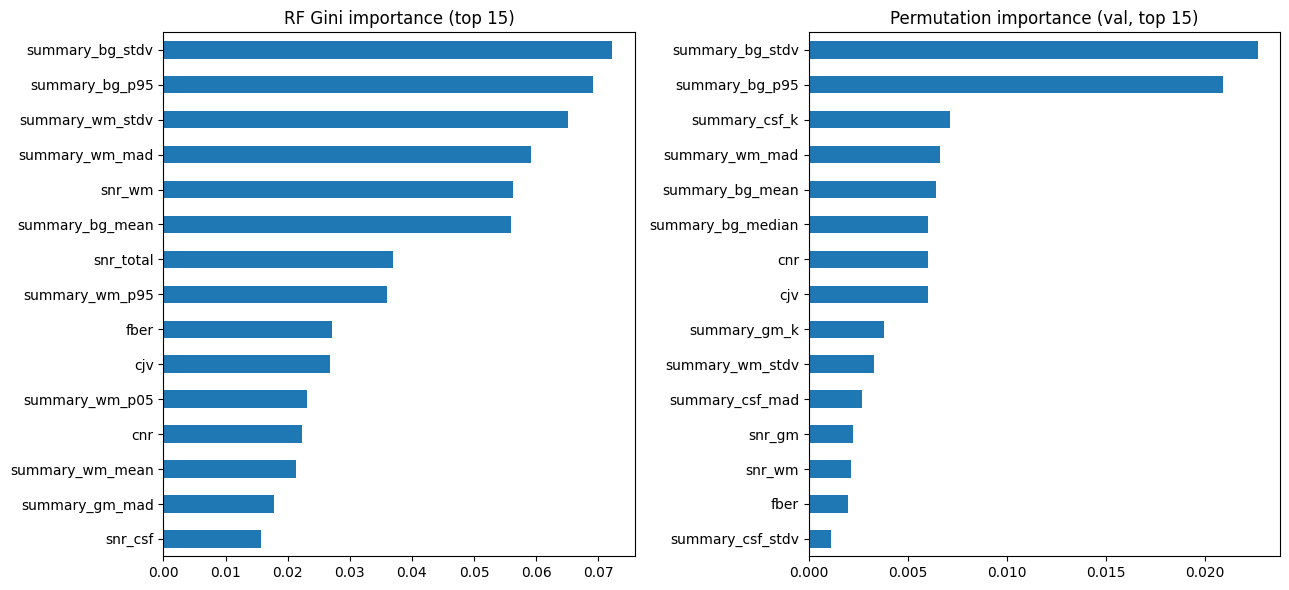

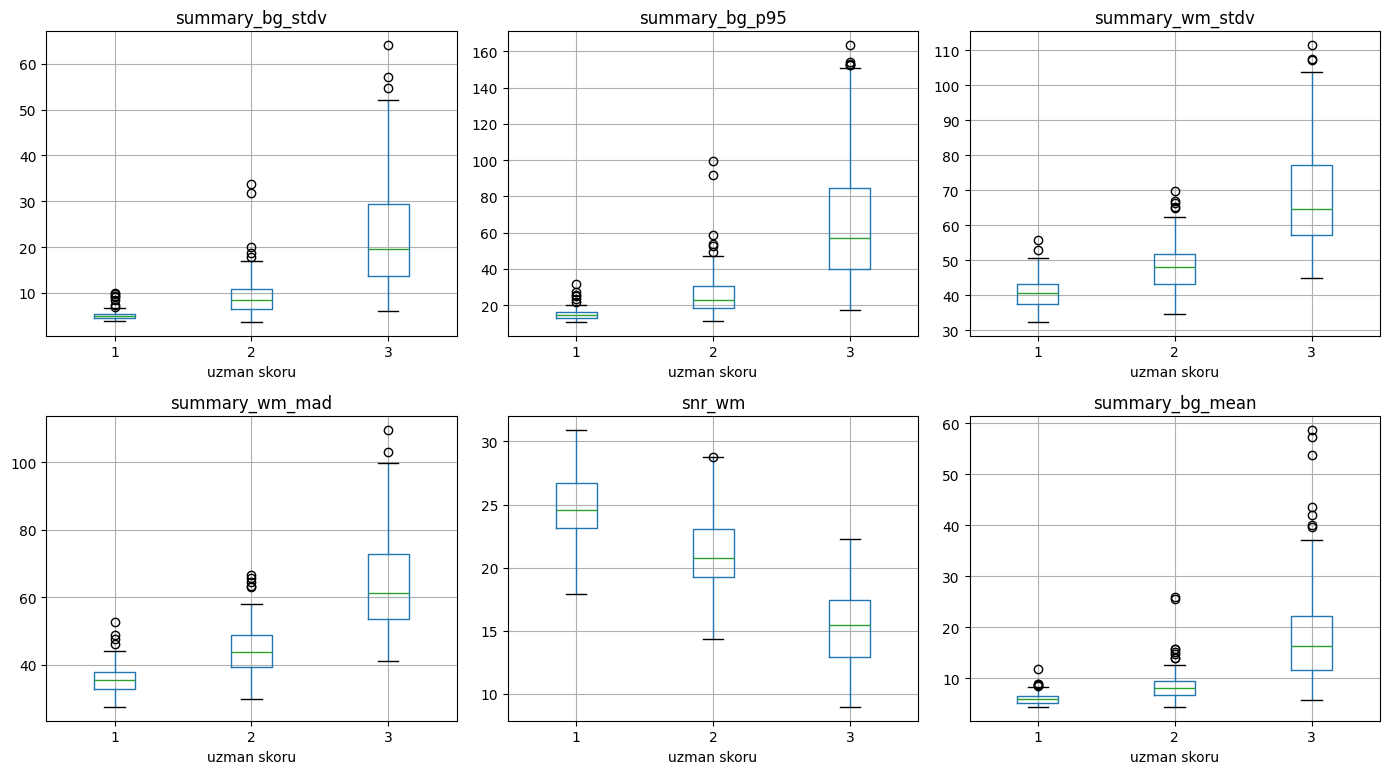

In [5]:
from sklearn.inspection import permutation_importance
from scipy.cluster import hierarchy
from scipy.spatial.distance import squareform
import matplotlib.pyplot as plt

FIG = f'{ROOT}/figures'
rf = fitted['RF']

# 1) Üç farklı önem ölçüsü
gini = pd.Series(rf[-1].feature_importances_, index=FEATS)
perm = permutation_importance(rf, va[FEATS], va.label, scoring='balanced_accuracy',
                              n_repeats=50, random_state=SEED, n_jobs=-1)
perm = pd.Series(perm.importances_mean, index=FEATS)
rho  = df[FEATS + ['score']].corr(method='spearman')['score'].drop('score')
imp = pd.DataFrame({'gini': gini, 'perm_val': perm, 'spearman_vs_score': rho}).sort_values('gini', ascending=False)
print('=== İlk 20 (Gini sırasına göre) ===\n', imp.head(20).round(3))
imp.to_csv(f'{ROOT}/results/feature_importance.csv')

# 2) Korelasyon kümeleri (|rho| > ~0.8 olanlar aynı grupta)
X = df[FEATS].fillna(df[FEATS].median())
C = np.nan_to_num(X.corr(method='spearman').values); np.fill_diagonal(C, 1)
link = hierarchy.linkage(squareform(1 - np.abs(C), checks=False), method='average')
clusters = pd.Series(hierarchy.fcluster(link, t=0.2, criterion='distance'), index=FEATS)
reps = [gini[clusters[clusters == c].index].idxmax() for c in clusters.unique()]
print(f'\n68 özellik -> {clusters.nunique()} korelasyon kümesi')
for c in clusters.unique():
    members = clusters[clusters == c].index.tolist()
    if len(members) > 1:
        print(f'  [{gini[members].idxmax()}] <- {members}')

# 3) Sadece temsilcilerle RF: performans korunuyor mu?
cv = []
for a, b in StratifiedGroupKFold(5, shuffle=True, random_state=SEED).split(trva, trva.label, groups=trva.subject):
    m = make_models()['RF'].fit(trva.iloc[a][reps], trva.iloc[a].label)
    cv.append(evaluate(trva.iloc[b].label, m.predict_proba(trva.iloc[b][reps]))['bal_acc'])
m_red = make_models()['RF'].fit(tr[reps], tr.label)
print(f'\nRF ({len(reps)} temsilci) CV: {np.mean(cv):.3f} ± {np.std(cv):.3f} | TEST:',
      {k: round(v, 3) for k, v in evaluate(te.label, m_red.predict_proba(te[reps])).items()})

# 4) Grafikler
fig, ax = plt.subplots(1, 2, figsize=(13, 6))
imp['gini'].head(15)[::-1].plot.barh(ax=ax[0], title='RF Gini importance (top 15)')
imp.sort_values('perm_val', ascending=False)['perm_val'].head(15)[::-1].plot.barh(ax=ax[1], title='Permutation importance (val, top 15)')
plt.tight_layout(); plt.savefig(f'{FIG}/feature_importance.png', dpi=150); plt.show()

top6 = imp.head(6).index
fig, axs = plt.subplots(2, 3, figsize=(14, 8))
for a, f in zip(axs.flat, top6):
    df.boxplot(column=f, by='score', ax=a); a.set_title(f); a.set_xlabel('uzman skoru')
plt.suptitle(''); plt.tight_layout(); plt.savefig(f'{FIG}/top_features_by_score.png', dpi=150); plt.show()

sub-000103_acq-standard_T1w.nii.gz (192, 256, 256) [1. 1. 1.]
sub-000103_acq-headmotion1_T1w.nii.gz (192, 256, 256) [1. 1. 1.]
sub-000103_acq-headmotion2_T1w.nii.gz (192, 256, 256) [1. 1. 1.]
0/436  1s
50/436  26s
100/436  51s
150/436  77s
200/436  103s
250/436  129s
300/436  155s
350/436  181s
400/436  207s
Bitti. Dosya sayısı: 436


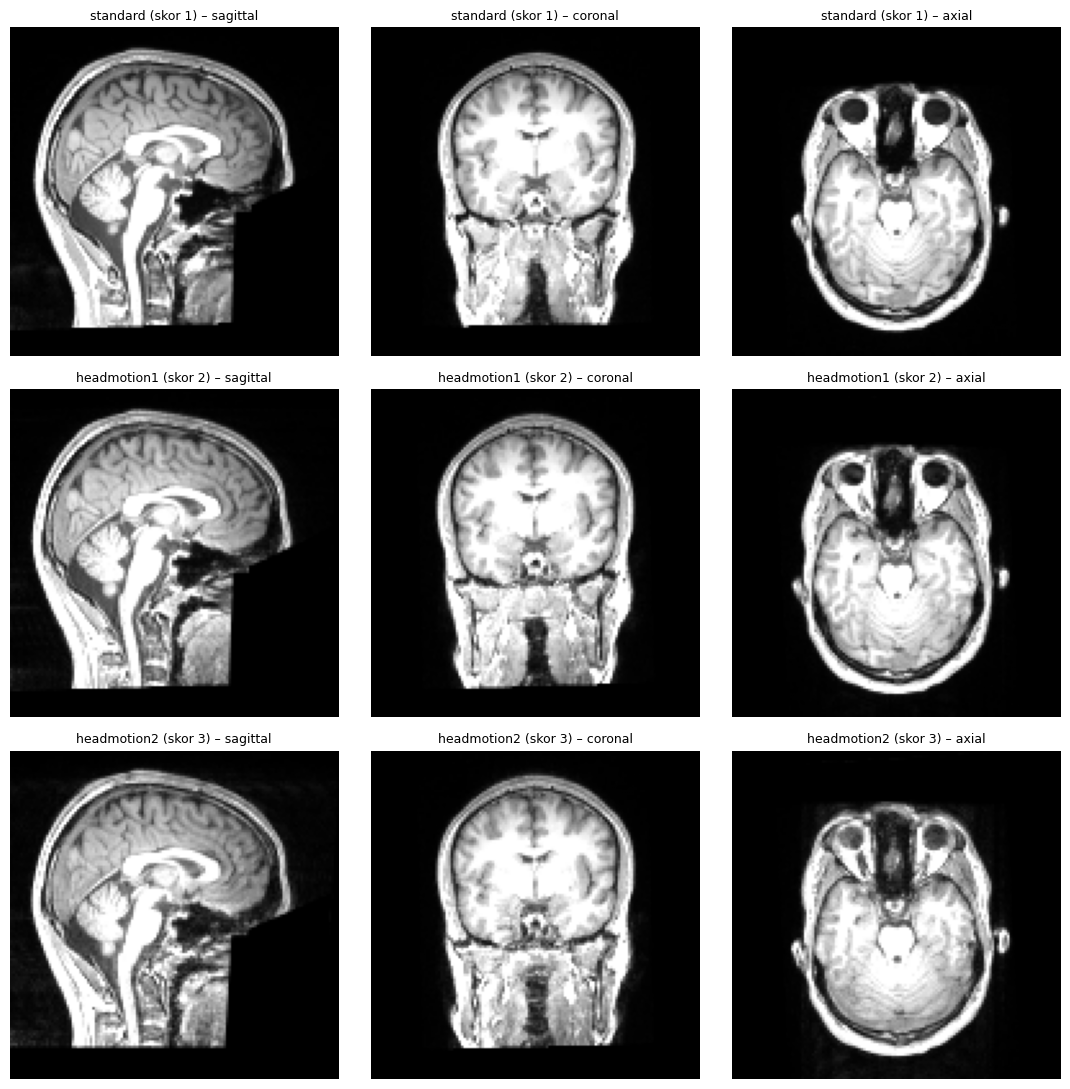

In [6]:
import nibabel as nib, numpy as np, pandas as pd, torch, torch.nn.functional as F, os, time
import matplotlib.pyplot as plt

ROOT = '/content/drive/MyDrive/PIMI_MRART'
CACHE = f'{ROOT}/cache128'; os.makedirs(CACHE, exist_ok=True)
SIZE = 128
df = pd.read_csv(f'{ROOT}/master_table.csv')

# Önce birkaç görüntünün ham boyutuna bakalım
for p in df.path[:3]:
    img = nib.as_closest_canonical(nib.load(p))
    print(os.path.basename(p), img.shape, np.round(img.header.get_zooms(), 2))

def preprocess(path, size=SIZE):
    img = nib.as_closest_canonical(nib.load(path))
    v = img.get_fdata(dtype=np.float32)
    v = np.clip(v / (np.percentile(v, 99.5) + 1e-6), 0, 1)       # yoğunluk normalizasyonu (arka plan korunur)
    m = max(v.shape)                                            # oranı korumak için küpe pad
    pads = [((m - s) // 2, m - s - (m - s) // 2) for s in v.shape]
    v = np.pad(v, pads, mode='constant')
    t = torch.from_numpy(v)[None, None]
    t = F.interpolate(t, size=(size,) * 3, mode='trilinear', align_corners=False)
    return t[0, 0].numpy().astype(np.float16)

t0 = time.time()
for i, r in df.iterrows():
    out = f'{CACHE}/{r.bids_name}.npy'
    if not os.path.exists(out):                                  # yarıda kalırsa kaldığı yerden devam eder
        np.save(out, preprocess(r.path))
    if i % 50 == 0: print(f'{i}/{len(df)}  {time.time() - t0:.0f}s')
print('Bitti. Dosya sayısı:', len(os.listdir(CACHE)))

# Kontrol: aynı katılımcının 3 koşulu, 3 düzlem
sub = df.groupby('subject').filter(lambda g: len(g) == 3).subject.iloc[0]
rows = df[df.subject == sub].sort_values('acq', key=lambda s: s.map({'standard': 0, 'headmotion1': 1, 'headmotion2': 2}))
fig, ax = plt.subplots(3, 3, figsize=(11, 11))
for i, (_, r) in enumerate(rows.iterrows()):
    v = np.load(f'{CACHE}/{r.bids_name}.npy').astype(np.float32); c = SIZE // 2
    for j, (sl, name) in enumerate([(v[c, :, :], 'sagittal'), (v[:, c, :], 'coronal'), (v[:, :, c], 'axial')]):
        ax[i, j].imshow(np.rot90(sl), cmap='gray', vmin=0, vmax=0.6); ax[i, j].axis('off')
        ax[i, j].set_title(f'{r.acq} (skor {r.score}) – {name}', fontsize=9)
plt.tight_layout(); plt.savefig(f'{ROOT}/figures/cache_check_{sub}.png', dpi=130); plt.show()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Hacimler RAM'e yükleniyor...
Downloading: "https://download.pytorch.org/models/r3d_18-b3b3357e.pth" to /root/.cache/torch/hub/checkpoints/r3d_18-b3b3357e.pth


100%|██████████| 127M/127M [00:00<00:00, 233MB/s]


Sınıf sayıları (train): [ 81  67 132] | loss ağırlıkları: [1.15 1.39 0.71]


/tmp/ipykernel_3979/3750871040.py:60: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()


ep  1 | tr_loss 0.816 tr_acc 0.654 | val_loss 0.374 val_bacc 0.874 val_kappa 0.911 | 41s  ★ kaydedildi
ep  2 | tr_loss 0.737 tr_acc 0.692 | val_loss 0.495 val_bacc 0.891 val_kappa 0.944 | 38s  ★ kaydedildi
ep  3 | tr_loss 0.689 tr_acc 0.731 | val_loss 0.419 val_bacc 0.874 val_kappa 0.911 | 38s
ep  4 | tr_loss 0.641 tr_acc 0.740 | val_loss 0.590 val_bacc 0.721 val_kappa 0.850 | 38s
ep  5 | tr_loss 0.622 tr_acc 0.754 | val_loss 0.357 val_bacc 0.901 val_kappa 0.943 | 38s  ★ kaydedildi
ep  6 | tr_loss 0.574 tr_acc 0.767 | val_loss 0.455 val_bacc 0.846 val_kappa 0.899 | 38s
ep  7 | tr_loss 0.573 tr_acc 0.773 | val_loss 0.727 val_bacc 0.599 val_kappa 0.802 | 38s
ep  8 | tr_loss 0.598 tr_acc 0.768 | val_loss 0.374 val_bacc 0.922 val_kappa 0.952 | 38s  ★ kaydedildi
ep  9 | tr_loss 0.544 tr_acc 0.799 | val_loss 0.453 val_bacc 0.777 val_kappa 0.876 | 38s
ep 10 | tr_loss 0.542 tr_acc 0.783 | val_loss 0.393 val_bacc 0.844 val_kappa 0.878 | 38s
ep 11 | tr_loss 0.545 tr_acc 0.778 | val_loss 0.678 va

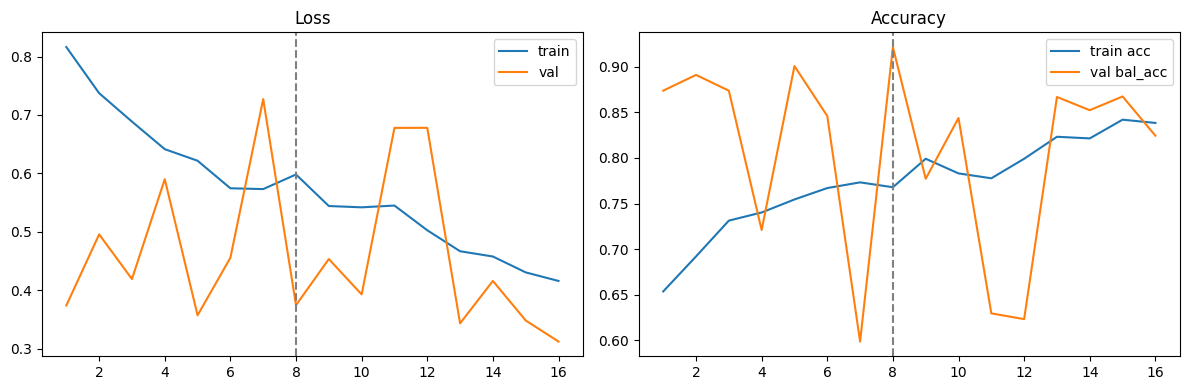


Best epoch: 8
 {
 "val": {
  "bal_acc": 0.922,
  "macro_f1": 0.917,
  "auroc_ovr": 0.967,
  "qw_kappa": 0.952
 },
 "test": {
  "bal_acc": 0.812,
  "macro_f1": 0.802,
  "auroc_ovr": 0.931,
  "qw_kappa": 0.873
 }
}
              precision    recall  f1-score   support

         iyi      0.750     0.960     0.842        25
        orta      0.727     0.615     0.667        26
        kötü      0.939     0.861     0.899        36

    accuracy                          0.816        87
   macro avg      0.806     0.812     0.802        87
weighted avg      0.822     0.816     0.813        87

Confusion matrix (test):
 [[24  1  0]
 [ 8 16  2]
 [ 0  5 31]]


In [7]:
from google.colab import drive; drive.mount('/content/drive')
import os, time, random, json, numpy as np, pandas as pd, torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision.models.video import r3d_18, R3D_18_Weights
from sklearn.metrics import (balanced_accuracy_score, f1_score, roc_auc_score,
                             cohen_kappa_score, confusion_matrix, classification_report)
import matplotlib.pyplot as plt

# ---------------- CONFIG ----------------
ROOT  = '/content/drive/MyDrive/PIMI_MRART'
CACHE = f'{ROOT}/cache128'
AUG   = 'flip_rot90'            # 'none' | 'flip' | 'flip_rot90'  (ablation için değiştir)
REPEATS = 4 if AUG != 'none' else 1
SEED, BS, LR, MAX_EP, PATIENCE = 42, 4, 1e-4, 40, 8
RUN = f'r3d18_{AUG}'
for d in ['models', 'results', 'figures']: os.makedirs(f'{ROOT}/{d}', exist_ok=True)
# ----------------------------------------

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_all(SEED)
dev = 'cuda'
df = pd.read_csv(f'{ROOT}/master_table.csv')
print('Hacimler RAM\'e yükleniyor...')
vols = {b: np.load(f'{CACHE}/{b}.npy') for b in df.bids_name}   # ~0.9 GB float16

class MRDataset(Dataset):
    def __init__(s, d, aug='none', repeats=1):
        s.names, s.y, s.aug, s.rep = d.bids_name.tolist(), d.label.tolist(), aug, repeats
    def __len__(s): return len(s.names) * s.rep
    def __getitem__(s, i):
        i %= len(s.names); v = vols[s.names[i]]
        if s.aug in ('flip', 'flip_rot90'):
            for ax in range(3):
                if random.random() < 0.5: v = np.flip(v, ax)
        if s.aug == 'flip_rot90':
            v = np.rot90(v, random.randint(0, 3), random.choice([(0, 1), (0, 2), (1, 2)]))
        return torch.from_numpy(np.ascontiguousarray(v, dtype=np.float32))[None], s.y[i]

tr, va, te = (df[df.split == s] for s in ['train', 'val', 'test'])
g = torch.Generator().manual_seed(SEED)
dl_tr = DataLoader(MRDataset(tr, AUG, REPEATS), batch_size=BS, shuffle=True, num_workers=2, generator=g, drop_last=True)
dl_va = DataLoader(MRDataset(va), batch_size=BS, num_workers=2)
dl_te = DataLoader(MRDataset(te), batch_size=BS, num_workers=2)

class Net(nn.Module):
    def __init__(s):
        super().__init__()
        s.m = r3d_18(weights=R3D_18_Weights.KINETICS400_V1)
        s.m.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(512, 3))
    def forward(s, x): return s.m(x.repeat(1, 3, 1, 1, 1))   # 1 kanal -> 3 kanal

model = Net().to(dev)
cnt = np.bincount(tr.label, minlength=3)
w = torch.tensor(len(tr) / (3 * cnt), dtype=torch.float32, device=dev)
print('Sınıf sayıları (train):', cnt, '| loss ağırlıkları:', w.cpu().numpy().round(2))
crit = nn.CrossEntropyLoss(weight=w)
opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode='max', factor=0.5, patience=3)
scaler = torch.cuda.amp.GradScaler()

@torch.no_grad()
def predict(dl, tta=False):
    model.eval(); P, Y, L = [], [], 0.0
    for x, y in dl:
        x, y = x.to(dev), y.to(dev)
        with torch.autocast('cuda', dtype=torch.float16):
            logit = model(x)
            if tta: logit = (logit + model(torch.flip(x, dims=[2]))) / 2   # sol-sağ flip
        L += crit(logit.float(), y).item() * len(y)
        P.append(torch.softmax(logit.float(), 1).cpu()); Y.append(y.cpu())
    return torch.cat(P).numpy(), torch.cat(Y).numpy(), L / len(dl.dataset)

def evaluate(y, proba):
    p = proba.argmax(1)
    return {'bal_acc': balanced_accuracy_score(y, p), 'macro_f1': f1_score(y, p, average='macro'),
            'auroc_ovr': roc_auc_score(y, proba, multi_class='ovr'),
            'qw_kappa': cohen_kappa_score(y, p, weights='quadratic')}

hist, best, wait = [], -1, 0
for ep in range(1, MAX_EP + 1):
    model.train(); t0 = time.time(); tl, tc, tn = 0, 0, 0
    for x, y in dl_tr:
        x, y = x.to(dev), y.to(dev); opt.zero_grad()
        with torch.autocast('cuda', dtype=torch.float16):
            out = model(x); loss = crit(out, y)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        tl += loss.item() * len(y); tc += (out.argmax(1) == y).sum().item(); tn += len(y)
    pv, yv, vl = predict(dl_va); m = evaluate(yv, pv)
    sched.step(m['bal_acc'])
    hist.append({'epoch': ep, 'train_loss': tl / tn, 'train_acc': tc / tn, 'val_loss': vl, **{f'val_{k}': v for k, v in m.items()}})
    flag = ''
    if m['bal_acc'] > best:
        best, wait, flag = m['bal_acc'], 0, '  ★ kaydedildi'
        torch.save(model.state_dict(), f'{ROOT}/models/{RUN}_best.pt')
    else:
        wait += 1
    print(f"ep {ep:2d} | tr_loss {tl/tn:.3f} tr_acc {tc/tn:.3f} | val_loss {vl:.3f} "
          f"val_bacc {m['bal_acc']:.3f} val_kappa {m['qw_kappa']:.3f} | {time.time()-t0:.0f}s{flag}")
    pd.DataFrame(hist).to_csv(f'{ROOT}/results/{RUN}_history.csv', index=False)
    if wait >= PATIENCE:
        print(f'Early stopping: {PATIENCE} epoch boyunca iyileşme yok.'); break

# --- Öğrenme eğrileri ---
h = pd.DataFrame(hist)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(h.epoch, h.train_loss, label='train'); ax[0].plot(h.epoch, h.val_loss, label='val'); ax[0].set_title('Loss'); ax[0].legend()
ax[1].plot(h.epoch, h.train_acc, label='train acc'); ax[1].plot(h.epoch, h.val_bal_acc, label='val bal_acc'); ax[1].set_title('Accuracy'); ax[1].legend()
best_ep = h.loc[h.val_bal_acc.idxmax(), 'epoch']
for a in ax: a.axvline(best_ep, ls='--', c='gray')
plt.tight_layout(); plt.savefig(f'{ROOT}/figures/{RUN}_curves.png', dpi=150); plt.show()

# --- En iyi ağırlıklarla final değerlendirme ---
model.load_state_dict(torch.load(f'{ROOT}/models/{RUN}_best.pt'))
out = {}
for name, dl, d in [('val', dl_va, va), ('test', dl_te, te)]:
    p, y, _ = predict(dl, tta=True); out[name] = {k: round(v, 3) for k, v in evaluate(y, p).items()}
    pd.DataFrame({'bids_name': d.bids_name.values, 'label': y, 'pred': p.argmax(1),
                  'p_iyi': p[:, 0], 'p_orta': p[:, 1], 'p_kotu': p[:, 2]}).to_csv(f'{ROOT}/results/{RUN}_{name}_preds.csv', index=False)
print(f'\nBest epoch: {best_ep}\n', json.dumps(out, indent=1))
print(classification_report(y, p.argmax(1), target_names=['iyi', 'orta', 'kötü'], digits=3))
print('Confusion matrix (test):\n', confusion_matrix(y, p.argmax(1)))
json.dump({'run': RUN, 'best_epoch': int(best_ep), **out}, open(f'{ROOT}/results/{RUN}_metrics.json', 'w'), indent=1)

In [8]:
import numpy as np, pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import balanced_accuracy_score, cohen_kappa_score

ROOT, SEED = '/content/drive/MyDrive/PIMI_MRART', 42
df = pd.read_csv(f'{ROOT}/master_table.csv')
FEATS = [c for c in df.columns if c not in ['bids_name','score','subject','acq','path','label','split']]
tr, te = df[df.split == 'train'], df[df.split == 'test'].reset_index(drop=True)

rf = make_pipeline(SimpleImputer(strategy='median'),
                   RandomForestClassifier(n_estimators=500, min_samples_leaf=2, class_weight='balanced',
                                          random_state=SEED, n_jobs=-1)).fit(tr[FEATS], tr.label)
te['rf_pred'] = rf.predict(te[FEATS])
cnn = pd.read_csv(f'{ROOT}/results/r3d18_flip_rot90_test_preds.csv')[['bids_name', 'pred']].rename(columns={'pred': 'cnn_pred'})
te = te.merge(cnn, on='bids_name')

subs = te.subject.unique(); rng = np.random.default_rng(SEED); B = 2000
res = {k: [] for k in ['rf_bacc', 'cnn_bacc', 'diff_bacc', 'rf_kappa', 'cnn_kappa', 'diff_kappa']}
for _ in range(B):
    s = rng.choice(subs, len(subs), replace=True)
    d = pd.concat([te[te.subject == x] for x in s])
    if d.label.nunique() < 3: continue
    rb, cb = balanced_accuracy_score(d.label, d.rf_pred), balanced_accuracy_score(d.label, d.cnn_pred)
    rk, ck = (cohen_kappa_score(d.label, d[p], weights='quadratic') for p in ['rf_pred', 'cnn_pred'])
    for k, v in zip(res, [rb, cb, cb - rb, rk, ck, ck - rk]): res[k].append(v)

ci = lambda a: f'{np.mean(a):.3f}  [%95 GA: {np.percentile(a, 2.5):.3f} – {np.percentile(a, 97.5):.3f}]'
for k, v in res.items(): print(f'{k:11s} {ci(v)}')
print(f"\nP(CNN > RF, bal_acc) = {np.mean(np.array(res['diff_bacc']) > 0):.3f}")
pd.DataFrame(res).to_csv(f'{ROOT}/results/bootstrap_rf_vs_cnn.csv', index=False)

rf_bacc     0.757  [%95 GA: 0.662 – 0.838]
cnn_bacc    0.812  [%95 GA: 0.733 – 0.886]
diff_bacc   0.055  [%95 GA: -0.019 – 0.128]
rf_kappa    0.840  [%95 GA: 0.766 – 0.905]
cnn_kappa   0.872  [%95 GA: 0.811 – 0.928]
diff_kappa  0.032  [%95 GA: -0.014 – 0.078]

P(CNN > RF, bal_acc) = 0.929


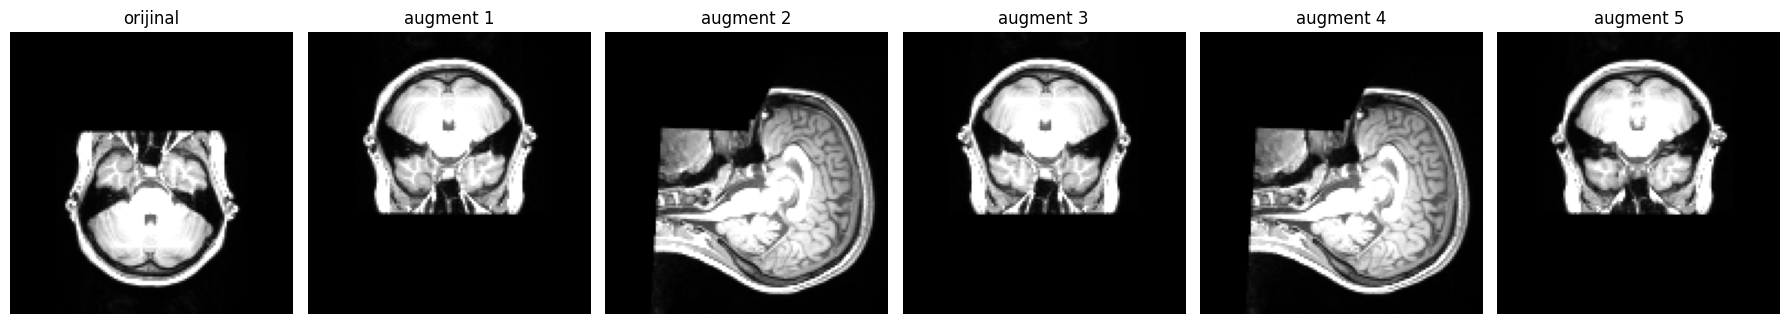

In [9]:
import matplotlib.pyplot as plt, random
random.seed(0)
name = tr.bids_name.iloc[0]
ds = MRDataset(tr[tr.bids_name == name], 'flip_rot90')
fig, ax = plt.subplots(1, 6, figsize=(18, 3.2))
for i in range(6):
    x = (vols[name] if i == 0 else ds[0][0][0].numpy()).astype('float32')
    ax[i].imshow(x[:, :, 64].T, cmap='gray', origin='lower', vmin=0, vmax=0.6); ax[i].axis('off')
    ax[i].set_title('orijinal' if i == 0 else f'augment {i}')
plt.tight_layout(); plt.savefig(f'{ROOT}/figures/augmentation_examples.png', dpi=150); plt.show()

In [10]:
import json, glob, os, pandas as pd
ROOT = '/content/drive/MyDrive/PIMI_MRART'
rows = []
for f in glob.glob(f'{ROOT}/results/r3d18_*_metrics.json'):
    m = json.load(open(f)); run = m['run']
    aug = run.replace('r3d18_', '').rsplit('_s', 1)[0] if '_s' in run else run.replace('r3d18_', '')
    seed = int(run.rsplit('_s', 1)[1]) if '_s' in run else 42
    rows.append({'aug': aug, 'seed': seed, 'best_epoch': m['best_epoch'],
                 **{f'test_{k}': v for k, v in m['test'].items()}})
r = pd.DataFrame(rows).sort_values(['aug', 'seed'])
print(r.to_string(index=False))
summ = r.groupby('aug')[['test_bal_acc', 'test_macro_f1', 'test_auroc_ovr', 'test_qw_kappa']].agg(['mean', 'std']).round(3)
print('\n', summ)
summ.to_csv(f'{ROOT}/results/ablation_summary.csv')


       aug  seed  best_epoch  test_bal_acc  test_macro_f1  test_auroc_ovr  test_qw_kappa
flip_rot90    42           8         0.812          0.802           0.931          0.873

            test_bal_acc     test_macro_f1     test_auroc_ovr     test_qw_kappa    
                   mean std          mean std           mean std          mean std
aug                                                                               
flip_rot90        0.812 NaN         0.802 NaN          0.931 NaN         0.873 NaN


In [11]:
from google.colab import drive; drive.mount('/content/drive')
import os, time, random, json, glob, numpy as np, pandas as pd, torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision.models.video import r3d_18, R3D_18_Weights
from sklearn.metrics import balanced_accuracy_score, f1_score, roc_auc_score, cohen_kappa_score

ROOT, CACHE = '/content/drive/MyDrive/PIMI_MRART', '/content/drive/MyDrive/PIMI_MRART/cache128'
BS, LR, MAX_EP, PATIENCE = 4, 1e-4, 40, 8
EXPERIMENTS = [('flip_rot90', 1), ('flip_rot90', 2),
               ('flip', 42), ('flip', 1), ('flip', 2),
               ('none', 42), ('none', 1), ('none', 2)]
dev = 'cuda'
df = pd.read_csv(f'{ROOT}/master_table.csv')
tr, va, te = (df[df.split == s] for s in ['train', 'val', 'test'])
if 'vols' not in globals():
    print("Hacimler RAM'e yükleniyor..."); vols = {b: np.load(f'{CACHE}/{b}.npy') for b in df.bids_name}

class MRDataset(Dataset):
    def __init__(s, d, aug='none', repeats=1):
        s.names, s.y, s.aug, s.rep = d.bids_name.tolist(), d.label.tolist(), aug, repeats
    def __len__(s): return len(s.names) * s.rep
    def __getitem__(s, i):
        i %= len(s.names); v = vols[s.names[i]]
        if s.aug in ('flip', 'flip_rot90'):
            for ax in range(3):
                if random.random() < 0.5: v = np.flip(v, ax)
        if s.aug == 'flip_rot90':
            v = np.rot90(v, random.randint(0, 3), random.choice([(0, 1), (0, 2), (1, 2)]))
        return torch.from_numpy(np.ascontiguousarray(v, dtype=np.float32))[None], s.y[i]

class Net(nn.Module):
    def __init__(s):
        super().__init__(); s.m = r3d_18(weights=R3D_18_Weights.KINETICS400_V1)
        s.m.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(512, 3))
    def forward(s, x): return s.m(x.repeat(1, 3, 1, 1, 1))

def evaluate(y, proba):
    p = proba.argmax(1)
    return {'bal_acc': balanced_accuracy_score(y, p), 'macro_f1': f1_score(y, p, average='macro'),
            'auroc_ovr': roc_auc_score(y, proba, multi_class='ovr'),
            'qw_kappa': cohen_kappa_score(y, p, weights='quadratic')}

def run(AUG, SEED):
    RUN = f'r3d18_{AUG}_s{SEED}'
    if os.path.exists(f'{ROOT}/results/{RUN}_metrics.json'):
        print(f'{RUN} zaten var, atlanıyor.'); return
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
    rep = 4 if AUG != 'none' else 1
    dl_tr = DataLoader(MRDataset(tr, AUG, rep), batch_size=BS, shuffle=True, num_workers=2,
                       generator=torch.Generator().manual_seed(SEED), drop_last=True)
    dl_va = DataLoader(MRDataset(va), batch_size=BS, num_workers=2)
    dl_te = DataLoader(MRDataset(te), batch_size=BS, num_workers=2)
    model = Net().to(dev)
    cnt = np.bincount(tr.label, minlength=3)
    crit = nn.CrossEntropyLoss(weight=torch.tensor(len(tr) / (3 * cnt), dtype=torch.float32, device=dev))
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode='max', factor=0.5, patience=3)
    scaler = torch.amp.GradScaler('cuda')

    @torch.no_grad()
    def predict(dl, tta=False):
        model.eval(); P, Y, L = [], [], 0.0
        for x, y in dl:
            x, y = x.to(dev), y.to(dev)
            with torch.autocast('cuda', dtype=torch.float16):
                lo = model(x)
                if tta: lo = (lo + model(torch.flip(x, dims=[2]))) / 2
            L += crit(lo.float(), y).item() * len(y)
            P.append(torch.softmax(lo.float(), 1).cpu()); Y.append(y.cpu())
        return torch.cat(P).numpy(), torch.cat(Y).numpy(), L / len(dl.dataset)

    hist, best, wait, best_ep = [], -1, 0, 0
    for ep in range(1, MAX_EP + 1):
        model.train(); t0 = time.time(); tl = tc = tn = 0
        for x, y in dl_tr:
            x, y = x.to(dev), y.to(dev); opt.zero_grad()
            with torch.autocast('cuda', dtype=torch.float16):
                out = model(x); loss = crit(out, y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tl += loss.item() * len(y); tc += (out.argmax(1) == y).sum().item(); tn += len(y)
        pv, yv, vl = predict(dl_va); m = evaluate(yv, pv); sched.step(m['bal_acc'])
        hist.append({'epoch': ep, 'train_loss': tl / tn, 'train_acc': tc / tn, 'val_loss': vl,
                     **{f'val_{k}': v for k, v in m.items()}})
        if m['bal_acc'] > best:
            best, wait, best_ep = m['bal_acc'], 0, ep
            torch.save(model.state_dict(), f'{ROOT}/models/{RUN}_best.pt')
        else:
            wait += 1
        print(f"[{RUN}] ep {ep:2d} | tr_acc {tc/tn:.3f} | val_loss {vl:.3f} val_bacc {m['bal_acc']:.3f} | {time.time()-t0:.0f}s")
        if wait >= PATIENCE: break
    pd.DataFrame(hist).to_csv(f'{ROOT}/results/{RUN}_history.csv', index=False)

    model.load_state_dict(torch.load(f'{ROOT}/models/{RUN}_best.pt'))
    res = {}
    for name, dl, d in [('val', dl_va, va), ('test', dl_te, te)]:
        p, y, _ = predict(dl, tta=True); res[name] = {k: round(v, 3) for k, v in evaluate(y, p).items()}
        pd.DataFrame({'bids_name': d.bids_name.values, 'label': y, 'pred': p.argmax(1), 'p_iyi': p[:, 0],
                      'p_orta': p[:, 1], 'p_kotu': p[:, 2]}).to_csv(f'{ROOT}/results/{RUN}_{name}_preds.csv', index=False)
    json.dump({'run': RUN, 'best_epoch': best_ep, **res}, open(f'{ROOT}/results/{RUN}_metrics.json', 'w'), indent=1)
    print(f'>>> {RUN} bitti | best epoch {best_ep} | TEST {res["test"]}\n')
    del model; torch.cuda.empty_cache()

for aug, seed in EXPERIMENTS:
    run(aug, seed)

# ---- Özet tablo ----
rows = []
for f in glob.glob(f'{ROOT}/results/r3d18_*_metrics.json'):
    m = json.load(open(f)); r = m['run'].replace('r3d18_', '')
    aug, seed = (r.rsplit('_s', 1)[0], int(r.rsplit('_s', 1)[1])) if '_s' in r else (r, 42)
    rows.append({'aug': aug, 'seed': seed, 'best_epoch': m['best_epoch'], **{f'test_{k}': v for k, v in m['test'].items()}})
r = pd.DataFrame(rows).sort_values(['aug', 'seed'])
print(r.to_string(index=False))
summ = r.groupby('aug')[['test_bal_acc', 'test_macro_f1', 'test_auroc_ovr', 'test_qw_kappa']].agg(['mean', 'std']).round(3)
print('\n', summ); summ.to_csv(f'{ROOT}/results/ablation_summary.csv')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[r3d18_flip_rot90_s1] ep  1 | tr_acc 0.649 | val_loss 0.546 val_bacc 0.715 | 38s
[r3d18_flip_rot90_s1] ep  2 | tr_acc 0.704 | val_loss 0.671 val_bacc 0.623 | 38s
[r3d18_flip_rot90_s1] ep  3 | tr_acc 0.731 | val_loss 0.513 val_bacc 0.707 | 38s
[r3d18_flip_rot90_s1] ep  4 | tr_acc 0.735 | val_loss 0.931 val_bacc 0.514 | 38s
[r3d18_flip_rot90_s1] ep  5 | tr_acc 0.747 | val_loss 0.362 val_bacc 0.912 | 39s
[r3d18_flip_rot90_s1] ep  6 | tr_acc 0.761 | val_loss 0.374 val_bacc 0.856 | 38s
[r3d18_flip_rot90_s1] ep  7 | tr_acc 0.778 | val_loss 0.341 val_bacc 0.883 | 38s
[r3d18_flip_rot90_s1] ep  8 | tr_acc 0.765 | val_loss 0.351 val_bacc 0.897 | 38s
[r3d18_flip_rot90_s1] ep  9 | tr_acc 0.779 | val_loss 0.299 val_bacc 0.870 | 38s
[r3d18_flip_rot90_s1] ep 10 | tr_acc 0.811 | val_loss 0.331 val_bacc 0.835 | 38s
[r3d18_flip_rot90_s1] ep 11 | tr_acc 0.816 | val_loss 0.425 v

KeyboardInterrupt: 

In [12]:
from google.colab import drive; drive.mount('/content/drive')
import os, time, random, json, glob, numpy as np, pandas as pd, torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision.models.video import r3d_18, R3D_18_Weights
from sklearn.metrics import balanced_accuracy_score, f1_score, roc_auc_score, cohen_kappa_score

# ---------------- CONFIG ----------------
ROOT  = '/content/drive/MyDrive/PIMI_MRART'
CACHE = f'{ROOT}/cache128'
BS, LR, MAX_EP, PATIENCE = 4, 1e-4, 40, 8
EXPERIMENTS = [('none', 42), ('flip', 42),            # öncelik: ana ablation
               ('flip', 1), ('none', 1),
               ('flip_rot90', 2), ('flip', 2), ('none', 2)]
# ----------------------------------------
for d in ['models', 'results', 'figures']: os.makedirs(f'{ROOT}/{d}', exist_ok=True)
dev = 'cuda'
df = pd.read_csv(f'{ROOT}/master_table.csv')
tr, va, te = (df[df.split == s] for s in ['train', 'val', 'test'])
if 'vols' not in globals():
    print("Hacimler RAM'e yükleniyor...")
    vols = {b: np.load(f'{CACHE}/{b}.npy') for b in df.bids_name}

class MRDataset(Dataset):
    def __init__(s, d, aug='none', repeats=1):
        s.names, s.y, s.aug, s.rep = d.bids_name.tolist(), d.label.tolist(), aug, repeats
    def __len__(s): return len(s.names) * s.rep
    def __getitem__(s, i):
        i %= len(s.names); v = vols[s.names[i]]
        if s.aug in ('flip', 'flip_rot90'):
            for ax in range(3):
                if random.random() < 0.5: v = np.flip(v, ax)
        if s.aug == 'flip_rot90':
            v = np.rot90(v, random.randint(0, 3), random.choice([(0, 1), (0, 2), (1, 2)]))
        return torch.from_numpy(np.ascontiguousarray(v, dtype=np.float32))[None], s.y[i]

class Net(nn.Module):
    def __init__(s):
        super().__init__()
        s.m = r3d_18(weights=R3D_18_Weights.KINETICS400_V1)
        s.m.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(512, 3))
    def forward(s, x): return s.m(x.repeat(1, 3, 1, 1, 1))

def evaluate(y, proba):
    p = proba.argmax(1)
    return {'bal_acc': float(balanced_accuracy_score(y, p)),
            'macro_f1': float(f1_score(y, p, average='macro')),
            'auroc_ovr': float(roc_auc_score(y, proba, multi_class='ovr')),
            'qw_kappa': float(cohen_kappa_score(y, p, weights='quadratic'))}

def run(AUG, SEED):
    RUN = f'r3d18_{AUG}_s{SEED}'
    if os.path.exists(f'{ROOT}/results/{RUN}_metrics.json'):
        print(f'{RUN} zaten var, atlanıyor.'); return
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
    rep = 4 if AUG != 'none' else 1
    dl_tr = DataLoader(MRDataset(tr, AUG, rep), batch_size=BS, shuffle=True, num_workers=2,
                       generator=torch.Generator().manual_seed(SEED), drop_last=True)
    dl_va = DataLoader(MRDataset(va), batch_size=BS, num_workers=2)
    dl_te = DataLoader(MRDataset(te), batch_size=BS, num_workers=2)

    model = Net().to(dev)
    cnt = np.bincount(tr.label, minlength=3)
    crit = nn.CrossEntropyLoss(weight=torch.tensor(len(tr) / (3 * cnt), dtype=torch.float32, device=dev))
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode='max', factor=0.5, patience=3)
    scaler = torch.amp.GradScaler('cuda')

    @torch.no_grad()
    def predict(dl, tta=False):
        model.eval(); P, Y, L = [], [], 0.0
        for x, y in dl:
            x, y = x.to(dev), y.to(dev)
            with torch.autocast('cuda', dtype=torch.float16):
                lo = model(x)
                if tta: lo = (lo + model(torch.flip(x, dims=[2]))) / 2
            L += crit(lo.float(), y).item() * len(y)
            P.append(torch.softmax(lo.float(), 1).cpu()); Y.append(y.cpu())
        return torch.cat(P).numpy(), torch.cat(Y).numpy(), L / len(dl.dataset)

    hist, best, wait, best_ep = [], -1, 0, 0
    for ep in range(1, MAX_EP + 1):
        model.train(); t0 = time.time(); tl = tc = tn = 0
        for x, y in dl_tr:
            x, y = x.to(dev), y.to(dev); opt.zero_grad()
            with torch.autocast('cuda', dtype=torch.float16):
                out = model(x); loss = crit(out, y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tl += loss.item() * len(y); tc += (out.argmax(1) == y).sum().item(); tn += len(y)
        pv, yv, vl = predict(dl_va); m = evaluate(yv, pv); sched.step(m['bal_acc'])
        hist.append({'epoch': ep, 'train_loss': tl / tn, 'train_acc': tc / tn, 'val_loss': vl,
                     **{f'val_{k}': v for k, v in m.items()}})
        flag = ''
        if m['bal_acc'] > best:
            best, wait, best_ep, flag = m['bal_acc'], 0, ep, '  ★'
            torch.save(model.state_dict(), f'{ROOT}/models/{RUN}_best.pt')
        else:
            wait += 1
        print(f"[{RUN}] ep {ep:2d} | tr_acc {tc/tn:.3f} | val_loss {vl:.3f} val_bacc {m['bal_acc']:.3f} | {time.time()-t0:.0f}s{flag}")
        pd.DataFrame(hist).to_csv(f'{ROOT}/results/{RUN}_history.csv', index=False)
        if wait >= PATIENCE: break

    model.load_state_dict(torch.load(f'{ROOT}/models/{RUN}_best.pt'))
    res = {}
    for name, dl, d in [('val', dl_va, va), ('test', dl_te, te)]:
        p, y, _ = predict(dl, tta=True)
        res[name] = {k: round(v, 3) for k, v in evaluate(y, p).items()}
        pd.DataFrame({'bids_name': d.bids_name.values, 'label': y, 'pred': p.argmax(1),
                      'p_iyi': p[:, 0], 'p_orta': p[:, 1], 'p_kotu': p[:, 2]}
                     ).to_csv(f'{ROOT}/results/{RUN}_{name}_preds.csv', index=False)
    json.dump({'run': RUN, 'best_epoch': best_ep, **res},
              open(f'{ROOT}/results/{RUN}_metrics.json', 'w'), indent=1)
    print(f'>>> {RUN} bitti | best epoch {best_ep} | TEST {res["test"]}\n')
    del model; torch.cuda.empty_cache()

for aug, seed in EXPERIMENTS:
    run(aug, seed)

# ---------------- Özet tablo ----------------
rows = []
for f in glob.glob(f'{ROOT}/results/r3d18_*_metrics.json'):
    m = json.load(open(f)); r = m['run'].replace('r3d18_', '')
    aug, seed = (r.rsplit('_s', 1)[0], int(r.rsplit('_s', 1)[1])) if '_s' in r else (r, 42)
    rows.append({'aug': aug, 'seed': seed, 'best_epoch': m['best_epoch'],
                 **{f'test_{k}': v for k, v in m['test'].items()}})
r = pd.DataFrame(rows).sort_values(['aug', 'seed'])
print(r.to_string(index=False))
summ = r.groupby('aug')[['test_bal_acc', 'test_macro_f1', 'test_auroc_ovr', 'test_qw_kappa']].agg(['mean', 'std']).round(3)
print('\n', summ)
summ.to_csv(f'{ROOT}/results/ablation_summary.csv')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[r3d18_none_s42] ep  1 | tr_acc 0.654 | val_loss 1.000 val_bacc 0.563 | 11s  ★
[r3d18_none_s42] ep  2 | tr_acc 0.729 | val_loss 1.302 val_bacc 0.375 | 10s
[r3d18_none_s42] ep  3 | tr_acc 0.696 | val_loss 0.713 val_bacc 0.674 | 11s  ★
[r3d18_none_s42] ep  4 | tr_acc 0.718 | val_loss 0.692 val_bacc 0.740 | 11s  ★
[r3d18_none_s42] ep  5 | tr_acc 0.793 | val_loss 0.384 val_bacc 0.827 | 11s  ★
[r3d18_none_s42] ep  6 | tr_acc 0.804 | val_loss 0.466 val_bacc 0.809 | 10s
[r3d18_none_s42] ep  7 | tr_acc 0.832 | val_loss 0.459 val_bacc 0.843 | 11s  ★
[r3d18_none_s42] ep  8 | tr_acc 0.861 | val_loss 0.385 val_bacc 0.840 | 10s
[r3d18_none_s42] ep  9 | tr_acc 0.907 | val_loss 1.495 val_bacc 0.623 | 10s
[r3d18_none_s42] ep 10 | tr_acc 0.911 | val_loss 0.901 val_bacc 0.676 | 10s
[r3d18_none_s42] ep 11 | tr_acc 0.954 | val_loss 1.310 val_bacc 0.652 | 10s
[r3d18_none_s42] ep 

In [13]:
import glob, numpy as np, pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import balanced_accuracy_score, f1_score, roc_auc_score, cohen_kappa_score, confusion_matrix

ROOT, SEED = '/content/drive/MyDrive/PIMI_MRART', 42
df = pd.read_csv(f'{ROOT}/master_table.csv')
te = df[df.split == 'test'].reset_index(drop=True)
y = te.label.values
P = ['p_iyi', 'p_orta', 'p_kotu']

def ev(p):
    pr = p.argmax(1)
    return {'bal_acc': round(balanced_accuracy_score(y, pr), 3), 'macro_f1': round(f1_score(y, pr, average='macro'), 3),
            'auroc': round(roc_auc_score(y, p, multi_class='ovr'), 3),
            'qw_kappa': round(cohen_kappa_score(y, pr, weights='quadratic'), 3)}

def load(run):
    d = pd.read_csv(f'{ROOT}/results/{run}_test_preds.csv').set_index('bids_name').loc[te.bids_name]
    return d[P].values

runs = {'flip_rot90': ['r3d18_flip_rot90', 'r3d18_flip_rot90_s1', 'r3d18_flip_rot90_s2'],
        'flip': ['r3d18_flip_s42', 'r3d18_flip_s1', 'r3d18_flip_s2'],
        'none': ['r3d18_none_s42', 'r3d18_none_s1', 'r3d18_none_s2']}
probs = {k: [load(r) for r in v if glob.glob(f'{ROOT}/results/{r}_test_preds.csv')] for k, v in runs.items()}

# RF olasılıkları
FEATS = [c for c in df.columns if c not in ['bids_name','score','subject','acq','path','label','split']]
tr = df[df.split == 'train']
rf = make_pipeline(SimpleImputer(strategy='median'),
                   RandomForestClassifier(n_estimators=500, min_samples_leaf=2, class_weight='balanced',
                                          random_state=SEED, n_jobs=-1)).fit(tr[FEATS], tr.label)
p_rf = rf.predict_proba(te[FEATS])

rows = [{'model': 'RF (MRIQC)', 'n': 1, **ev(p_rf)}]
for k, ps in probs.items():
    rows.append({'model': f'CNN {k} – seed ort.', 'n': len(ps), **ev(np.mean(ps, 0))})
all_cnn = np.mean([p for ps in probs.values() for p in ps], 0)
rows.append({'model': 'CNN – tüm modeller', 'n': sum(map(len, probs.values())), **ev(all_cnn)})
rows.append({'model': 'RF + CNN (tümü)', 'n': '-', **ev((p_rf + all_cnn) / 2)})
res = pd.DataFrame(rows); print(res.to_string(index=False))
res.to_csv(f'{ROOT}/results/ensemble_results.csv', index=False)

best = (p_rf + all_cnn) / 2
print('\nRF+CNN confusion matrix (satır=gerçek):\n', confusion_matrix(y, best.argmax(1)))
pd.DataFrame({'bids_name': te.bids_name, 'label': y, 'pred': best.argmax(1), **dict(zip(P, best.T))}
             ).to_csv(f'{ROOT}/results/ensemble_rf_cnn_test_preds.csv', index=False)

                     model n  bal_acc  macro_f1  auroc  qw_kappa
                RF (MRIQC) 1    0.756     0.748  0.897     0.841
CNN flip_rot90 – seed ort. 3    0.818     0.808  0.930     0.883
      CNN flip – seed ort. 3    0.789     0.783  0.912     0.852
      CNN none – seed ort. 3    0.789     0.784  0.919     0.852
        CNN – tüm modeller 9    0.821     0.812  0.923     0.881
           RF + CNN (tümü) -    0.831     0.823  0.917     0.890

RF+CNN confusion matrix (satır=gerçek):
 [[24  1  0]
 [ 7 16  3]
 [ 0  3 33]]


Model sayısı: 9

=== RF+CNN hataları: koşul × gerçek skor ===
correct            YANLIŞ  doğru
acq         score               
headmotion1 1           1      1
            2           1     12
            3           2     10
headmotion2 2           3      3
            3           1     23
standard    1           0     23
            2           6      1

=== Zor vakalar (12 çekim, 9 modelin ≥7'si yanlış) ===
                     bids_name         acq  score  n_correct  cnn_pred  p_iyi  p_orta  p_kotu  summary_bg_stdv_pct  summary_wm_stdv_pct  snr_wm_pct  cjv_pct
   sub-000183_acq-standard_T1w    standard      2          1         1   0.72    0.26    0.02                   22                   40          59       67
sub-067018_acq-headmotion2_T1w headmotion2      2          1         3   0.06    0.32    0.62                   99                   99           0       97
sub-132674_acq-headmotion1_T1w headmotion1      1          2         2   0.22    0.71    0.08                   98

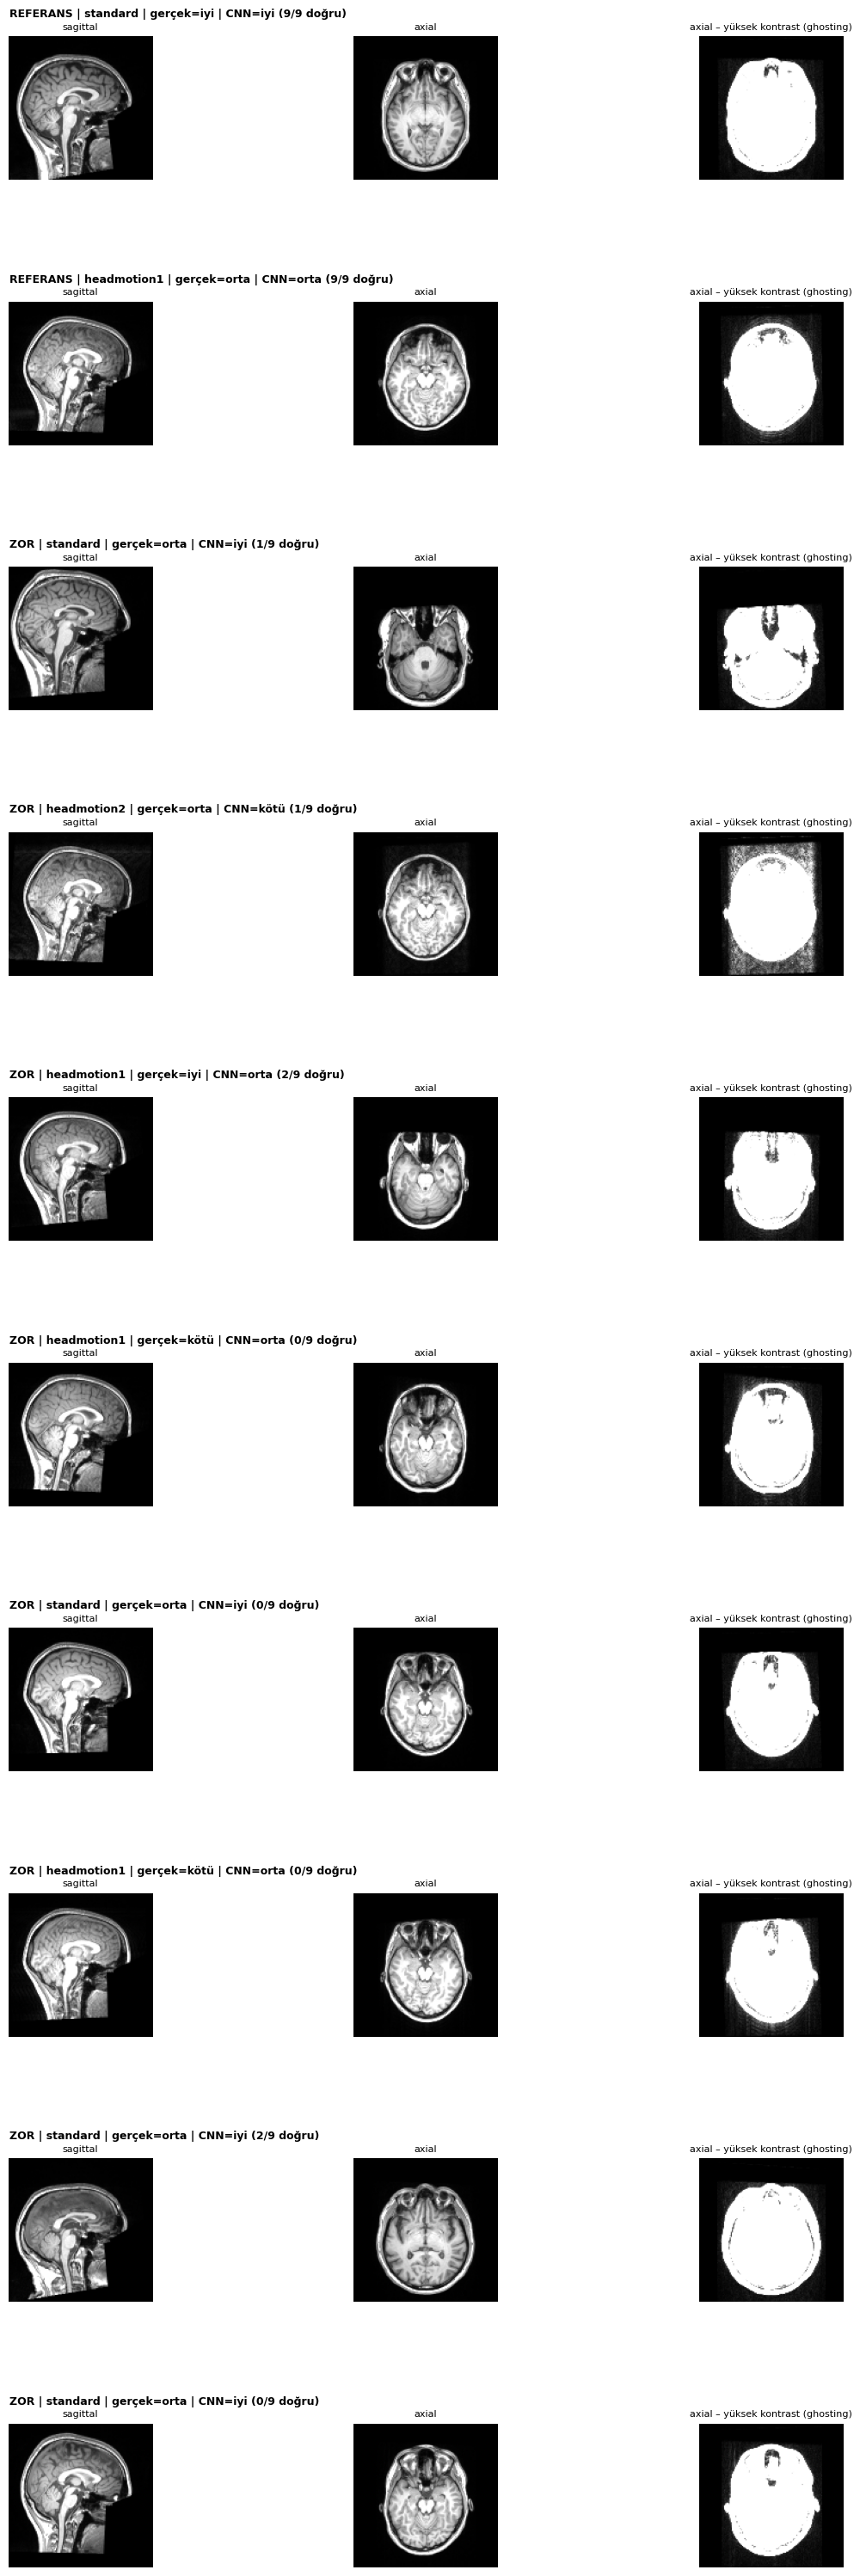

In [14]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, glob, os
ROOT = '/content/drive/MyDrive/PIMI_MRART'; CACHE = f'{ROOT}/cache128'
df = pd.read_csv(f'{ROOT}/master_table.csv')
te = df[df.split == 'test'].reset_index(drop=True)
P = ['p_iyi', 'p_orta', 'p_kotu']; NAMES = ['iyi', 'orta', 'kötü']

# 9 CNN modelinin test tahminleri
files = [f for f in glob.glob(f'{ROOT}/results/r3d18_*_test_preds.csv')]
preds = np.stack([pd.read_csv(f).set_index('bids_name').loc[te.bids_name, 'pred'].values for f in files])
probs = np.mean([pd.read_csv(f).set_index('bids_name').loc[te.bids_name, P].values for f in files], 0)
ens = pd.read_csv(f'{ROOT}/results/ensemble_rf_cnn_test_preds.csv').set_index('bids_name').loc[te.bids_name]
print('Model sayısı:', len(files))

te['n_correct'] = (preds == te.label.values).sum(0)
te['cnn_pred'] = probs.argmax(1); te[P] = probs
te['ens_pred'] = ens.pred.values
te['correct'] = te.ens_pred == te.label

# 1) Hatalar çekim koşuluna göre
print('\n=== RF+CNN hataları: koşul × gerçek skor ===')
print(pd.crosstab([te.acq, te.score], te.correct.map({True: 'doğru', False: 'YANLIŞ'})))

# 2) Zor vakalar (9 modelin en az 7'si yanlış)
hard = te[te.n_correct <= 2].copy()
for f in ['summary_bg_stdv', 'summary_wm_stdv', 'snr_wm', 'cjv']:   # kendi sınıfındaki persentili
    hard[f + '_pct'] = [round((df[df.score == s][f] < v).mean() * 100) for s, v in zip(hard.score, hard[f])]
cols = ['bids_name', 'acq', 'score', 'n_correct', 'cnn_pred', 'p_iyi', 'p_orta', 'p_kotu',
        'summary_bg_stdv_pct', 'summary_wm_stdv_pct', 'snr_wm_pct', 'cjv_pct']
hard['cnn_pred'] = hard.cnn_pred + 1
print(f'\n=== Zor vakalar ({len(hard)} çekim, 9 modelin ≥7\'si yanlış) ===')
print(hard[cols].round(2).to_string(index=False))
print('\nNot: *_pct = o özelliğin, çekimin GERÇEK sınıfı içindeki persentili. '
      'Örn. orta bir çekimde bg_stdv_pct=5 → "orta" sınıfının en temiz %5\'inde, yani iyiye çok benziyor.')
hard[cols].to_csv(f'{ROOT}/results/hard_cases.csv', index=False)

# 3) Görsel: zor vakalar + karşılaştırma için kesin doğru birer iyi/orta
ref = [te[(te.score == s) & (te.n_correct == len(files))].iloc[0] for s in [1, 2] if ((te.score == s) & (te.n_correct == len(files))).any()]
show = pd.concat([pd.DataFrame(ref), hard.head(8)])
fig, ax = plt.subplots(len(show), 3, figsize=(10, 3.1 * len(show)))
for i, (_, r) in enumerate(show.iterrows()):
    v = np.load(f'{CACHE}/{r.bids_name}.npy').astype(np.float32); c = 64
    tag = 'REFERANS' if i < len(ref) else 'ZOR'
    title = f"{tag} | {r.acq} | gerçek={NAMES[r.label]} | CNN={NAMES[int(np.argmax([r.p_iyi, r.p_orta, r.p_kotu]))]} ({r.n_correct}/{len(files)} doğru)"
    ax[i, 0].imshow(np.rot90(v[c]), cmap='gray', vmin=0, vmax=0.7); ax[i, 0].set_title('sagittal', fontsize=8)
    ax[i, 1].imshow(np.rot90(v[:, :, c]), cmap='gray', vmin=0, vmax=0.7); ax[i, 1].set_title('axial', fontsize=8)
    ax[i, 2].imshow(np.rot90(v[:, :, c]), cmap='gray', vmin=0, vmax=0.08); ax[i, 2].set_title('axial – yüksek kontrast (ghosting)', fontsize=8)
    ax[i, 0].text(0, -18, title, fontsize=9, fontweight='bold')
    for a in ax[i]: a.axis('off')
plt.tight_layout(); plt.savefig(f'{ROOT}/figures/hard_cases.png', dpi=130, bbox_inches='tight'); plt.show()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


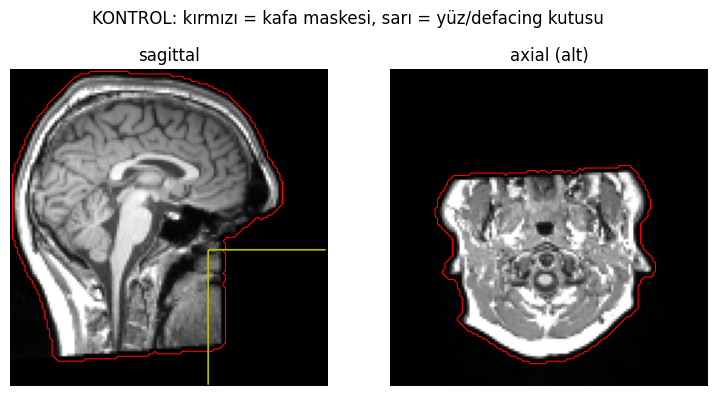

bitti: orijinal
bitti: arka plan silindi (sadece kafa)
bitti: kafa silindi (sadece arka plan)
bitti: yüz bölgesi silindi

                           koşul  bal_acc  macro_f1  auroc  qw_kappa tahmin dağılımı (iyi/orta/kötü)
                       orijinal    0.827     0.818  0.931     0.891                    [32, 18, 37]
arka plan silindi (sadece kafa)    0.509     0.410  0.834     0.414                     [68, 0, 19]
kafa silindi (sadece arka plan)    0.704     0.695  0.831     0.612                    [38, 22, 27]
            yüz bölgesi silindi    0.818     0.808  0.923     0.883                    [32, 19, 36]

=== Grad-CAM enerjisinin dağılımı (ortalama %) ===
             arka_plan_%  yuz_bolgesi_%  kafa_geri_kalan_%
label doğru                                               
iyi   False    59.700001            0.2          40.099998
      True     48.000000            1.8          50.200001
orta  False    53.000000            1.2          45.700001
      True     60.900002      

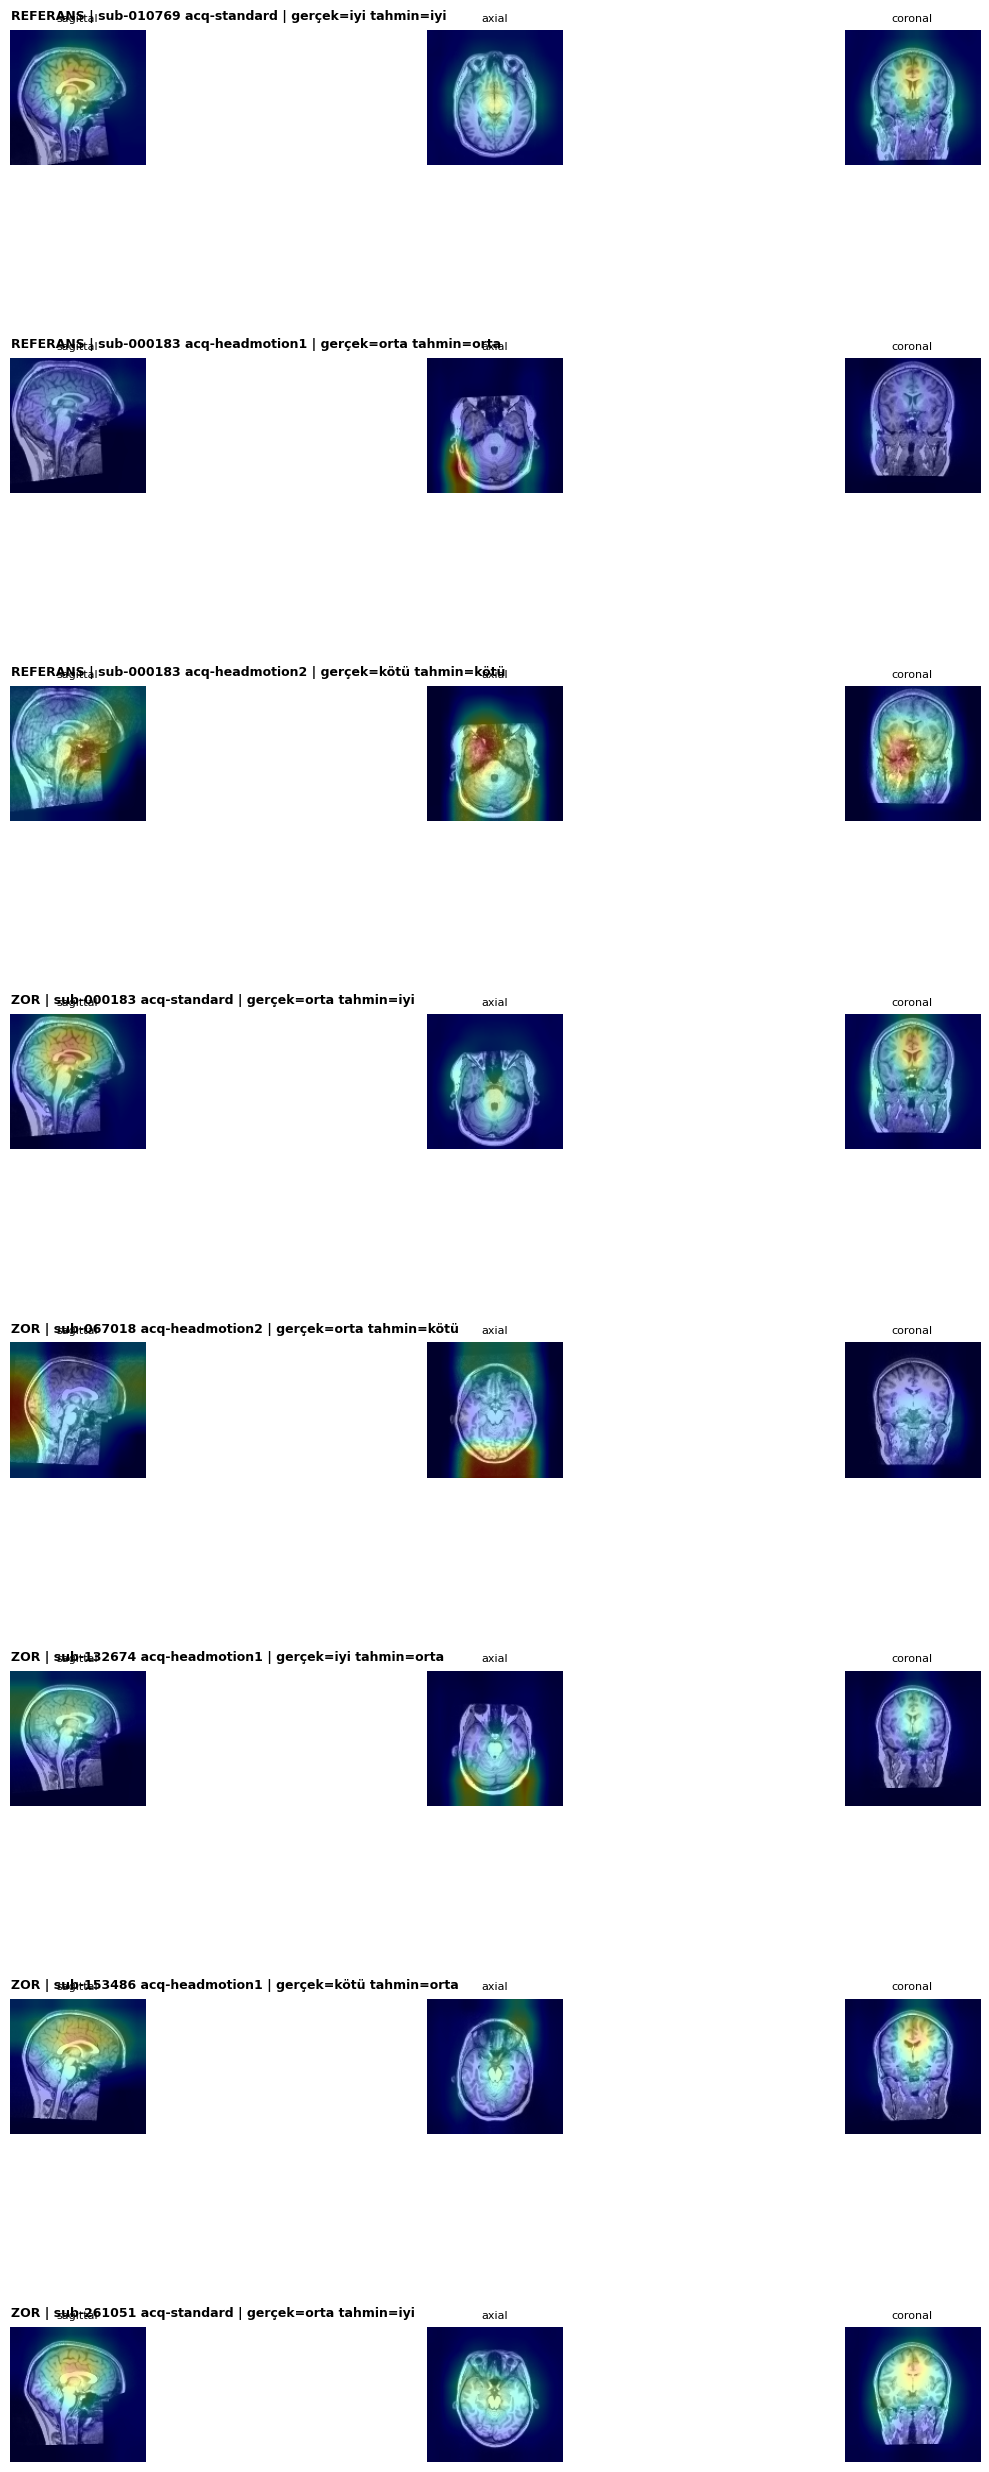

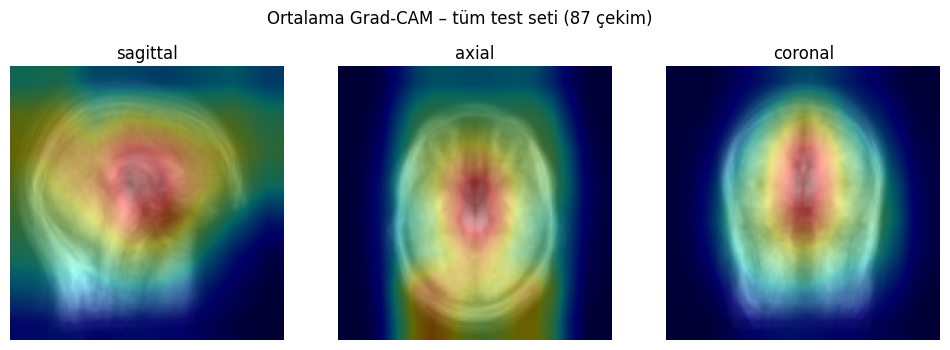

In [15]:
from google.colab import drive; drive.mount('/content/drive')
import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F, matplotlib.pyplot as plt
from scipy import ndimage
from torchvision.models.video import r3d_18
from sklearn.metrics import balanced_accuracy_score, f1_score, roc_auc_score, cohen_kappa_score

ROOT = '/content/drive/MyDrive/PIMI_MRART'; CACHE = f'{ROOT}/cache128'; dev = 'cuda'
df = pd.read_csv(f'{ROOT}/master_table.csv')
te = df[df.split == 'test'].reset_index(drop=True); y = te.label.values
NAMES = ['iyi', 'orta', 'kötü']

class Net(nn.Module):
    def __init__(s):
        super().__init__(); s.m = r3d_18(weights=None)
        s.m.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(512, 3))
    def forward(s, x): return s.m(x.repeat(1, 3, 1, 1, 1))

models = []
for c in ['r3d18_flip_rot90', 'r3d18_flip_rot90_s1', 'r3d18_flip_rot90_s2']:
    m = Net().to(dev); m.load_state_dict(torch.load(f'{ROOT}/models/{c}_best.pt', map_location=dev)); m.eval()
    models.append(m)
vol = lambda b: np.load(f'{CACHE}/{b}.npy').astype(np.float32)

# ---------- Maskeler ----------
def head_mask(v):
    m = ndimage.binary_fill_holes(ndimage.binary_closing(v > 0.06, iterations=3))
    lab, n = ndimage.label(m)
    if n > 1: m = lab == (np.argmax(np.bincount(lab.ravel())[1:]) + 1)
    return ndimage.binary_dilation(m, iterations=2)

FACE = np.zeros((128,) * 3, bool)
FACE[:, 80:, :55] = True   # RAS: eksen1 = anterior (büyük indeks), eksen2 = inferior (küçük indeks)

# Maske kontrolü: kafa maskesi (kırmızı kontur) + yüz kutusu (sarı)
v0 = vol(te.bids_name[0]); hm0 = head_mask(v0)
fig, ax = plt.subplots(1, 2, figsize=(9, 4.5))
for a, (img, msk, t) in zip(ax, [(v0[64], hm0[64], 'sagittal'), (v0[:, :, 40], hm0[:, :, 40], 'axial (alt)')]):
    a.imshow(np.rot90(img), cmap='gray', vmax=0.7); a.contour(np.rot90(msk), colors='r', linewidths=0.8)
    a.set_title(t); a.axis('off')
ax[0].contour(np.rot90(FACE[64]), colors='y', linewidths=1.2)
plt.suptitle('KONTROL: kırmızı = kafa maskesi, sarı = yüz/defacing kutusu'); plt.show()

# ---------- 1) Maskeleme deneyi ----------
@torch.no_grad()
def predict_vol(v):
    x = torch.from_numpy(np.ascontiguousarray(v))[None, None].to(dev)
    with torch.autocast('cuda', dtype=torch.float16):
        return torch.stack([torch.softmax(m(x).float(), 1) for m in models]).mean(0)[0].cpu().numpy()

def apply(v, mode):
    if mode == 'orijinal': return v
    hm = head_mask(v)
    if mode == 'arka plan silindi (sadece kafa)': return v * hm
    if mode == 'kafa silindi (sadece arka plan)': return v * (~hm)
    if mode == 'yüz bölgesi silindi': w = v.copy(); w[FACE] = 0; return w

MODES = ['orijinal', 'arka plan silindi (sadece kafa)', 'kafa silindi (sadece arka plan)', 'yüz bölgesi silindi']
rows = []
for mode in MODES:
    p = np.stack([predict_vol(apply(vol(b), mode)) for b in te.bids_name])
    pr = p.argmax(1)
    rows.append({'koşul': mode, 'bal_acc': balanced_accuracy_score(y, pr), 'macro_f1': f1_score(y, pr, average='macro'),
                 'auroc': roc_auc_score(y, p, multi_class='ovr'), 'qw_kappa': cohen_kappa_score(y, pr, weights='quadratic'),
                 'tahmin dağılımı (iyi/orta/kötü)': np.bincount(pr, minlength=3).tolist()})
    print('bitti:', mode)
occ = pd.DataFrame(rows).round(3); print('\n', occ.to_string(index=False))
occ.to_csv(f'{ROOT}/results/occlusion_test.csv', index=False)

# ---------- 2) Grad-CAM ----------
def gradcam(v):
    cams = []
    x = torch.from_numpy(np.ascontiguousarray(v))[None, None].to(dev)
    for m in models:
        store = {}
        h = m.m.layer4.register_forward_hook(lambda mod, i, o: store.__setitem__('a', o))
        out = m(x); cls = out.argmax(1).item()
        g = torch.autograd.grad(out[0, cls], store['a'])[0]
        cam = F.relu((g.mean(dim=(2, 3, 4), keepdim=True) * store['a']).sum(1, keepdim=True))
        cam = F.interpolate(cam, size=(128,) * 3, mode='trilinear', align_corners=False)[0, 0]
        cams.append((cam / (cam.max() + 1e-8)).detach().cpu().numpy()); h.remove()
    return np.mean(cams, 0)

ens = pd.read_csv(f'{ROOT}/results/r3d18_flip_rot90_test_preds.csv').set_index('bids_name')
stats, cam_store = [], {}
for b, lab in zip(te.bids_name, te.label):
    v = vol(b); cam = gradcam(v); hm = head_mask(v); tot = cam.sum() + 1e-8
    stats.append({'bids_name': b, 'label': lab, 'pred': int(ens.loc[b, 'pred']),
                  'arka_plan_%': 100 * cam[~hm].sum() / tot,
                  'yuz_bolgesi_%': 100 * cam[FACE & hm].sum() / tot,
                  'kafa_geri_kalan_%': 100 * cam[hm & ~FACE].sum() / tot})
    cam_store[b] = cam
st = pd.DataFrame(stats); st['doğru'] = st.label == st.pred
print('\n=== Grad-CAM enerjisinin dağılımı (ortalama %) ===')
print(st.groupby(['label', 'doğru'])[['arka_plan_%', 'yuz_bolgesi_%', 'kafa_geri_kalan_%']].mean().round(1)
      .rename(index=lambda i: NAMES[i] if isinstance(i, (int, np.integer)) else i, level=0))
print(f"\nAlan payları (karşılaştırma için): yüz kutusu hacmin %{100*FACE.mean():.1f}'i")
st.to_csv(f'{ROOT}/results/gradcam_energy.csv', index=False)

# ---------- 3) Görseller: referanslar + zor vakalar ----------
hard = pd.read_csv(f'{ROOT}/results/hard_cases.csv').bids_name.tolist()
refs = [st[(st.label == l) & st.doğru].bids_name.iloc[0] for l in [0, 1, 2]]
show = refs + hard[:5]
fig, ax = plt.subplots(len(show), 3, figsize=(10, 3.3 * len(show)))
for i, b in enumerate(show):
    v, cam = vol(b), cam_store[b]; r = st[st.bids_name == b].iloc[0]
    for j, (img, c, t) in enumerate([(v[64], cam[64], 'sagittal'), (v[:, :, 64], cam[:, :, 64], 'axial'),
                                     (v[:, 64, :], cam[:, 64, :], 'coronal')]):
        ax[i, j].imshow(np.rot90(img), cmap='gray', vmax=0.7)
        ax[i, j].imshow(np.rot90(c), cmap='jet', alpha=0.35, vmin=0, vmax=1); ax[i, j].axis('off')
        ax[i, j].set_title(t, fontsize=8)
    tag = 'REFERANS' if i < 3 else 'ZOR'
    ax[i, 0].text(0, -10, f"{tag} | {b.split('_')[0]} {b.split('_')[1]} | gerçek={NAMES[r.label]} tahmin={NAMES[r.pred]}",
                  fontsize=9, fontweight='bold')
plt.tight_layout(); plt.savefig(f'{ROOT}/figures/gradcam_cases.png', dpi=130, bbox_inches='tight'); plt.show()

# Ortalama Grad-CAM (tüm test seti)
mean_cam = np.mean(list(cam_store.values()), 0); mean_v = np.mean([vol(b) for b in te.bids_name], 0)
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
for a, (img, c, t) in zip(ax, [(mean_v[64], mean_cam[64], 'sagittal'), (mean_v[:, :, 64], mean_cam[:, :, 64], 'axial'),
                               (mean_v[:, 64, :], mean_cam[:, 64, :], 'coronal')]):
    a.imshow(np.rot90(img), cmap='gray'); a.imshow(np.rot90(c), cmap='jet', alpha=0.4); a.set_title(t); a.axis('off')
plt.suptitle('Ortalama Grad-CAM – tüm test seti (87 çekim)')
plt.savefig(f'{ROOT}/figures/gradcam_mean.png', dpi=150, bbox_inches='tight'); plt.show()

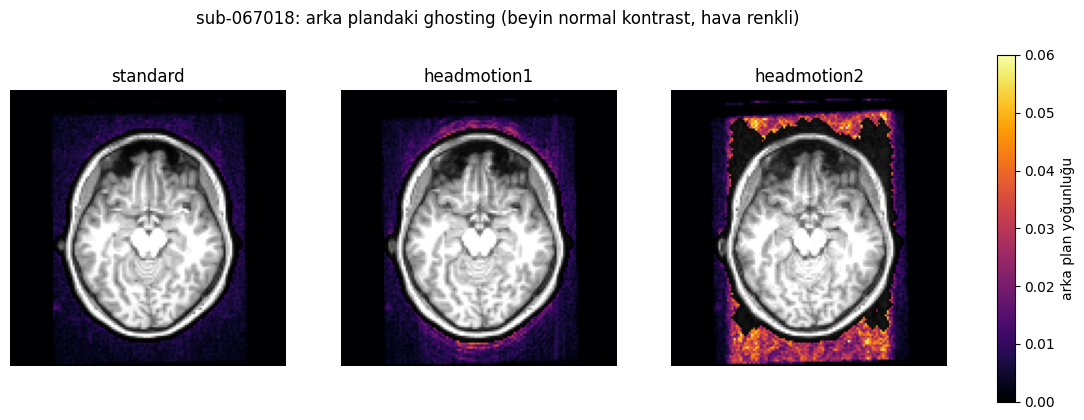

In [16]:
import numpy as np, matplotlib.pyplot as plt
from scipy import ndimage
CACHE = '/content/drive/MyDrive/PIMI_MRART/cache128'
def head_mask(v):
    m = ndimage.binary_fill_holes(ndimage.binary_closing(v > 0.06, iterations=3))
    lab, n = ndimage.label(m)
    if n > 1: m = lab == (np.argmax(np.bincount(lab.ravel())[1:]) + 1)
    return ndimage.binary_dilation(m, iterations=2)

sub = 'sub-067018'   # istediğin katılımcı
fig, ax = plt.subplots(1, 3, figsize=(13, 4.5))
for a, acq in zip(ax, ['standard', 'headmotion1', 'headmotion2']):
    v = np.load(f'{CACHE}/{sub}_acq-{acq}_T1w.npy').astype(np.float32)
    sl, hm = v[:, :, 64], head_mask(v)[:, :, 64]
    a.imshow(np.rot90(sl), cmap='gray', vmax=0.7)                                   # beyin normal
    bg = np.ma.masked_where(np.rot90(hm), np.rot90(sl))                              # sadece arka plan
    im = a.imshow(bg, cmap='inferno', vmin=0, vmax=0.06)                             # ghosting renkli
    a.set_title(acq); a.axis('off')
plt.colorbar(im, ax=ax, fraction=0.02, label='arka plan yoğunluğu')
plt.suptitle(f'{sub}: arka plandaki ghosting (beyin normal kontrast, hava renkli)')
plt.show()

Mounted at /content/drive
Kaynak çekim sayısı: 75 | katılımcılar train dışına çıkmıyor: True
FFT gidiş-dönüş max hata (görece): 4.99e-07  (≈0 olmalı)
1/75 kaynak | 6 sentetik | 3s
11/75 kaynak | 66 sentetik | 41s
21/75 kaynak | 126 sentetik | 81s
31/75 kaynak | 186 sentetik | 126s
41/75 kaynak | 246 sentetik | 168s
51/75 kaynak | 306 sentetik | 209s
61/75 kaynak | 366 sentetik | 248s
71/75 kaynak | 426 sentetik | 290s
Bitti. Sentetik hacim sayısı: 450 
 level
hafif    150
orta     150
agir     150
Name: count, dtype: int64

=== Arka plan istatistikleri (medyan) ===
                 bg_std  bg_p95
grup                          
gerçek-1        0.0038  0.0076
gerçek-2        0.0050  0.0112
gerçek-3        0.0071  0.0182
sentetik-hafif  0.0046  0.0103
sentetik-orta   0.0060  0.0148
sentetik-agir   0.0087  0.0246


/tmp/ipykernel_835/3565590836.py:105: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  a.boxplot([cal[cal.grup == g][col] for g in order], labels=order, showfliers=False)
/tmp/ipykernel_835/3565590836.py:105: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  a.boxplot([cal[cal.grup == g][col] for g in order], labels=order, showfliers=False)


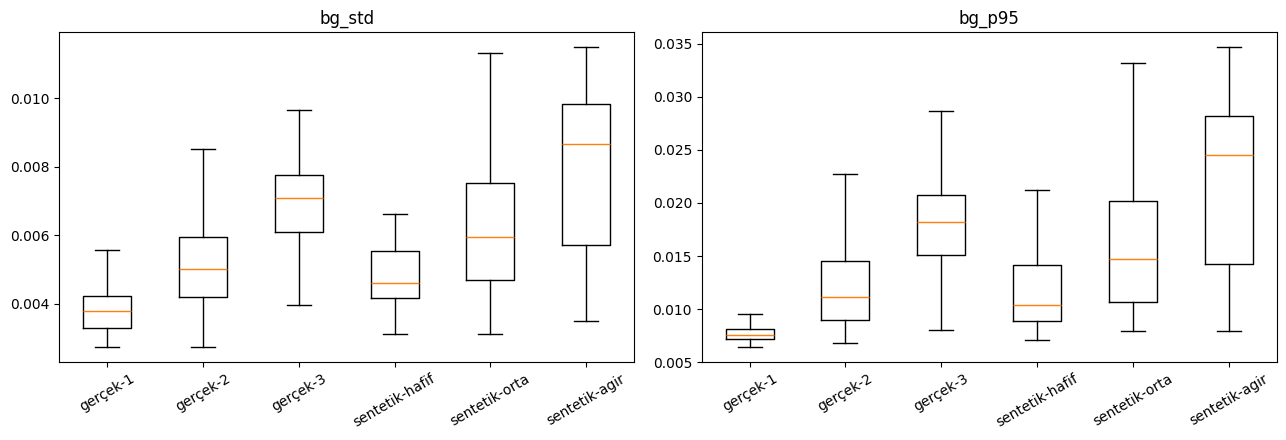

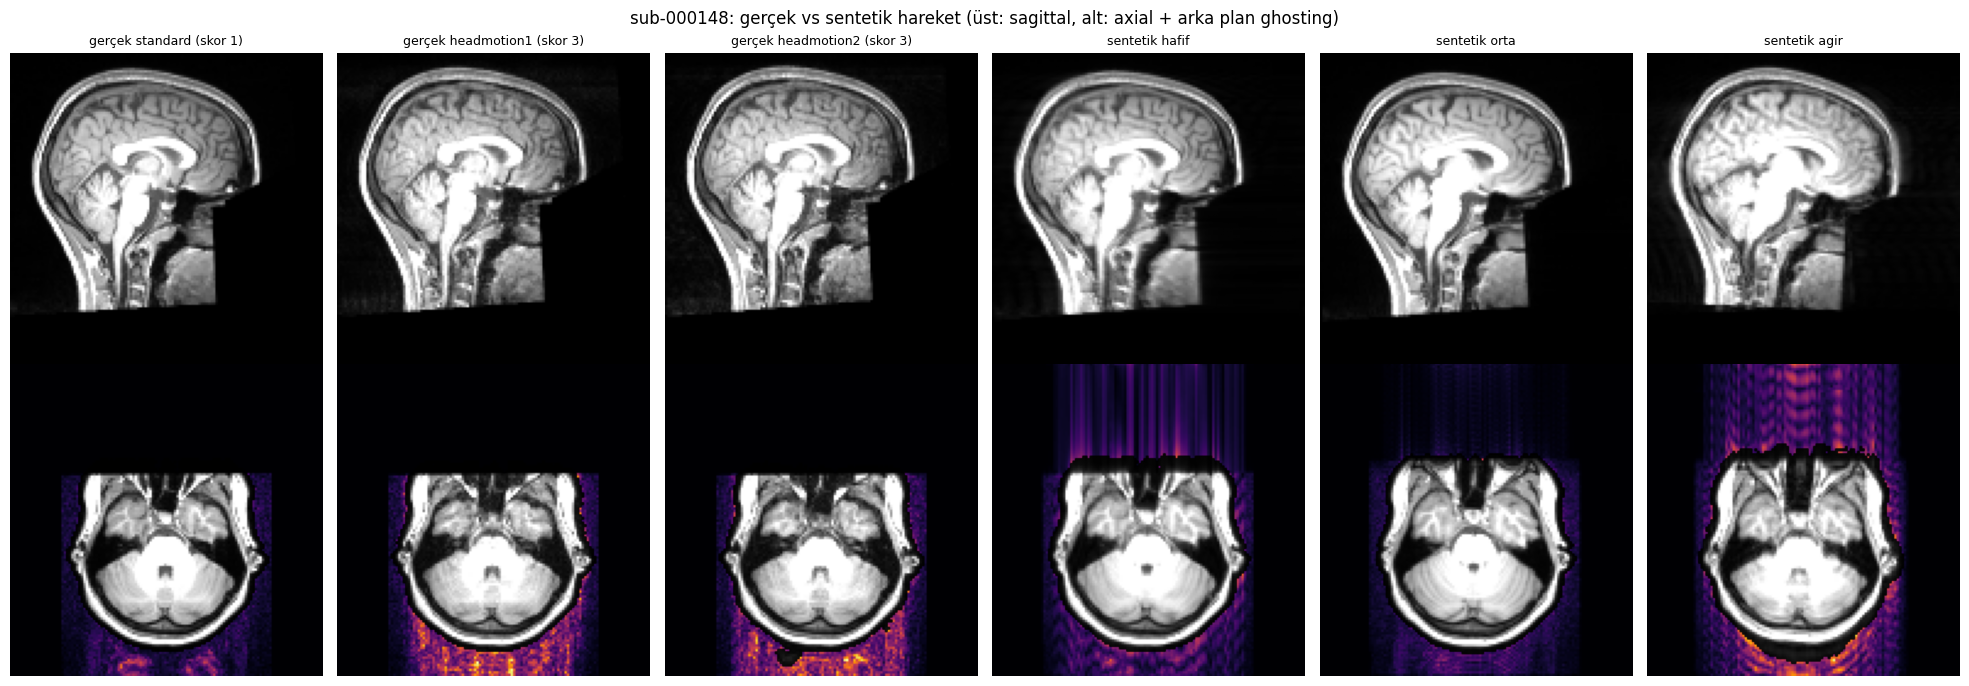

In [1]:
from google.colab import drive; drive.mount('/content/drive')
import os, time, math, json, numpy as np, pandas as pd, nibabel as nib, torch, torch.nn.functional as F
import matplotlib.pyplot as plt
from scipy import ndimage

ROOT = '/content/drive/MyDrive/PIMI_MRART'; CACHE = f'{ROOT}/cache128'
SYN = f'{ROOT}/cache128_synth'; os.makedirs(SYN, exist_ok=True)
dev = 'cuda'; rng = np.random.default_rng(42)
df = pd.read_csv(f'{ROOT}/master_table.csv')

# Kaynak: SADECE train + standard + uzman skoru 1
src = df[(df.split == 'train') & (df.acq == 'standard') & (df.score == 1)].reset_index(drop=True)
print('Kaynak çekim sayısı:', len(src), '| katılımcılar train dışına çıkmıyor:',
      set(src.subject).isdisjoint(set(df[df.split != 'train'].subject)))

LEVELS = {'hafif': dict(ev=(1, 2), rot=1.5, tr=1.5),
          'orta':  dict(ev=(2, 3), rot=3.0, tr=3.0),
          'agir':  dict(ev=(3, 5), rot=6.0, tr=5.0)}
N_VAR = 2   # her kaynak çekimden, her seviye için kaç varyant

def rigid(v, rot_deg, t):
    """v: (1,1,D,H,W). Dönme: D ekseni (sol-sağ) etrafında = baş sallama. t: (tD,tH,tW) voksel (=mm)."""
    a = math.radians(rot_deg); c, s = math.cos(a), math.sin(a)
    D, H, W = v.shape[2:]
    theta = torch.tensor([[c, -s, 0, 2 * t[2] / W],
                          [s,  c, 0, 2 * t[1] / H],
                          [0,  0, 1, 2 * t[0] / D]], dtype=torch.float32, device=dev)[None]
    grid = F.affine_grid(theta, v.shape, align_corners=False)
    return F.grid_sample(v, grid, mode='bilinear', padding_mode='zeros', align_corners=False)

def kspace(x): return torch.fft.fftshift(torch.fft.fftn(x))
def image(K):  return torch.abs(torch.fft.ifftn(torch.fft.ifftshift(K))).float()

def simulate(img, level):
    cfg = LEVELS[level]
    v = torch.from_numpy(img).to(dev)[None, None]
    K = kspace(v[0, 0]); H = img.shape[1]                 # faz kodlama: eksen 1 (ön-arka)
    n = int(rng.integers(cfg['ev'][0], cfg['ev'][1] + 1))
    times = np.sort(rng.uniform(0.05, 0.95, n))           # hareket anları (çekim süresinin oranı)
    bounds = (np.r_[times, 1.0] * H).astype(int)          # k-space lineer sırayla toplanıyor varsayımı
    events = []
    for i in range(n):
        rot = float(rng.uniform(-cfg['rot'], cfg['rot'])); t = rng.uniform(-cfg['tr'], cfg['tr'], 3)
        Km = kspace(rigid(v, rot, t)[0, 0])
        K[:, bounds[i]:bounds[i + 1], :] = Km[:, bounds[i]:bounds[i + 1], :]
        events.append({'t': round(float(times[i]), 2), 'rot': round(rot, 2), 'trans': np.round(t, 2).tolist()})
    return image(K).cpu().numpy(), events

def prep(v, size=128):   # cache ile BİREBİR aynı ön işlem
    v = np.clip(v / (np.percentile(v, 99.5) + 1e-6), 0, 1).astype(np.float32)
    m = max(v.shape); v = np.pad(v, [((m - s) // 2, m - s - (m - s) // 2) for s in v.shape])
    t = F.interpolate(torch.from_numpy(v)[None, None], size=(size,) * 3, mode='trilinear', align_corners=False)
    return t[0, 0].numpy().astype(np.float16)

# --- Kontrol: hareket yoksa FFT gidiş-dönüş orijinali vermeli ---
img0 = nib.as_closest_canonical(nib.load(src.path[0])).get_fdata(dtype=np.float32)
rt = image(kspace(torch.from_numpy(img0).to(dev))).cpu().numpy()
print(f'FFT gidiş-dönüş max hata (görece): {np.abs(rt - img0).max() / img0.max():.2e}  (≈0 olmalı)')

# --- Üretim ---
meta_path = f'{ROOT}/results/synth_index.csv'
meta = pd.read_csv(meta_path).to_dict('records') if os.path.exists(meta_path) else []
done = {m['synth_name'] for m in meta}
t0 = time.time()
for i, r in src.iterrows():
    img = None
    for level in LEVELS:
        for k in range(N_VAR):
            name = f'{r.bids_name}_syn-{level}{k}'
            if name in done: continue
            if img is None: img = nib.as_closest_canonical(nib.load(r.path)).get_fdata(dtype=np.float32)
            out, ev = simulate(img, level)
            np.save(f'{SYN}/{name}.npy', prep(out))
            meta.append({'synth_name': name, 'source': r.bids_name, 'subject': r.subject,
                         'level': level, 'n_events': len(ev), 'events': json.dumps(ev)})
    if i % 10 == 0:
        pd.DataFrame(meta).to_csv(meta_path, index=False)
        print(f'{i + 1}/{len(src)} kaynak | {len(meta)} sentetik | {time.time() - t0:.0f}s')
meta = pd.DataFrame(meta); meta.to_csv(meta_path, index=False)
print('Bitti. Sentetik hacim sayısı:', len(meta), '\n', meta.level.value_counts())

# --- Kalibrasyon: sentetik veriler gerçek sınıflara benziyor mu? ---
def head_mask(v):
    m = ndimage.binary_fill_holes(ndimage.binary_closing(v > 0.06, iterations=3))
    lab, n = ndimage.label(m)
    if n > 1: m = lab == (np.argmax(np.bincount(lab.ravel())[1:]) + 1)
    return ndimage.binary_dilation(m, iterations=2)

def bg_stats(v):
    v = v.astype(np.float32); b = v[~head_mask(v)]
    return b.std(), np.percentile(b, 95)

rows = []
for _, r in df[df.split == 'train'].iterrows():
    s, p = bg_stats(np.load(f'{CACHE}/{r.bids_name}.npy')); rows.append({'grup': f'gerçek-{r.score}', 'bg_std': s, 'bg_p95': p})
for _, r in meta.groupby('level').sample(n=min(60, meta.level.value_counts().min()), random_state=42).iterrows():
    s, p = bg_stats(np.load(f'{SYN}/{r.synth_name}.npy')); rows.append({'grup': f'sentetik-{r.level}', 'bg_std': s, 'bg_p95': p})
cal = pd.DataFrame(rows)
order = ['gerçek-1', 'gerçek-2', 'gerçek-3', 'sentetik-hafif', 'sentetik-orta', 'sentetik-agir']
print('\n=== Arka plan istatistikleri (medyan) ===\n', cal.groupby('grup')[['bg_std', 'bg_p95']].median().loc[order].round(4))
cal.to_csv(f'{ROOT}/results/synth_calibration.csv', index=False)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for a, col in zip(ax, ['bg_std', 'bg_p95']):
    a.boxplot([cal[cal.grup == g][col] for g in order], labels=order, showfliers=False)
    a.set_title(col); a.tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.savefig(f'{ROOT}/figures/synth_calibration.png', dpi=150); plt.show()

# --- Görsel: aynı katılımcı – gerçek hareketli çekimler vs sentetik ---
s0 = src.subject[0]; base = src.bids_name[0]
panels = [(f'{CACHE}/{b}.npy', f'gerçek {b.split("acq-")[1][:-4]} (skor {sc})')
          for b, sc in df[df.subject == s0][['bids_name', 'score']].values]
panels += [(f'{SYN}/{base}_syn-{l}0.npy', f'sentetik {l}') for l in LEVELS]
fig, ax = plt.subplots(2, len(panels), figsize=(3.3 * len(panels), 7))
for j, (p, t) in enumerate(panels):
    v = np.load(p).astype(np.float32); sl = v[:, :, 64]; hm = head_mask(v)[:, :, 64]
    ax[0, j].imshow(np.rot90(v[64]), cmap='gray', vmax=0.7); ax[0, j].set_title(t, fontsize=9)
    ax[1, j].imshow(np.rot90(sl), cmap='gray', vmax=0.7)
    ax[1, j].imshow(np.ma.masked_where(np.rot90(hm), np.rot90(sl)), cmap='inferno', vmin=0, vmax=0.06)
    for a in ax[:, j]: a.axis('off')
plt.suptitle(f'{s0}: gerçek vs sentetik hareket (üst: sagittal, alt: axial + arka plan ghosting)')
plt.tight_layout(); plt.savefig(f'{ROOT}/figures/synth_vs_real.png', dpi=130); plt.show()

In [2]:
from google.colab import drive; drive.mount('/content/drive')
import os, glob
R = '/content/drive/MyDrive/PIMI_MRART'
print('cache128     :', len(os.listdir(f'{R}/cache128')), 'hacim (436 olmalı)')
print('modeller     :', sorted(os.path.basename(f) for f in glob.glob(f'{R}/models/*.pt')))
print('metrics json :', len(glob.glob(f'{R}/results/r3d18_*_metrics.json')), '(9 olmalı)')
print('figürler     :', sorted(os.listdir(f'{R}/figures')))
if os.path.exists(f'{R}/cache128_synth'): print('sentetik     :', len(os.listdir(f'{R}/cache128_synth')), 'hacim')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
cache128     : 436 hacim (436 olmalı)
modeller     : ['r3d18_flip_rot90_best.pt', 'r3d18_flip_rot90_s1_best.pt', 'r3d18_flip_rot90_s2_best.pt', 'r3d18_flip_s1_best.pt', 'r3d18_flip_s2_best.pt', 'r3d18_flip_s42_best.pt', 'r3d18_none_s1_best.pt', 'r3d18_none_s2_best.pt', 'r3d18_none_s42_best.pt']
metrics json : 9 (9 olmalı)
figürler     : ['augmentation_examples.png', 'cache_check_sub-000103.png', 'feature_importance.png', 'gradcam_cases.png', 'gradcam_mean.png', 'hard_cases.png', 'r3d18_flip_rot90_curves.png', 'synth_calibration.png', 'synth_vs_real.png', 'top_features_by_score.png']
sentetik     : 450 hacim


In [3]:
import pandas as pd, numpy as np
from sklearn.metrics import accuracy_score, balanced_accuracy_score, roc_auc_score
ROOT = '/content/drive/MyDrive/PIMI_MRART'
runs = ['r3d18_flip_rot90', 'r3d18_flip_rot90_s1', 'r3d18_flip_rot90_s2']
d = [pd.read_csv(f'{ROOT}/results/{r}_test_preds.csv').set_index('bids_name') for r in runs]
p = np.mean([x[['p_iyi', 'p_orta', 'p_kotu']].values for x in d], 0); y = d[0].label.values
pred = p.argmax(1)

# (a) iyi vs orta+kötü  (b) sadece iyi vs kötü (orta atılır)
yb, pb, sb = (y > 0).astype(int), (pred > 0).astype(int), 1 - p[:, 0]
m = y != 1
print(f"(a) iyi vs orta+kötü | acc {accuracy_score(yb, pb):.3f}  bal_acc {balanced_accuracy_score(yb, pb):.3f}  AUROC {roc_auc_score(yb, sb):.3f}")
print(f"(b) iyi vs kötü      | acc {accuracy_score(yb[m], pb[m]):.3f}  bal_acc {balanced_accuracy_score(yb[m], pb[m]):.3f}  AUROC {roc_auc_score(yb[m], sb[m]):.3f}")

(a) iyi vs orta+kötü | acc 0.897  bal_acc 0.915  AUROC 0.948
(b) iyi vs kötü      | acc 0.984  bal_acc 0.980  AUROC 0.999


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
0/436
100/436
200/436
300/436
400/436
Embedding boyutu: (436, 512)


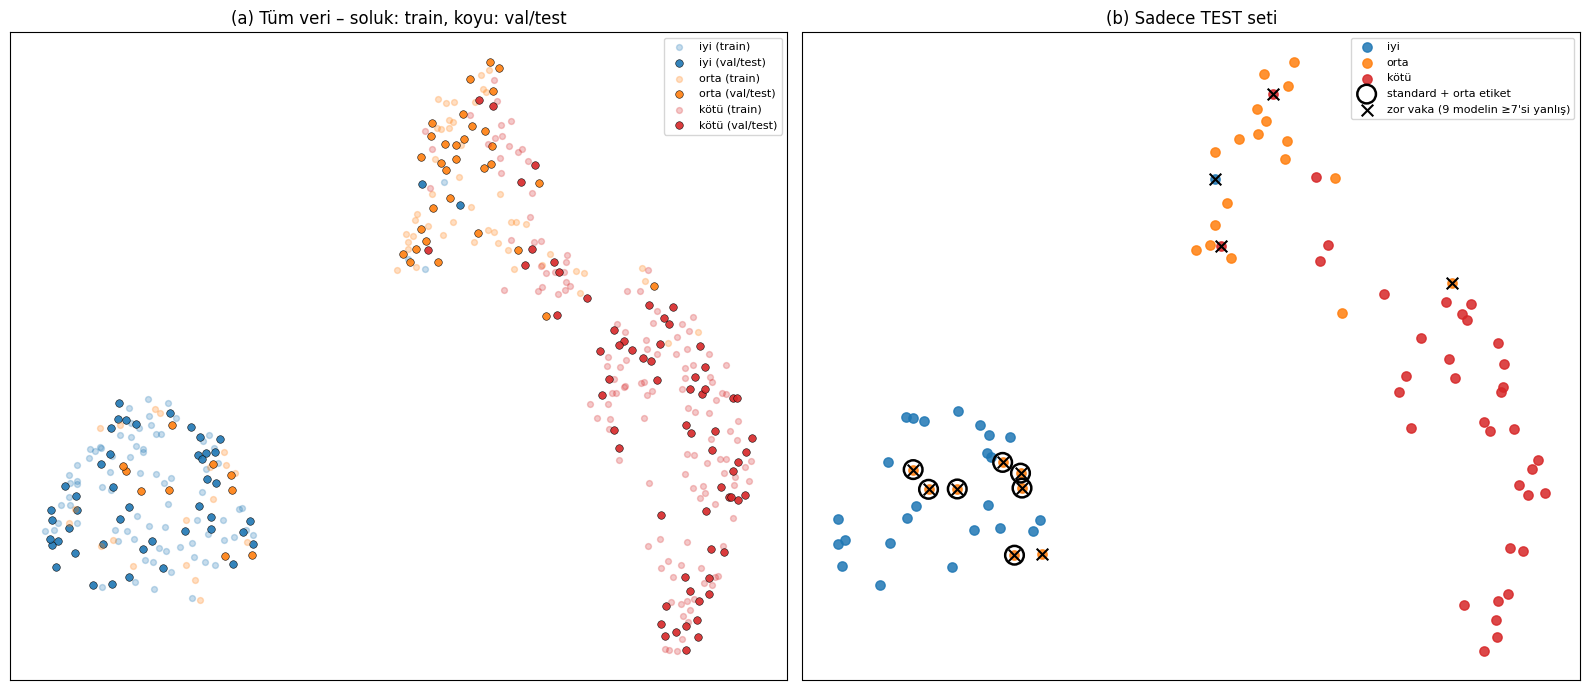

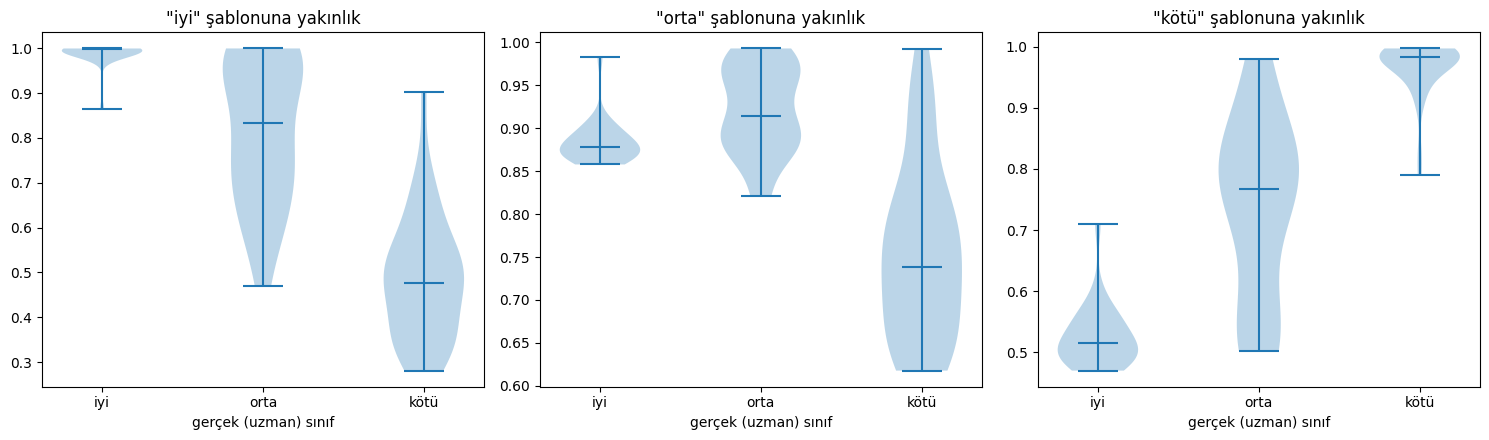

=== En yakın şablon sınıflandırması (TEST) ===
bal_acc 0.818 | qw_kappa 0.883
[[24  1  0]
 [ 8 15  3]
 [ 0  3 33]]

=== "standard + orta" etiketli çekimlerin en yakın şablonu ===
train (n=19): {'iyi': 17, 'orta': 2}
test  (n=7): {'iyi': 7}

                      bids_name split         acq  score  aff_iyi  aff_orta  aff_kötü nearest
   sub-000183_acq-standard_T1w  test    standard      2    0.997     0.882     0.519     iyi
sub-067018_acq-headmotion2_T1w  test headmotion2      2    0.618     0.821     0.979    kötü
sub-132674_acq-headmotion1_T1w  test headmotion1      1    0.865     0.983     0.710    orta
sub-153486_acq-headmotion1_T1w  test headmotion1      3    0.903     0.993     0.790    orta
   sub-261051_acq-standard_T1w  test    standard      2    0.991     0.885     0.540     iyi
sub-261051_acq-headmotion1_T1w  test headmotion1      3    0.665     0.931     0.828    orta
   sub-279373_acq-standard_T1w  test    standard      2    0.990     0.916     0.594     iyi
   sub-292213_

In [5]:
from google.colab import drive; drive.mount('/content/drive')
import numpy as np, pandas as pd, torch, torch.nn as nn, matplotlib.pyplot as plt
from torchvision.models.video import r3d_18
from sklearn.manifold import TSNE
from sklearn.metrics import balanced_accuracy_score, cohen_kappa_score, confusion_matrix

ROOT = '/content/drive/MyDrive/PIMI_MRART'; CACHE = f'{ROOT}/cache128'; dev = 'cuda'
NAMES = ['iyi', 'orta', 'kötü']; COL = ['tab:blue', 'tab:orange', 'tab:red']
df = pd.read_csv(f'{ROOT}/master_table.csv')

class Net(nn.Module):
    def __init__(s):
        super().__init__(); s.m = r3d_18(weights=None)
        s.m.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(512, 3))
    def forward(s, x): return s.m(x.repeat(1, 3, 1, 1, 1))

model = Net().to(dev)
model.load_state_dict(torch.load(f'{ROOT}/models/r3d18_flip_rot90_best.pt', map_location=dev)); model.eval()
model.m.fc = nn.Identity()          # son katmanı çıkar -> 512 boyutlu embedding

# 1) Embedding çıkarımı
E = []
with torch.no_grad():
    for i, b in enumerate(df.bids_name):
        x = torch.from_numpy(np.load(f'{CACHE}/{b}.npy').astype(np.float32))[None, None].to(dev)
        with torch.autocast('cuda', dtype=torch.float16):
            E.append(model(x).float().cpu().numpy()[0])
        if i % 100 == 0: print(f'{i}/{len(df)}')
E = np.stack(E); np.save(f'{ROOT}/results/embeddings_r3d18_s42.npy', E)
print('Embedding boyutu:', E.shape)

hard = set(pd.read_csv(f'{ROOT}/results/hard_cases.csv').bids_name)
df['hard'] = df.bids_name.isin(hard)
df['std_orta'] = (df.acq == 'standard') & (df.score == 2)

# 2) t-SNE
Z = TSNE(n_components=2, perplexity=30, metric='cosine', init='pca', random_state=42).fit_transform(E)
df['tx'], df['ty'] = Z[:, 0], Z[:, 1]

fig, ax = plt.subplots(1, 2, figsize=(16, 7))
for l in range(3):
    d = df[(df.label == l) & (df.split == 'train')]
    ax[0].scatter(d.tx, d.ty, c=COL[l], alpha=0.25, s=18, label=f'{NAMES[l]} (train)')
    d = df[(df.label == l) & (df.split != 'train')]
    ax[0].scatter(d.tx, d.ty, c=COL[l], alpha=0.9, s=30, edgecolor='k', linewidth=0.4, label=f'{NAMES[l]} (val/test)')
ax[0].set_title('(a) Tüm veri – soluk: train, koyu: val/test'); ax[0].legend(fontsize=8)

t = df[df.split == 'test']
for l in range(3):
    d = t[t.label == l]; ax[1].scatter(d.tx, d.ty, c=COL[l], s=45, alpha=0.85, label=NAMES[l])
d = t[t.std_orta]; ax[1].scatter(d.tx, d.ty, facecolors='none', edgecolors='k', s=180, linewidths=1.8, label='standard + orta etiket')
d = t[t.hard]; ax[1].scatter(d.tx, d.ty, marker='x', c='k', s=70, label='zor vaka (9 modelin ≥7\'si yanlış)')
ax[1].set_title('(b) Sadece TEST seti'); ax[1].legend(fontsize=8)
for a in ax: a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.savefig(f'{ROOT}/figures/tsne_embeddings.png', dpi=150); plt.show()

# 3) MoGrAS benzeri şablon skorları (şablon = TRAIN medyanı -> sızıntı yok)
En = E / np.linalg.norm(E, axis=1, keepdims=True)
tr_mask = (df.split == 'train').values
T = np.stack([np.median(E[tr_mask & (df.label == l).values], 0) for l in range(3)])
T = T / np.linalg.norm(T, axis=1, keepdims=True)
A = En @ T.T                                    # cosine yakınlık skorları (N x 3)
for l in range(3): df[f'aff_{NAMES[l]}'] = A[:, l]
df['nearest'] = A.argmax(1)

t = df[df.split == 'test']
fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
for l in range(3):
    data = [t[t.label == g][f'aff_{NAMES[l]}'] for g in range(3)]
    ax[l].violinplot(data, showmedians=True); ax[l].set_xticks([1, 2, 3], NAMES)
    ax[l].set_title(f'"{NAMES[l]}" şablonuna yakınlık'); ax[l].set_xlabel('gerçek (uzman) sınıf')
plt.tight_layout(); plt.savefig(f'{ROOT}/figures/affinity_violins.png', dpi=150); plt.show()

# 4) En yakın şablon sınıflandırması (test)
print('=== En yakın şablon sınıflandırması (TEST) ===')
print(f"bal_acc {balanced_accuracy_score(t.label, t.nearest):.3f} | qw_kappa {cohen_kappa_score(t.label, t.nearest, weights='quadratic'):.3f}")
print(confusion_matrix(t.label, t.nearest))

# 5) Kritik soru: "standard + orta" çekimler hangi şablona yakın?
print('\n=== "standard + orta" etiketli çekimlerin en yakın şablonu ===')
for sp in ['train', 'test']:
    d = df[df.std_orta & (df.split == sp)]
    print(f'{sp:5s} (n={len(d)}):', d.nearest.map(dict(enumerate(NAMES))).value_counts().to_dict())
d = df[df.std_orta | df.hard][['bids_name', 'split', 'acq', 'score', 'aff_iyi', 'aff_orta', 'aff_kötü', 'nearest']]
d['nearest'] = d.nearest.map(dict(enumerate(NAMES)))
print('\n', d[d.split == 'test'].round(3).to_string(index=False))
df.drop(columns=['path']).to_csv(f'{ROOT}/results/embedding_analysis.csv', index=False)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Kaynak çekim sayısı: 75 | train dışına sızıntı yok: True
FFT gidiş-dönüş hatası: 4.99e-07  (≈0 olmalı)
Orijinalde tam sıfır (defacing) voksel oranı: %44.7
1/75 kaynak | 6 sentetik | 4s
11/75 kaynak | 66 sentetik | 44s
21/75 kaynak | 126 sentetik | 84s
31/75 kaynak | 186 sentetik | 125s
41/75 kaynak | 246 sentetik | 165s
51/75 kaynak | 306 sentetik | 206s
61/75 kaynak | 366 sentetik | 246s
71/75 kaynak | 426 sentetik | 286s
Bitti. Sentetik hacim sayısı: 450
level
hafif    150
orta     150
agir     150
Name: count, dtype: int64

=== Arka plan istatistikleri (medyan) ===
          bg_std  bg_p95
grup                    
gerçek-1  0.0038  0.0076
gerçek-2  0.0050  0.0112
gerçek-3  0.0071  0.0182
v2-hafif  0.0042  0.0089
v2-orta   0.0056  0.0140
v2-agir   0.0068  0.0183


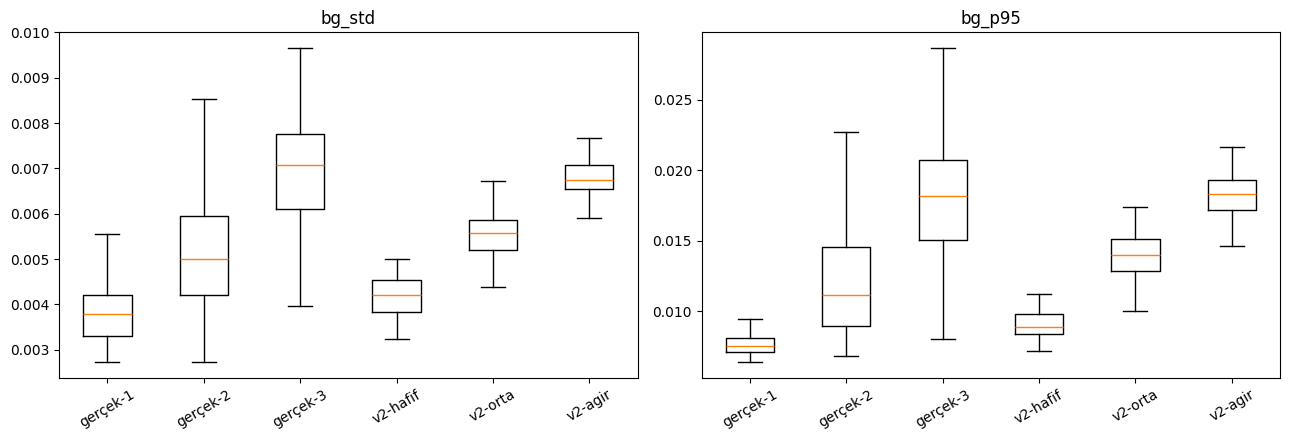

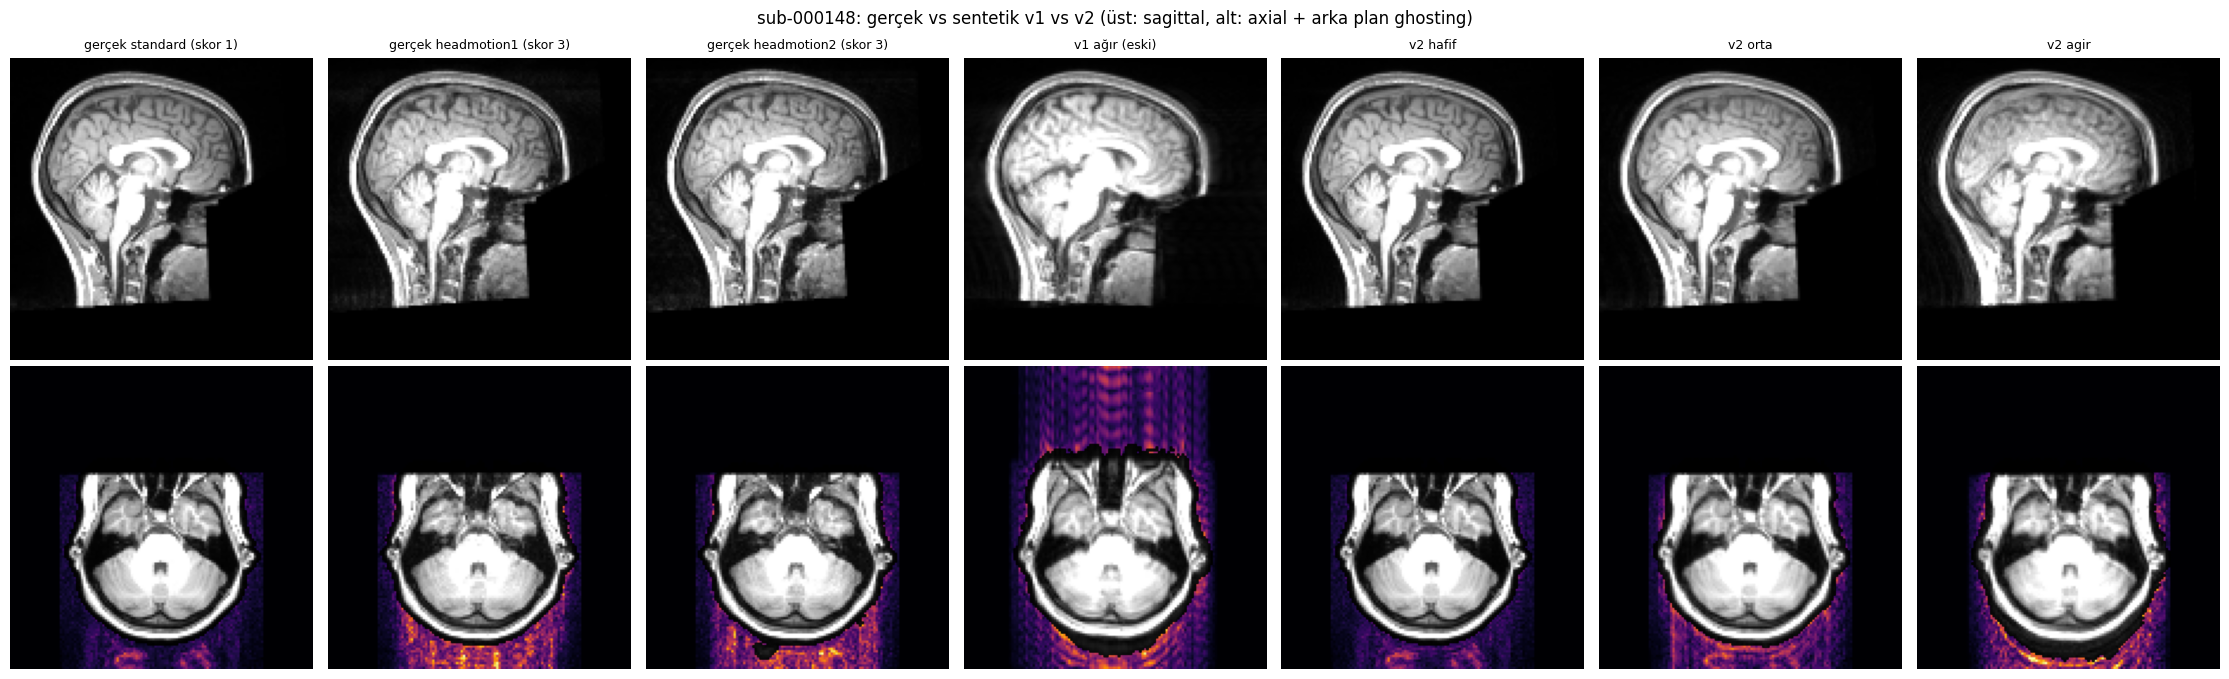

In [6]:
from google.colab import drive; drive.mount('/content/drive')
import os, time, math, json, numpy as np, pandas as pd, nibabel as nib, torch, torch.nn.functional as F
import matplotlib.pyplot as plt
from scipy import ndimage

# ---------------- Ayarlar ----------------
ROOT  = '/content/drive/MyDrive/PIMI_MRART'
CACHE = f'{ROOT}/cache128'
SYN   = f'{ROOT}/cache128_synth_v2'; os.makedirs(SYN, exist_ok=True)
os.makedirs(f'{ROOT}/results', exist_ok=True); os.makedirs(f'{ROOT}/figures', exist_ok=True)
dev = 'cuda'; rng = np.random.default_rng(42)
df = pd.read_csv(f'{ROOT}/master_table.csv')

# Kaynak: SADECE train + standard + uzman skoru 1  (val/test katılımcılarından hiçbir şey üretilmez)
src = df[(df.split == 'train') & (df.acq == 'standard') & (df.score == 1)].reset_index(drop=True)
print('Kaynak çekim sayısı:', len(src), '| train dışına sızıntı yok:',
      set(src.subject).isdisjoint(set(df[df.split != 'train'].subject)))

# v2: ani sıçrama yerine RASTGELE YÜRÜYÜŞ (sürekli kayma). Hareket 'onset' anında başlar.
LEVELS = {'hafif': dict(n_seg=6,  step_rot=0.35, step_tr=0.35, onset=(0.4, 0.8)),
          'orta':  dict(n_seg=10, step_rot=0.6,  step_tr=0.6,  onset=(0.2, 0.6)),
          'agir':  dict(n_seg=16, step_rot=0.9,  step_tr=0.9,  onset=(0.0, 0.4))}
N_VAR = 2   # her kaynak çekim için, her seviyeden kaç varyant

# ---------------- Simülasyon fonksiyonları ----------------
def rigid(v, rot_deg, t):
    """v: (1,1,D,H,W). Dönme: sol-sağ ekseni etrafında (baş sallama). t: (tD,tH,tW) voksel = mm."""
    a = math.radians(rot_deg); c, s = math.cos(a), math.sin(a); D, H, W = v.shape[2:]
    theta = torch.tensor([[c, -s, 0, 2 * t[2] / W],
                          [s,  c, 0, 2 * t[1] / H],
                          [0,  0, 1, 2 * t[0] / D]], dtype=torch.float32, device=dev)[None]
    grid = F.affine_grid(theta, v.shape, align_corners=False)
    return F.grid_sample(v, grid, mode='bilinear', padding_mode='zeros', align_corners=False)

def kspace(x): return torch.fft.fftshift(torch.fft.fftn(x))
def image(K):  return torch.abs(torch.fft.ifftn(torch.fft.ifftshift(K))).float()

def simulate(img, level):
    cfg = LEVELS[level]
    v = torch.from_numpy(img).to(dev)[None, None]
    K = kspace(v[0, 0]); H = img.shape[1]            # faz kodlama yönü: eksen 1 (ön-arka)
    onset = rng.uniform(*cfg['onset'])                # hareketin başladığı an (çekim süresinin oranı)
    edges = (np.linspace(onset, 1.0, cfg['n_seg'] + 1) * H).astype(int)
    rot, tr = 0.0, np.zeros(3); traj = []
    for i in range(cfg['n_seg']):
        rot += rng.normal(0, cfg['step_rot'])         # kümülatif küçük adımlar = sürekli kayma
        tr = tr + rng.normal(0, cfg['step_tr'], 3)
        Km = kspace(rigid(v, rot, tr)[0, 0])
        K[:, edges[i]:edges[i + 1], :] = Km[:, edges[i]:edges[i + 1], :]
        traj.append([round(float(rot), 2), *np.round(tr, 2).tolist()])
    out = image(K).cpu().numpy()
    out[img == 0] = 0      # DÜZELTME: defacing'i hareketten SONRA yeniden uygula (gerçek işlem sırası)
    return out, {'onset': round(float(onset), 2), 'traj': json.dumps(traj)}

def prep(v, size=128):
    """cache128 ile BİREBİR aynı ön işlem."""
    v = np.clip(v / (np.percentile(v, 99.5) + 1e-6), 0, 1).astype(np.float32)
    m = max(v.shape); v = np.pad(v, [((m - s) // 2, m - s - (m - s) // 2) for s in v.shape])
    t = F.interpolate(torch.from_numpy(v)[None, None], size=(size,) * 3, mode='trilinear', align_corners=False)
    return t[0, 0].numpy().astype(np.float16)

# ---------------- Kontroller ----------------
img0 = nib.as_closest_canonical(nib.load(src.path[0])).get_fdata(dtype=np.float32)
rt = image(kspace(torch.from_numpy(img0).to(dev))).cpu().numpy()
print(f'FFT gidiş-dönüş hatası: {np.abs(rt - img0).max() / img0.max():.2e}  (≈0 olmalı)')
print(f'Orijinalde tam sıfır (defacing) voksel oranı: %{100 * (img0 == 0).mean():.1f}')

# ---------------- Üretim ----------------
meta_path = f'{ROOT}/results/synth_index_v2.csv'
meta = pd.read_csv(meta_path).to_dict('records') if os.path.exists(meta_path) else []
done = {m['synth_name'] for m in meta}
t0 = time.time()
for i, r in src.iterrows():
    img = None
    for level in LEVELS:
        for k in range(N_VAR):
            name = f'{r.bids_name}_syn-{level}{k}'
            if name in done and os.path.exists(f'{SYN}/{name}.npy'): continue
            if img is None: img = nib.as_closest_canonical(nib.load(r.path)).get_fdata(dtype=np.float32)
            out, info = simulate(img, level)
            np.save(f'{SYN}/{name}.npy', prep(out))
            meta.append({'synth_name': name, 'source': r.bids_name, 'subject': r.subject, 'level': level, **info})
    if i % 10 == 0:
        pd.DataFrame(meta).drop_duplicates('synth_name', keep='last').to_csv(meta_path, index=False)
        print(f'{i + 1}/{len(src)} kaynak | {len(meta)} sentetik | {time.time() - t0:.0f}s')
meta = pd.DataFrame(meta).drop_duplicates('synth_name', keep='last'); meta.to_csv(meta_path, index=False)
print('Bitti. Sentetik hacim sayısı:', len(meta)); print(meta.level.value_counts())

# ---------------- Kalibrasyon: gerçek sınıflarla karşılaştırma ----------------
def head_mask(v):
    m = ndimage.binary_fill_holes(ndimage.binary_closing(v > 0.06, iterations=3))
    lab, n = ndimage.label(m)
    if n > 1: m = lab == (np.argmax(np.bincount(lab.ravel())[1:]) + 1)
    return ndimage.binary_dilation(m, iterations=2)

def bg_stats(v):
    v = v.astype(np.float32); b = v[~head_mask(v)]
    return b.std(), np.percentile(b, 95)

rows = []
for _, r in df[df.split == 'train'].iterrows():
    s, p = bg_stats(np.load(f'{CACHE}/{r.bids_name}.npy'))
    rows.append({'grup': f'gerçek-{r.score}', 'bg_std': s, 'bg_p95': p})
for _, r in meta.groupby('level').sample(n=60, random_state=42).iterrows():
    s, p = bg_stats(np.load(f'{SYN}/{r.synth_name}.npy'))
    rows.append({'grup': f'v2-{r.level}', 'bg_std': s, 'bg_p95': p})
cal = pd.DataFrame(rows)
order = ['gerçek-1', 'gerçek-2', 'gerçek-3', 'v2-hafif', 'v2-orta', 'v2-agir']
print('\n=== Arka plan istatistikleri (medyan) ===')
print(cal.groupby('grup')[['bg_std', 'bg_p95']].median().loc[order].round(4))
cal.to_csv(f'{ROOT}/results/synth_v2_calibration.csv', index=False)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for a, col in zip(ax, ['bg_std', 'bg_p95']):
    a.boxplot([cal[cal.grup == g][col] for g in order], tick_labels=order, showfliers=False)
    a.set_title(col); a.tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.savefig(f'{ROOT}/figures/synth_v2_calibration.png', dpi=150); plt.show()

# ---------------- Görsel: gerçek vs v1 vs v2 ----------------
s0, base = src.subject[0], src.bids_name[0]
panels = [(f'{CACHE}/{b}.npy', f'gerçek {b.split("acq-")[1][:-4]} (skor {sc})')
          for b, sc in df[df.subject == s0][['bids_name', 'score']].values]
v1 = f'{ROOT}/cache128_synth/{base}_syn-agir0.npy'
if os.path.exists(v1): panels.append((v1, 'v1 ağır (eski)'))
panels += [(f'{SYN}/{base}_syn-{l}0.npy', f'v2 {l}') for l in LEVELS]

fig, ax = plt.subplots(2, len(panels), figsize=(3.2 * len(panels), 7))
for j, (p, t) in enumerate(panels):
    v = np.load(p).astype(np.float32); sl = v[:, :, 64]; hm = head_mask(v)[:, :, 64]
    ax[0, j].imshow(np.rot90(v[64]), cmap='gray', vmax=0.7); ax[0, j].set_title(t, fontsize=9)
    ax[1, j].imshow(np.rot90(sl), cmap='gray', vmax=0.7)
    ax[1, j].imshow(np.ma.masked_where(np.rot90(hm), np.rot90(sl)), cmap='inferno', vmin=0, vmax=0.06)
    for a in ax[:, j]: a.axis('off')
plt.suptitle(f'{s0}: gerçek vs sentetik v1 vs v2 (üst: sagittal, alt: axial + arka plan ghosting)')
plt.tight_layout(); plt.savefig(f'{ROOT}/figures/synth_v1_vs_v2.png', dpi=130); plt.show()

In [1]:
# ===== BİLDİRİM KURULUMU: her oturum başında 1 kez çalıştır =====
import time, requests
from google.colab import output

NTFY_TOPIC = 'YOUR-NTFY-TOPIC'   # <-- telefondaki konu adıyla AYNI olmalı
MIN_SECONDS = 20                   # bundan kısa süren hücreler için bildirim gelmez

def notify(msg, title='Colab', ok=True):
    try:   # telefona bildirim
        requests.post(f'https://ntfy.sh/{NTFY_TOPIC}', data=msg.encode('utf-8'),
                      headers={'Title': title, 'Tags': 'white_check_mark' if ok else 'x',
                               'Priority': 'default' if ok else 'high'}, timeout=10)
    except Exception as e:
        print('ntfy gönderilemedi:', e)
    try:   # tarayıcıda kısa bir bip sesi
        output.eval_js("""(()=>{const c=new AudioContext(),o=c.createOscillator();
            o.frequency.value=880;o.connect(c.destination);o.start();setTimeout(()=>o.stop(),500);})()""")
    except Exception:
        pass

ip = get_ipython()
for cb in list(ip.events.callbacks['pre_run_cell']):  ip.events.unregister('pre_run_cell', cb)  if getattr(cb, '_ntfy', False) else None
for cb in list(ip.events.callbacks['post_run_cell']): ip.events.unregister('post_run_cell', cb) if getattr(cb, '_ntfy', False) else None

_t = {'start': 0}
def _pre(info): _t['start'] = time.time()
def _post(result):
    dur = time.time() - _t['start']
    if dur < MIN_SECONDS: return
    mins = f'{dur/60:.1f} dk'
    if result.error_in_exec is not None:
        notify(f'HATA ({mins}): {type(result.error_in_exec).__name__}: {str(result.error_in_exec)[:150]}',
               title='Colab cell FAILED', ok=False)
    else:
        notify(f'Hucre bitti ({mins}). Ciktiyi kontrol et.', title='Colab cell done')
_pre._ntfy = _post._ntfy = True
ip.events.register('pre_run_cell', _pre); ip.events.register('post_run_cell', _post)

notify('Bildirim kurulumu tamam - test mesaji', title='Colab test')
print('Bildirimler açık ✓  Telefonuna test mesajı geldi mi?')

Bildirimler açık ✓  Telefonuna test mesajı geldi mi?


In [8]:
from google.colab import drive; drive.mount('/content/drive')
import os, re, time, random, json, glob, numpy as np, pandas as pd, torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision.models.video import r3d_18, R3D_18_Weights
from sklearn.metrics import balanced_accuracy_score, f1_score, roc_auc_score, cohen_kappa_score, recall_score

# ---------------- CONFIG ----------------
ROOT  = '/content/drive/MyDrive/PIMI_MRART'
CACHE = f'{ROOT}/cache128'; SYN = f'{ROOT}/cache128_synth_v2'
LR, MAX_EP, PATIENCE, AUG, BS = 1e-4, 40, 8, 'flip_rot90', 4
EP_PER_STAGE = 4
EXPERIMENTS = [('curr', 42), ('rand', 42), ('curr', 1), ('rand', 1), ('curr', 2), ('rand', 2)]
# ----------------------------------------
dev = 'cuda'
df = pd.read_csv(f'{ROOT}/master_table.csv')
tr, va, te = (df[df.split == s] for s in ['train', 'val', 'test'])
meta = pd.read_csv(f'{ROOT}/results/synth_index_v2.csv')
src = df[(df.split == 'train') & (df.acq == 'standard') & (df.score == 1)]
assert set(meta.subject) <= set(tr.subject), 'SIZINTI: sentetik veri train dışı katılımcıdan!'
print('Sızıntı kontrolü ✓ | sentetik:', len(meta), '| temiz kaynak:', len(src))

if 'vols' not in globals():
    print("Gerçek hacimler yükleniyor..."); vols = {b: np.load(f'{CACHE}/{b}.npy') for b in df.bids_name}
if 'svols' not in globals():
    print("Sentetik hacimler yükleniyor (~3 dk)..."); svols = {n: np.load(f'{SYN}/{n}.npy') for n in meta.synth_name}
ALLV = {**vols, **svols}

class MRDataset(Dataset):
    def __init__(s, d, aug='none', repeats=1):
        s.names, s.y, s.aug, s.rep = d.bids_name.tolist(), d.label.tolist(), aug, repeats
    def __len__(s): return len(s.names) * s.rep
    def __getitem__(s, i):
        i %= len(s.names); v = ALLV[s.names[i]]
        if s.aug in ('flip', 'flip_rot90'):
            for ax in range(3):
                if random.random() < 0.5: v = np.flip(v, ax)
        if s.aug == 'flip_rot90':
            v = np.rot90(v, random.randint(0, 3), random.choice([(0, 1), (0, 2), (1, 2)]))
        return torch.from_numpy(np.ascontiguousarray(v, dtype=np.float32))[None], s.y[i]

class Net(nn.Module):
    def __init__(s, n_out):
        super().__init__(); s.m = r3d_18(weights=R3D_18_Weights.KINETICS400_V1)
        s.m.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(512, n_out))
    def forward(s, x): return s.m(x.repeat(1, 3, 1, 1, 1))

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def evaluate(y, proba):
    p = proba.argmax(1)
    return {'bal_acc': float(balanced_accuracy_score(y, p)), 'macro_f1': float(f1_score(y, p, average='macro')),
            'auroc_ovr': float(roc_auc_score(y, proba, multi_class='ovr')),
            'qw_kappa': float(cohen_kappa_score(y, p, weights='quadratic'))}

# ---------------- 1. AŞAMA: Sentetik ön eğitim (4 sınıf: temiz/hafif/orta/ağır) ----------------
pool = pd.concat([pd.DataFrame({'bids_name': src.bids_name.values, 'label': 0}),
                  pd.DataFrame({'bids_name': meta.synth_name.values,
                                'label': meta.level.map({'hafif': 1, 'orta': 2, 'agir': 3}).values})],
                 ignore_index=True)
STAGES = {'curr': [[0, 3], [0, 2, 3], [0, 1, 2, 3]],      # kolaydan zora (Öksüz ve ark. 2019)
          'rand': [[0, 1, 2, 3]] * 3}                     # karşılaştırma: hepsi baştan karışık
SEV = ['temiz', 'hafif', 'orta', 'ağır']

def pretrain(mode, SEED):
    path = f'{ROOT}/models/pretrain_syn{mode}_s{SEED}.pt'
    if os.path.exists(path): print(f'Ön eğitim zaten var: {os.path.basename(path)}'); return path
    seed_all(SEED); model = Net(4).to(dev)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4); scaler = torch.amp.GradScaler('cuda')
    for si, classes in enumerate(STAGES[mode]):
        d = pool[pool.label.isin(classes)]
        cnt = np.bincount(d.label, minlength=4)
        w = np.array([len(d) / (len(classes) * c) if c > 0 else 0.0 for c in cnt], dtype=np.float32)
        crit = nn.CrossEntropyLoss(weight=torch.tensor(w, device=dev))
        dl = DataLoader(MRDataset(d, AUG, 1), batch_size=BS, shuffle=True, num_workers=2,
                        generator=torch.Generator().manual_seed(SEED + si), drop_last=True)
        for ep in range(EP_PER_STAGE):
            model.train(); t0 = time.time(); tl = tc = tn = 0
            for x, y in dl:
                x, y = x.to(dev), y.to(dev); opt.zero_grad()
                with torch.autocast('cuda', dtype=torch.float16):
                    out = model(x); loss = crit(out, y)
                scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
                tl += loss.item() * len(y); tc += (out.argmax(1) == y).sum().item(); tn += len(y)
            print(f'[ön eğitim {mode} s{SEED}] aşama {si+1} {[SEV[c] for c in classes]} | ep {ep+1} | '
                  f'loss {tl/tn:.3f} acc {tc/tn:.3f} | n={len(d)} | {time.time()-t0:.0f}s')
    torch.save(model.state_dict(), path); del model; torch.cuda.empty_cache()
    return path

# ---------------- 2. AŞAMA: Gerçek veride ince ayar (baseline ile BİREBİR aynı ayarlar) ----------------
def finetune(mode, SEED):
    RUN = f'r3d18syn{mode}_{AUG}_s{SEED}'
    if os.path.exists(f'{ROOT}/results/{RUN}_metrics.json'): print(f'{RUN} zaten var, atlanıyor.'); return
    pre = pretrain(mode, SEED)
    seed_all(SEED)
    model = Net(4); model.load_state_dict(torch.load(pre, map_location='cpu'))
    model.m.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(512, 3))      # yeni 3 sınıflı baş
    model = model.to(dev)
    dl_tr = DataLoader(MRDataset(tr, AUG, 4), batch_size=BS, shuffle=True, num_workers=2,
                       generator=torch.Generator().manual_seed(SEED), drop_last=True)
    dl_va = DataLoader(MRDataset(va), batch_size=BS, num_workers=2)
    dl_te = DataLoader(MRDataset(te), batch_size=BS, num_workers=2)
    cnt = np.bincount(tr.label, minlength=3)
    crit = nn.CrossEntropyLoss(weight=torch.tensor(len(tr) / (3 * cnt), dtype=torch.float32, device=dev))
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode='max', factor=0.5, patience=3)
    scaler = torch.amp.GradScaler('cuda')

    @torch.no_grad()
    def predict(dl, tta=False):
        model.eval(); P, Y, L = [], [], 0.0
        for x, y in dl:
            x, y = x.to(dev), y.to(dev)
            with torch.autocast('cuda', dtype=torch.float16):
                lo = model(x)
                if tta: lo = (lo + model(torch.flip(x, dims=[2]))) / 2
            L += crit(lo.float(), y).item() * len(y)
            P.append(torch.softmax(lo.float(), 1).cpu()); Y.append(y.cpu())
        return torch.cat(P).numpy(), torch.cat(Y).numpy(), L / len(dl.dataset)

    hist, best, wait, best_ep = [], -1, 0, 0
    for ep in range(1, MAX_EP + 1):
        model.train(); t0 = time.time(); tl = tc = tn = 0
        for x, y in dl_tr:
            x, y = x.to(dev), y.to(dev); opt.zero_grad()
            with torch.autocast('cuda', dtype=torch.float16):
                out = model(x); loss = crit(out, y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tl += loss.item() * len(y); tc += (out.argmax(1) == y).sum().item(); tn += len(y)
        pv, yv, vl = predict(dl_va); m = evaluate(yv, pv); sched.step(m['bal_acc'])
        hist.append({'epoch': ep, 'train_loss': tl / tn, 'train_acc': tc / tn, 'val_loss': vl,
                     **{f'val_{k}': v for k, v in m.items()}})
        flag = ''
        if m['bal_acc'] > best:
            best, wait, best_ep, flag = m['bal_acc'], 0, ep, '  ★'
            torch.save(model.state_dict(), f'{ROOT}/models/{RUN}_best.pt')
        else:
            wait += 1
        print(f"[{RUN}] ep {ep:2d} | tr_acc {tc/tn:.3f} | val_loss {vl:.3f} val_bacc {m['bal_acc']:.3f} | {time.time()-t0:.0f}s{flag}")
        pd.DataFrame(hist).to_csv(f'{ROOT}/results/{RUN}_history.csv', index=False)
        if wait >= PATIENCE: break

    model.load_state_dict(torch.load(f'{ROOT}/models/{RUN}_best.pt'))
    res = {}
    for name, dl, d in [('val', dl_va, va), ('test', dl_te, te)]:
        p, y, _ = predict(dl, tta=True)
        res[name] = {k: round(v, 3) for k, v in evaluate(y, p).items()}
        pd.DataFrame({'bids_name': d.bids_name.values, 'label': y, 'pred': p.argmax(1),
                      'p_iyi': p[:, 0], 'p_orta': p[:, 1], 'p_kotu': p[:, 2]}
                     ).to_csv(f'{ROOT}/results/{RUN}_{name}_preds.csv', index=False)
    json.dump({'run': RUN, 'best_epoch': best_ep, **res}, open(f'{ROOT}/results/{RUN}_metrics.json', 'w'), indent=1)
    print(f'>>> {RUN} bitti | best epoch {best_ep} | TEST {res["test"]}\n')
    del model; torch.cuda.empty_cache()

for mode, seed in EXPERIMENTS:
    finetune(mode, seed)

# ---------------- Karşılaştırma tablosu ----------------
groups = {'baseline (r3d18)': ['r3d18_flip_rot90', 'r3d18_flip_rot90_s1', 'r3d18_flip_rot90_s2'],
          'sentetik + curriculum': [f'r3d18syncurr_{AUG}_s{s}' for s in [42, 1, 2]],
          'sentetik + rastgele': [f'r3d18synrand_{AUG}_s{s}' for s in [42, 1, 2]]}
rows = []
for g, runs in groups.items():
    for r in runs:
        f = f'{ROOT}/results/{r}_metrics.json'
        if not os.path.exists(f): continue
        m = json.load(open(f))['test']
        pr = pd.read_csv(f'{ROOT}/results/{r}_test_preds.csv')
        rec = recall_score(pr.label, pr.pred, average=None, labels=[0, 1, 2])
        rows.append({'grup': g, 'run': r, **m, 'recall_iyi': rec[0], 'recall_orta': rec[1], 'recall_kotu': rec[2]})
res = pd.DataFrame(rows)
print(res.round(3).to_string(index=False))
summ = res.groupby('grup')[['bal_acc', 'qw_kappa', 'auroc_ovr', 'recall_orta']].agg(['mean', 'std']).round(3)
print('\n=== Sentetik ön eğitimin etkisi (test, seed ortalaması) ===\n', summ)
summ.to_csv(f'{ROOT}/results/synthetic_pretraining_comparison.csv')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Sızıntı kontrolü ✓ | sentetik: 450 | temiz kaynak: 75
Sentetik hacimler yükleniyor (~3 dk)...
Downloading: "https://download.pytorch.org/models/r3d_18-b3b3357e.pth" to /root/.cache/torch/hub/checkpoints/r3d_18-b3b3357e.pth


100%|██████████| 127M/127M [00:00<00:00, 205MB/s]


[ön eğitim curr s42] aşama 1 ['temiz', 'ağır'] | ep 1 | loss 0.420 acc 0.857 | n=225 | 44s
[ön eğitim curr s42] aşama 1 ['temiz', 'ağır'] | ep 2 | loss 0.219 acc 0.920 | n=225 | 47s
[ön eğitim curr s42] aşama 1 ['temiz', 'ağır'] | ep 3 | loss 0.145 acc 0.955 | n=225 | 49s
[ön eğitim curr s42] aşama 1 ['temiz', 'ağır'] | ep 4 | loss 0.094 acc 0.982 | n=225 | 49s
[ön eğitim curr s42] aşama 2 ['temiz', 'orta', 'ağır'] | ep 1 | loss 0.650 acc 0.758 | n=375 | 81s
[ön eğitim curr s42] aşama 2 ['temiz', 'orta', 'ağır'] | ep 2 | loss 0.344 acc 0.847 | n=375 | 81s
[ön eğitim curr s42] aşama 2 ['temiz', 'orta', 'ağır'] | ep 3 | loss 0.312 acc 0.860 | n=375 | 81s
[ön eğitim curr s42] aşama 2 ['temiz', 'orta', 'ağır'] | ep 4 | loss 0.300 acc 0.863 | n=375 | 81s
[ön eğitim curr s42] aşama 3 ['temiz', 'hafif', 'orta', 'ağır'] | ep 1 | loss 0.891 acc 0.651 | n=525 | 114s
[ön eğitim curr s42] aşama 3 ['temiz', 'hafif', 'orta', 'ağır'] | ep 2 | loss 0.592 acc 0.733 | n=525 | 114s
[ön eğitim curr s42] a

KeyboardInterrupt: 

In [9]:
import os, json, pandas as pd
from sklearn.metrics import recall_score
ROOT, AUG = '/content/drive/MyDrive/PIMI_MRART', 'flip_rot90'
groups = {'baseline (r3d18)': ['r3d18_flip_rot90', 'r3d18_flip_rot90_s1', 'r3d18_flip_rot90_s2'],
          'sentetik + curriculum': [f'r3d18syncurr_{AUG}_s{s}' for s in [42, 1, 2]],
          'sentetik + rastgele': [f'r3d18synrand_{AUG}_s{s}' for s in [42, 1, 2]]}
rows = []
for g, runs in groups.items():
    for r in runs:
        f = f'{ROOT}/results/{r}_metrics.json'
        if not os.path.exists(f): continue
        m = json.load(open(f))['test']; pr = pd.read_csv(f'{ROOT}/results/{r}_test_preds.csv')
        rec = recall_score(pr.label, pr.pred, average=None, labels=[0, 1, 2])
        rows.append({'grup': g, 'run': r, **m, 'recall_iyi': rec[0], 'recall_orta': rec[1], 'recall_kotu': rec[2]})
res = pd.DataFrame(rows); print(res.round(3).to_string(index=False))
summ = res.groupby('grup')[['bal_acc', 'qw_kappa', 'auroc_ovr', 'recall_orta']].agg(['mean', 'std', 'count']).round(3)
print('\n', summ); summ.to_csv(f'{ROOT}/results/synthetic_pretraining_comparison.csv')


                 grup                         run  bal_acc  macro_f1  auroc_ovr  qw_kappa  recall_iyi  recall_orta  recall_kotu
     baseline (r3d18)            r3d18_flip_rot90    0.812     0.802      0.931     0.873        0.96        0.615        0.861
     baseline (r3d18)         r3d18_flip_rot90_s1    0.801     0.788      0.929     0.878        0.96        0.500        0.944
     baseline (r3d18)         r3d18_flip_rot90_s2    0.827     0.818      0.926     0.891        0.96        0.577        0.944
sentetik + curriculum r3d18syncurr_flip_rot90_s42    0.816     0.806      0.916     0.871        0.96        0.654        0.833
sentetik + curriculum  r3d18syncurr_flip_rot90_s1    0.770     0.759      0.936     0.851        0.92        0.500        0.889
  sentetik + rastgele r3d18synrand_flip_rot90_s42    0.827     0.818      0.915     0.891        0.96        0.577        0.944

                       bal_acc              qw_kappa              auroc_ovr  \
                        

In [10]:
import os, torch, subprocess
print('CPU sayısı:', os.cpu_count())
print('GPU:', torch.cuda.get_device_name(0))
print(subprocess.run(['nvidia-smi', '--query-gpu=utilization.gpu,memory.used,memory.total', '--format=csv'],
                     capture_output=True, text=True).stdout)
!free -h

CPU sayısı: 8
GPU: Tesla T4
utilization.gpu [%], memory.used [MiB], memory.total [MiB]
0 %, 6245 MiB, 15360 MiB

               total        used        free      shared  buff/cache   available
Mem:            50Gi       7.1Gi        16Gi        24Mi        28Gi        43Gi
Swap:             0B          0B          0B


In [11]:
import time, torch, torch.nn as nn
from torch.utils.data import DataLoader
from torchvision.models.video import r3d_18
torch.cuda.empty_cache()

# 1) Sadece GPU hızı (rastgele veriyle)
m = r3d_18().cuda(); opt = torch.optim.AdamW(m.parameters()); scaler = torch.amp.GradScaler('cuda')
x = torch.randn(4, 3, 128, 128, 128, device='cuda')
def step():
    with torch.autocast('cuda', dtype=torch.float16): loss = m(x).float().mean()
    scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); opt.zero_grad()
for _ in range(3): step()
torch.cuda.synchronize(); t = time.time()
for _ in range(10): step()
torch.cuda.synchronize(); print(f'GPU: {(time.time()-t)/10:.3f} s/batch')
del m, x, opt; torch.cuda.empty_cache()

# 2) Sadece veri yükleme hızı
for nw in [2, 8]:
    dl = DataLoader(MRDataset(tr, 'flip_rot90', 4), batch_size=4, shuffle=True, num_workers=nw, drop_last=True)
    t = time.time()
    for i, (xb, yb) in enumerate(dl):
        if i == 50: break
    print(f'Veri (num_workers={nw}): {(time.time()-t)/50:.3f} s/batch')

GPU: 0.763 s/batch
Veri (num_workers=2): 0.033 s/batch
Veri (num_workers=8): 0.025 s/batch


In [2]:
import time, torch
from torchvision.models.video import r3d_18
print(torch.cuda.get_device_name(0))
m = r3d_18().cuda(); opt = torch.optim.AdamW(m.parameters()); scaler = torch.amp.GradScaler('cuda')
x = torch.randn(4, 3, 128, 128, 128, device='cuda')
def step():
    with torch.autocast('cuda', dtype=torch.float16): loss = m(x).float().mean()
    scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); opt.zero_grad()
for _ in range(3): step()
torch.cuda.synchronize(); t = time.time()
for _ in range(10): step()
torch.cuda.synchronize(); print(f'GPU: {(time.time()-t)/10:.3f} s/batch  (≈0.15 veya altı olmalı)')
!nvidia-smi --query-gpu=clocks.sm,clocks.max.sm,temperature.gpu,power.draw,clocks_throttle_reasons.active --format=csv

NVIDIA A100-SXM4-40GB
GPU: 0.120 s/batch  (≈0.15 veya altı olmalı)
clocks.current.sm [MHz], clocks.max.sm [MHz], temperature.gpu, power.draw [W], clocks_event_reasons.active
1410 MHz, 1410 MHz, 50, 339.84 W, 0x0000000000000000


In [3]:
from google.colab import drive; drive.mount('/content/drive')
import os, re, time, random, json, glob, numpy as np, pandas as pd, torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision.models.video import r3d_18, R3D_18_Weights
from sklearn.metrics import balanced_accuracy_score, f1_score, roc_auc_score, cohen_kappa_score, recall_score

# ---------------- CONFIG ----------------
ROOT  = '/content/drive/MyDrive/PIMI_MRART'
CACHE = f'{ROOT}/cache128'; SYN = f'{ROOT}/cache128_synth_v2'
LR, MAX_EP, PATIENCE, AUG, BS = 1e-4, 40, 8, 'flip_rot90', 4
EP_PER_STAGE = 4
EXPERIMENTS = [('rand', 1)]
NW = 4   # DataLoader işçi sayısı
# ----------------------------------------
dev = 'cuda'
df = pd.read_csv(f'{ROOT}/master_table.csv')
tr, va, te = (df[df.split == s] for s in ['train', 'val', 'test'])
meta = pd.read_csv(f'{ROOT}/results/synth_index_v2.csv')
src = df[(df.split == 'train') & (df.acq == 'standard') & (df.score == 1)]
assert set(meta.subject) <= set(tr.subject), 'SIZINTI: sentetik veri train dışı katılımcıdan!'
print('Sızıntı kontrolü ✓ | sentetik:', len(meta), '| temiz kaynak:', len(src))

if 'vols' not in globals():
    print("Gerçek hacimler yükleniyor..."); vols = {b: np.load(f'{CACHE}/{b}.npy') for b in df.bids_name}
if 'svols' not in globals():
    print("Sentetik hacimler yükleniyor (~3 dk)..."); svols = {n: np.load(f'{SYN}/{n}.npy') for n in meta.synth_name}
ALLV = {**vols, **svols}

class MRDataset(Dataset):
    def __init__(s, d, aug='none', repeats=1):
        s.names, s.y, s.aug, s.rep = d.bids_name.tolist(), d.label.tolist(), aug, repeats
    def __len__(s): return len(s.names) * s.rep
    def __getitem__(s, i):
        i %= len(s.names); v = ALLV[s.names[i]]
        if s.aug in ('flip', 'flip_rot90'):
            for ax in range(3):
                if random.random() < 0.5: v = np.flip(v, ax)
        if s.aug == 'flip_rot90':
            v = np.rot90(v, random.randint(0, 3), random.choice([(0, 1), (0, 2), (1, 2)]))
        return torch.from_numpy(np.ascontiguousarray(v, dtype=np.float32))[None], s.y[i]

class Net(nn.Module):
    def __init__(s, n_out):
        super().__init__(); s.m = r3d_18(weights=R3D_18_Weights.KINETICS400_V1)
        s.m.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(512, n_out))
    def forward(s, x): return s.m(x.repeat(1, 3, 1, 1, 1))

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def evaluate(y, proba):
    p = proba.argmax(1)
    return {'bal_acc': float(balanced_accuracy_score(y, p)), 'macro_f1': float(f1_score(y, p, average='macro')),
            'auroc_ovr': float(roc_auc_score(y, proba, multi_class='ovr')),
            'qw_kappa': float(cohen_kappa_score(y, p, weights='quadratic'))}

# ---------------- 1. AŞAMA: Sentetik ön eğitim (4 sınıf) ----------------
pool = pd.concat([pd.DataFrame({'bids_name': src.bids_name.values, 'label': 0}),
                  pd.DataFrame({'bids_name': meta.synth_name.values,
                                'label': meta.level.map({'hafif': 1, 'orta': 2, 'agir': 3}).values})],
                 ignore_index=True)
STAGES = {'curr': [[0, 3], [0, 2, 3], [0, 1, 2, 3]],
          'rand': [[0, 1, 2, 3]] * 3}
SEV = ['temiz', 'hafif', 'orta', 'ağır']

def pretrain(mode, SEED):
    path = f'{ROOT}/models/pretrain_syn{mode}_s{SEED}.pt'
    if os.path.exists(path): print(f'Ön eğitim zaten var: {os.path.basename(path)}'); return path
    seed_all(SEED); model = Net(4).to(dev)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4); scaler = torch.amp.GradScaler('cuda')
    for si, classes in enumerate(STAGES[mode]):
        d = pool[pool.label.isin(classes)]
        cnt = np.bincount(d.label, minlength=4)
        w = np.array([len(d) / (len(classes) * c) if c > 0 else 0.0 for c in cnt], dtype=np.float32)
        crit = nn.CrossEntropyLoss(weight=torch.tensor(w, device=dev))
        dl = DataLoader(MRDataset(d, AUG, 1), batch_size=BS, shuffle=True, num_workers=NW,
                        generator=torch.Generator().manual_seed(SEED + si), drop_last=True)
        for ep in range(EP_PER_STAGE):
            model.train(); t0 = time.time(); tl = tc = tn = 0
            for x, y in dl:
                x, y = x.to(dev), y.to(dev); opt.zero_grad()
                with torch.autocast('cuda', dtype=torch.float16):
                    out = model(x); loss = crit(out, y)
                scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
                tl += loss.item() * len(y); tc += (out.argmax(1) == y).sum().item(); tn += len(y)
            print(f'[ön eğitim {mode} s{SEED}] aşama {si+1} {[SEV[c] for c in classes]} | ep {ep+1} | '
                  f'loss {tl/tn:.3f} acc {tc/tn:.3f} | n={len(d)} | {time.time()-t0:.0f}s')
    torch.save(model.state_dict(), path); del model; torch.cuda.empty_cache()
    return path

# ---------------- 2. AŞAMA: Gerçek veride ince ayar ----------------
def finetune(mode, SEED):
    RUN = f'r3d18syn{mode}_{AUG}_s{SEED}'
    if os.path.exists(f'{ROOT}/results/{RUN}_metrics.json'): print(f'{RUN} zaten var, atlanıyor.'); return
    pre = pretrain(mode, SEED)
    seed_all(SEED)
    model = Net(4); model.load_state_dict(torch.load(pre, map_location='cpu'))
    model.m.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(512, 3))
    model = model.to(dev)
    dl_tr = DataLoader(MRDataset(tr, AUG, 4), batch_size=BS, shuffle=True, num_workers=NW,
                       generator=torch.Generator().manual_seed(SEED), drop_last=True)
    dl_va = DataLoader(MRDataset(va), batch_size=BS, num_workers=NW)
    dl_te = DataLoader(MRDataset(te), batch_size=BS, num_workers=NW)
    cnt = np.bincount(tr.label, minlength=3)
    crit = nn.CrossEntropyLoss(weight=torch.tensor(len(tr) / (3 * cnt), dtype=torch.float32, device=dev))
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode='max', factor=0.5, patience=3)
    scaler = torch.amp.GradScaler('cuda')

    @torch.no_grad()
    def predict(dl, tta=False):
        model.eval(); P, Y, L = [], [], 0.0
        for x, y in dl:
            x, y = x.to(dev), y.to(dev)
            with torch.autocast('cuda', dtype=torch.float16):
                lo = model(x)
                if tta: lo = (lo + model(torch.flip(x, dims=[2]))) / 2
            L += crit(lo.float(), y).item() * len(y)
            P.append(torch.softmax(lo.float(), 1).cpu()); Y.append(y.cpu())
        return torch.cat(P).numpy(), torch.cat(Y).numpy(), L / len(dl.dataset)

    hist, best, wait, best_ep = [], -1, 0, 0
    for ep in range(1, MAX_EP + 1):
        model.train(); t0 = time.time(); tl = tc = tn = 0
        for x, y in dl_tr:
            x, y = x.to(dev), y.to(dev); opt.zero_grad()
            with torch.autocast('cuda', dtype=torch.float16):
                out = model(x); loss = crit(out, y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tl += loss.item() * len(y); tc += (out.argmax(1) == y).sum().item(); tn += len(y)
        pv, yv, vl = predict(dl_va); m = evaluate(yv, pv); sched.step(m['bal_acc'])
        hist.append({'epoch': ep, 'train_loss': tl / tn, 'train_acc': tc / tn, 'val_loss': vl,
                     **{f'val_{k}': v for k, v in m.items()}})
        flag = ''
        if m['bal_acc'] > best:
            best, wait, best_ep, flag = m['bal_acc'], 0, ep, '  ★'
            torch.save(model.state_dict(), f'{ROOT}/models/{RUN}_best.pt')
        else:
            wait += 1
        print(f"[{RUN}] ep {ep:2d} | tr_acc {tc/tn:.3f} | val_loss {vl:.3f} val_bacc {m['bal_acc']:.3f} | {time.time()-t0:.0f}s{flag}")
        pd.DataFrame(hist).to_csv(f'{ROOT}/results/{RUN}_history.csv', index=False)
        if wait >= PATIENCE: break

    model.load_state_dict(torch.load(f'{ROOT}/models/{RUN}_best.pt'))
    res = {}
    for name, dl, d in [('val', dl_va, va), ('test', dl_te, te)]:
        p, y, _ = predict(dl, tta=True)
        res[name] = {k: round(v, 3) for k, v in evaluate(y, p).items()}
        pd.DataFrame({'bids_name': d.bids_name.values, 'label': y, 'pred': p.argmax(1),
                      'p_iyi': p[:, 0], 'p_orta': p[:, 1], 'p_kotu': p[:, 2]}
                     ).to_csv(f'{ROOT}/results/{RUN}_{name}_preds.csv', index=False)
    json.dump({'run': RUN, 'best_epoch': best_ep, **res}, open(f'{ROOT}/results/{RUN}_metrics.json', 'w'), indent=1)
    print(f'>>> {RUN} bitti | best epoch {best_ep} | TEST {res["test"]}\n')
    del model; torch.cuda.empty_cache()

for mode, seed in EXPERIMENTS:
    finetune(mode, seed)

# ---------------- Karşılaştırma tablosu ----------------
groups = {'baseline (r3d18)': ['r3d18_flip_rot90', 'r3d18_flip_rot90_s1', 'r3d18_flip_rot90_s2'],
          'sentetik + curriculum': [f'r3d18syncurr_{AUG}_s{s}' for s in [42, 1, 2]],
          'sentetik + rastgele': [f'r3d18synrand_{AUG}_s{s}' for s in [42, 1, 2]]}
rows = []
for g, runs in groups.items():
    for r in runs:
        f = f'{ROOT}/results/{r}_metrics.json'
        if not os.path.exists(f): continue
        m = json.load(open(f))['test']; pr = pd.read_csv(f'{ROOT}/results/{r}_test_preds.csv')
        rec = recall_score(pr.label, pr.pred, average=None, labels=[0, 1, 2])
        rows.append({'grup': g, 'run': r, **m, 'recall_iyi': rec[0], 'recall_orta': rec[1], 'recall_kotu': rec[2]})
res = pd.DataFrame(rows); print(res.round(3).to_string(index=False))
summ = res.groupby('grup')[['bal_acc', 'qw_kappa', 'auroc_ovr', 'recall_orta']].agg(['mean', 'std', 'count']).round(3)
print('\n=== Sentetik ön eğitimin etkisi (test) ===\n', summ)
summ.to_csv(f'{ROOT}/results/synthetic_pretraining_comparison.csv')

Mounted at /content/drive
Sızıntı kontrolü ✓ | sentetik: 450 | temiz kaynak: 75
Gerçek hacimler yükleniyor...
Sentetik hacimler yükleniyor (~3 dk)...
Downloading: "https://download.pytorch.org/models/r3d_18-b3b3357e.pth" to /root/.cache/torch/hub/checkpoints/r3d_18-b3b3357e.pth


100%|██████████| 127M/127M [00:00<00:00, 220MB/s]


[ön eğitim rand s1] aşama 1 ['temiz', 'hafif', 'orta', 'ağır'] | ep 1 | loss 0.955 acc 0.571 | n=525 | 18s
[ön eğitim rand s1] aşama 1 ['temiz', 'hafif', 'orta', 'ağır'] | ep 2 | loss 0.758 acc 0.683 | n=525 | 18s
[ön eğitim rand s1] aşama 1 ['temiz', 'hafif', 'orta', 'ağır'] | ep 3 | loss 0.632 acc 0.737 | n=525 | 18s
[ön eğitim rand s1] aşama 1 ['temiz', 'hafif', 'orta', 'ağır'] | ep 4 | loss 0.605 acc 0.735 | n=525 | 18s
[ön eğitim rand s1] aşama 2 ['temiz', 'hafif', 'orta', 'ağır'] | ep 1 | loss 0.518 acc 0.790 | n=525 | 18s
[ön eğitim rand s1] aşama 2 ['temiz', 'hafif', 'orta', 'ağır'] | ep 2 | loss 0.512 acc 0.792 | n=525 | 18s
[ön eğitim rand s1] aşama 2 ['temiz', 'hafif', 'orta', 'ağır'] | ep 3 | loss 0.509 acc 0.809 | n=525 | 18s
[ön eğitim rand s1] aşama 2 ['temiz', 'hafif', 'orta', 'ağır'] | ep 4 | loss 0.400 acc 0.836 | n=525 | 18s
[ön eğitim rand s1] aşama 3 ['temiz', 'hafif', 'orta', 'ağır'] | ep 1 | loss 0.399 acc 0.855 | n=525 | 18s
[ön eğitim rand s1] aşama 3 ['temiz',

In [4]:
!pip -q install monai huggingface_hub
from google.colab import drive; drive.mount('/content/drive')
import os, re, time, random, json, glob, numpy as np, pandas as pd, torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import balanced_accuracy_score, f1_score, roc_auc_score, cohen_kappa_score, recall_score
from monai.networks.nets import DenseNet121, resnet18 as monai_resnet18

# ---------------- CONFIG ----------------
ROOT, CACHE = '/content/drive/MyDrive/PIMI_MRART', '/content/drive/MyDrive/PIMI_MRART/cache128'
LR, MAX_EP, PATIENCE, AUG, BS, NW = 1e-4, 40, 8, 'flip_rot90', 4, 4
EXPERIMENTS = [('medicalnet18', 42), ('medicalnet18', 1), ('medicalnet18', 2), ('densenet121', 42)]
# ----------------------------------------
dev = 'cuda'
df = pd.read_csv(f'{ROOT}/master_table.csv')
tr, va, te = (df[df.split == s] for s in ['train', 'val', 'test'])
if 'vols' not in globals():
    print("Hacimler RAM'e yükleniyor..."); vols = {b: np.load(f'{CACHE}/{b}.npy') for b in df.bids_name}

class MRDataset(Dataset):
    def __init__(s, d, aug='none', repeats=1):
        s.names, s.y, s.aug, s.rep = d.bids_name.tolist(), d.label.tolist(), aug, repeats
    def __len__(s): return len(s.names) * s.rep
    def __getitem__(s, i):
        i %= len(s.names); v = vols[s.names[i]]
        if s.aug in ('flip', 'flip_rot90'):
            for ax in range(3):
                if random.random() < 0.5: v = np.flip(v, ax)
        if s.aug == 'flip_rot90':
            v = np.rot90(v, random.randint(0, 3), random.choice([(0, 1), (0, 2), (1, 2)]))
        return torch.from_numpy(np.ascontiguousarray(v, dtype=np.float32))[None], s.y[i]

# ---------------- Modeller ----------------
class MedNet(nn.Module):
    """MedicalNet ResNet-18 (23 tıbbi 3D veri setinde önceden eğitilmiş) + yeni sınıflandırma başı."""
    def __init__(s):
        super().__init__()
        s.enc = monai_resnet18(pretrained=True, spatial_dims=3, n_input_channels=1,
                               feed_forward=False, shortcut_type='A', bias_downsample=True)
        s.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(512, 3))
    def forward(s, x): return s.head(s.enc(x))

def build_model(name):
    if name == 'medicalnet18': return MedNet()
    if name == 'densenet121':  return DenseNet121(spatial_dims=3, in_channels=1, out_channels=3, dropout_prob=0.2)

try:
    _m = build_model('medicalnet18'); del _m
    print('MedicalNet ağırlıkları yüklendi ✓')
except Exception as e:
    print('⚠ MedicalNet yüklenemedi, sadece DenseNet çalışacak. Hata:\n', repr(e)[:500])
    EXPERIMENTS = [e for e in EXPERIMENTS if e[0] != 'medicalnet18']

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def evaluate(y, proba):
    p = proba.argmax(1)
    return {'bal_acc': float(balanced_accuracy_score(y, p)), 'macro_f1': float(f1_score(y, p, average='macro')),
            'auroc_ovr': float(roc_auc_score(y, proba, multi_class='ovr')),
            'qw_kappa': float(cohen_kappa_score(y, p, weights='quadratic'))}

def run(MODEL, SEED):
    RUN = f'{MODEL}_{AUG}_s{SEED}'
    if os.path.exists(f'{ROOT}/results/{RUN}_metrics.json'):
        print(f'{RUN} zaten var, atlanıyor.'); return
    seed_all(SEED)
    dl_tr = DataLoader(MRDataset(tr, AUG, 4), batch_size=BS, shuffle=True, num_workers=NW,
                       generator=torch.Generator().manual_seed(SEED), drop_last=True)
    dl_va = DataLoader(MRDataset(va), batch_size=BS, num_workers=NW)
    dl_te = DataLoader(MRDataset(te), batch_size=BS, num_workers=NW)
    model = build_model(MODEL).to(dev)
    print(f'\n=== {RUN} | parametre sayısı: {sum(p.numel() for p in model.parameters())/1e6:.1f}M ===')
    cnt = np.bincount(tr.label, minlength=3)
    crit = nn.CrossEntropyLoss(weight=torch.tensor(len(tr) / (3 * cnt), dtype=torch.float32, device=dev))
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode='max', factor=0.5, patience=3)
    scaler = torch.amp.GradScaler('cuda')

    @torch.no_grad()
    def predict(dl, tta=False):
        model.eval(); P, Y, L = [], [], 0.0
        for x, y in dl:
            x, y = x.to(dev), y.to(dev)
            with torch.autocast('cuda', dtype=torch.float16):
                lo = model(x)
                if tta: lo = (lo + model(torch.flip(x, dims=[2]))) / 2
            L += crit(lo.float(), y).item() * len(y)
            P.append(torch.softmax(lo.float(), 1).cpu()); Y.append(y.cpu())
        return torch.cat(P).numpy(), torch.cat(Y).numpy(), L / len(dl.dataset)

    hist, best, wait, best_ep = [], -1, 0, 0
    for ep in range(1, MAX_EP + 1):
        model.train(); t0 = time.time(); tl = tc = tn = 0
        for x, y in dl_tr:
            x, y = x.to(dev), y.to(dev); opt.zero_grad()
            with torch.autocast('cuda', dtype=torch.float16):
                out = model(x); loss = crit(out, y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tl += loss.item() * len(y); tc += (out.argmax(1) == y).sum().item(); tn += len(y)
        pv, yv, vl = predict(dl_va); m = evaluate(yv, pv); sched.step(m['bal_acc'])
        hist.append({'epoch': ep, 'train_loss': tl / tn, 'train_acc': tc / tn, 'val_loss': vl,
                     **{f'val_{k}': v for k, v in m.items()}})
        flag = ''
        if m['bal_acc'] > best:
            best, wait, best_ep, flag = m['bal_acc'], 0, ep, '  ★'
            torch.save(model.state_dict(), f'{ROOT}/models/{RUN}_best.pt')
        else:
            wait += 1
        print(f"[{RUN}] ep {ep:2d} | tr_acc {tc/tn:.3f} | val_loss {vl:.3f} val_bacc {m['bal_acc']:.3f} | {time.time()-t0:.0f}s{flag}")
        pd.DataFrame(hist).to_csv(f'{ROOT}/results/{RUN}_history.csv', index=False)
        if wait >= PATIENCE: break

    model.load_state_dict(torch.load(f'{ROOT}/models/{RUN}_best.pt'))
    res = {}
    for name, dl, d in [('val', dl_va, va), ('test', dl_te, te)]:
        p, y, _ = predict(dl, tta=True)
        res[name] = {k: round(v, 3) for k, v in evaluate(y, p).items()}
        pd.DataFrame({'bids_name': d.bids_name.values, 'label': y, 'pred': p.argmax(1),
                      'p_iyi': p[:, 0], 'p_orta': p[:, 1], 'p_kotu': p[:, 2]}
                     ).to_csv(f'{ROOT}/results/{RUN}_{name}_preds.csv', index=False)
    json.dump({'run': RUN, 'best_epoch': best_ep, **res}, open(f'{ROOT}/results/{RUN}_metrics.json', 'w'), indent=1)
    print(f'>>> {RUN} bitti | best epoch {best_ep} | TEST {res["test"]}')
    del model; torch.cuda.empty_cache()

for model_name, seed in EXPERIMENTS:
    run(model_name, seed)

# ---------------- Mimari karşılaştırma tablosu ----------------
groups = {'r3d_18 (Kinetics/video)': ['r3d18_flip_rot90', 'r3d18_flip_rot90_s1', 'r3d18_flip_rot90_s2'],
          'MedicalNet R18 (tıbbi 3D)': [f'medicalnet18_{AUG}_s{s}' for s in [42, 1, 2]],
          'DenseNet121 (sıfırdan)': [f'densenet121_{AUG}_s{s}' for s in [42, 1, 2]]}
rows = []
for g, runs in groups.items():
    for r in runs:
        f = f'{ROOT}/results/{r}_metrics.json'
        if not os.path.exists(f): continue
        mj = json.load(open(f)); pr = pd.read_csv(f'{ROOT}/results/{r}_test_preds.csv')
        rec = recall_score(pr.label, pr.pred, average=None, labels=[0, 1, 2])
        rows.append({'model': g, 'run': r, 'best_ep': mj['best_epoch'], **mj['test'],
                     'recall_iyi': rec[0], 'recall_orta': rec[1], 'recall_kotu': rec[2]})
res = pd.DataFrame(rows); print('\n', res.round(3).to_string(index=False))
summ = res.groupby('model')[['bal_acc', 'qw_kappa', 'auroc_ovr', 'recall_orta']].agg(['mean', 'std', 'count']).round(3)
print('\n=== Mimari karşılaştırma (flip_rot90, test) ===\n', summ)
summ.to_csv(f'{ROOT}/results/architecture_comparison.csv')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 64.7 MB/s eta 0:00:00
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


resnet_18_23dataset.pth: reconstructing file:   0%|          |  0.00B /  132MB            

resnet_18_23dataset.pth: downloading bytes:           |  0.00B            

MedicalNet ağırlıkları yüklendi ✓

=== medicalnet18_flip_rot90_s42 | parametre sayısı: 33.0M ===
[medicalnet18_flip_rot90_s42] ep  1 | tr_acc 0.605 | val_loss 0.507 val_bacc 0.755 | 42s  ★
[medicalnet18_flip_rot90_s42] ep  2 | tr_acc 0.654 | val_loss 0.573 val_bacc 0.748 | 42s
[medicalnet18_flip_rot90_s42] ep  3 | tr_acc 0.663 | val_loss 0.543 val_bacc 0.802 | 42s  ★
[medicalnet18_flip_rot90_s42] ep  4 | tr_acc 0.674 | val_loss 0.558 val_bacc 0.724 | 42s
[medicalnet18_flip_rot90_s42] ep  5 | tr_acc 0.700 | val_loss 0.488 val_bacc 0.776 | 42s
[medicalnet18_flip_rot90_s42] ep  6 | tr_acc 0.707 | val_loss 0.862 val_bacc 0.566 | 42s
[medicalnet18_flip_rot90_s42] ep  7 | tr_acc 0.697 | val_loss 0.636 val_bacc 0.653 | 42s
[medicalnet18_flip_rot90_s42] ep  8 | tr_acc 0.720 | val_loss 0.522 val_bacc 0.798 | 42s
[medicalnet18_flip_rot90_s42] ep  9 | tr_acc 0.738 | val_loss 0.619 val_bacc 0.703 | 42s
[medicalnet18_flip_rot90_s42] ep 10 | tr_acc 0.760 | val_loss 0.495 val_bacc 0.836 | 42s  ★
[med

In [2]:
!pip -q install monai huggingface_hub
from google.colab import drive; drive.mount('/content/drive')
import os, re, time, random, json, glob, numpy as np, pandas as pd, torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import balanced_accuracy_score, f1_score, roc_auc_score, cohen_kappa_score, recall_score
from monai.networks.nets import DenseNet121, resnet18 as monai_resnet18

# ---------------- CONFIG ----------------
ROOT, CACHE = '/content/drive/MyDrive/PIMI_MRART', '/content/drive/MyDrive/PIMI_MRART/cache128'
LR, MAX_EP, PATIENCE, AUG, BS, NW = 1e-4, 40, 8, 'flip_rot90', 4, 4
EXPERIMENTS = [('medicalnet18z', 42), ('medicalnet18z', 1), ('medicalnet18z', 2)]
# ----------------------------------------
dev = 'cuda'
df = pd.read_csv(f'{ROOT}/master_table.csv')
tr, va, te = (df[df.split == s] for s in ['train', 'val', 'test'])
if 'vols' not in globals():
    print("Hacimler RAM'e yükleniyor..."); vols = {b: np.load(f'{CACHE}/{b}.npy') for b in df.bids_name}

class MRDataset(Dataset):
    def __init__(s, d, aug='none', repeats=1):
        s.names, s.y, s.aug, s.rep = d.bids_name.tolist(), d.label.tolist(), aug, repeats
    def __len__(s): return len(s.names) * s.rep
    def __getitem__(s, i):
        i %= len(s.names); v = vols[s.names[i]]
        if s.aug in ('flip', 'flip_rot90'):
            for ax in range(3):
                if random.random() < 0.5: v = np.flip(v, ax)
        if s.aug == 'flip_rot90':
            v = np.rot90(v, random.randint(0, 3), random.choice([(0, 1), (0, 2), (1, 2)]))
        return torch.from_numpy(np.ascontiguousarray(v, dtype=np.float32))[None], s.y[i]

# ---------------- Modeller ----------------
class MedNet(nn.Module):
    """MedicalNet ResNet-18 (23 tıbbi 3D veri setinde önceden eğitilmiş) + yeni sınıflandırma başı."""
    def __init__(s):
        super().__init__()
        s.enc = monai_resnet18(pretrained=True, spatial_dims=3, n_input_channels=1,
                               feed_forward=False, shortcut_type='A', bias_downsample=True)
        s.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(512, 3))
    def forward(s, x): return s.head(s.enc(x))

class MedNetZ(MedNet):
    """MedicalNet'in ön eğitimdeki gibi z-score normalizasyonu (hacim başına)."""
    def forward(s, x):
        mu = x.mean(dim=(1, 2, 3, 4), keepdim=True); sd = x.std(dim=(1, 2, 3, 4), keepdim=True)
        return s.head(s.enc((x - mu) / (sd + 1e-6)))

def build_model(name):
    if name == 'medicalnet18':  return MedNet()
    if name == 'medicalnet18z': return MedNetZ()
    if name == 'densenet121':   return DenseNet121(spatial_dims=3, in_channels=1, out_channels=3, dropout_prob=0.2)

_m = build_model('medicalnet18z'); del _m
print('MedicalNet ağırlıkları yüklendi ✓')

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def evaluate(y, proba):
    p = proba.argmax(1)
    return {'bal_acc': float(balanced_accuracy_score(y, p)), 'macro_f1': float(f1_score(y, p, average='macro')),
            'auroc_ovr': float(roc_auc_score(y, proba, multi_class='ovr')),
            'qw_kappa': float(cohen_kappa_score(y, p, weights='quadratic'))}

def run(MODEL, SEED):
    RUN = f'{MODEL}_{AUG}_s{SEED}'
    if os.path.exists(f'{ROOT}/results/{RUN}_metrics.json'):
        print(f'{RUN} zaten var, atlanıyor.'); return
    seed_all(SEED)
    dl_tr = DataLoader(MRDataset(tr, AUG, 4), batch_size=BS, shuffle=True, num_workers=NW,
                       generator=torch.Generator().manual_seed(SEED), drop_last=True)
    dl_va = DataLoader(MRDataset(va), batch_size=BS, num_workers=NW)
    dl_te = DataLoader(MRDataset(te), batch_size=BS, num_workers=NW)
    model = build_model(MODEL).to(dev)
    print(f'\n=== {RUN} | parametre sayısı: {sum(p.numel() for p in model.parameters())/1e6:.1f}M ===')
    cnt = np.bincount(tr.label, minlength=3)
    crit = nn.CrossEntropyLoss(weight=torch.tensor(len(tr) / (3 * cnt), dtype=torch.float32, device=dev))
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode='max', factor=0.5, patience=3)
    scaler = torch.amp.GradScaler('cuda')

    @torch.no_grad()
    def predict(dl, tta=False):
        model.eval(); P, Y, L = [], [], 0.0
        for x, y in dl:
            x, y = x.to(dev), y.to(dev)
            with torch.autocast('cuda', dtype=torch.float16):
                lo = model(x)
                if tta: lo = (lo + model(torch.flip(x, dims=[2]))) / 2
            L += crit(lo.float(), y).item() * len(y)
            P.append(torch.softmax(lo.float(), 1).cpu()); Y.append(y.cpu())
        return torch.cat(P).numpy(), torch.cat(Y).numpy(), L / len(dl.dataset)

    hist, best, wait, best_ep = [], -1, 0, 0
    for ep in range(1, MAX_EP + 1):
        model.train(); t0 = time.time(); tl = tc = tn = 0
        for x, y in dl_tr:
            x, y = x.to(dev), y.to(dev); opt.zero_grad()
            with torch.autocast('cuda', dtype=torch.float16):
                out = model(x); loss = crit(out, y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tl += loss.item() * len(y); tc += (out.argmax(1) == y).sum().item(); tn += len(y)
        pv, yv, vl = predict(dl_va); m = evaluate(yv, pv); sched.step(m['bal_acc'])
        hist.append({'epoch': ep, 'train_loss': tl / tn, 'train_acc': tc / tn, 'val_loss': vl,
                     **{f'val_{k}': v for k, v in m.items()}})
        flag = ''
        if m['bal_acc'] > best:
            best, wait, best_ep, flag = m['bal_acc'], 0, ep, '  ★'
            torch.save(model.state_dict(), f'{ROOT}/models/{RUN}_best.pt')
        else:
            wait += 1
        print(f"[{RUN}] ep {ep:2d} | tr_acc {tc/tn:.3f} | val_loss {vl:.3f} val_bacc {m['bal_acc']:.3f} | {time.time()-t0:.0f}s{flag}")
        pd.DataFrame(hist).to_csv(f'{ROOT}/results/{RUN}_history.csv', index=False)
        if wait >= PATIENCE: break

    model.load_state_dict(torch.load(f'{ROOT}/models/{RUN}_best.pt'))
    res = {}
    for name, dl, d in [('val', dl_va, va), ('test', dl_te, te)]:
        p, y, _ = predict(dl, tta=True)
        res[name] = {k: round(v, 3) for k, v in evaluate(y, p).items()}
        pd.DataFrame({'bids_name': d.bids_name.values, 'label': y, 'pred': p.argmax(1),
                      'p_iyi': p[:, 0], 'p_orta': p[:, 1], 'p_kotu': p[:, 2]}
                     ).to_csv(f'{ROOT}/results/{RUN}_{name}_preds.csv', index=False)
    json.dump({'run': RUN, 'best_epoch': best_ep, **res}, open(f'{ROOT}/results/{RUN}_metrics.json', 'w'), indent=1)
    print(f'>>> {RUN} bitti | best epoch {best_ep} | TEST {res["test"]}')
    del model; torch.cuda.empty_cache()

for model_name, seed in EXPERIMENTS:
    run(model_name, seed)

# ---------------- Mimari karşılaştırma tablosu ----------------
groups = {'r3d_18 (Kinetics/video)': ['r3d18_flip_rot90', 'r3d18_flip_rot90_s1', 'r3d18_flip_rot90_s2'],
          'MedicalNet R18 ([0,1] girdi)': [f'medicalnet18_{AUG}_s{s}' for s in [42, 1, 2]],
          'MedicalNet R18 + z-score': [f'medicalnet18z_{AUG}_s{s}' for s in [42, 1, 2]],
          'DenseNet121 (sıfırdan)': [f'densenet121_{AUG}_s{s}' for s in [42, 1, 2]]}
rows = []
for g, runs in groups.items():
    for r in runs:
        f = f'{ROOT}/results/{r}_metrics.json'
        if not os.path.exists(f): continue
        mj = json.load(open(f)); pr = pd.read_csv(f'{ROOT}/results/{r}_test_preds.csv')
        rec = recall_score(pr.label, pr.pred, average=None, labels=[0, 1, 2])
        rows.append({'model': g, 'run': r, 'best_ep': mj['best_epoch'], **mj['test'],
                     'recall_iyi': rec[0], 'recall_orta': rec[1], 'recall_kotu': rec[2]})
res = pd.DataFrame(rows); print('\n', res.round(3).to_string(index=False))
summ = res.groupby('model')[['bal_acc', 'qw_kappa', 'auroc_ovr', 'recall_orta']].agg(['mean', 'std', 'count']).round(3)
print('\n=== Mimari karşılaştırma (flip_rot90, test) ===\n', summ)
summ.to_csv(f'{ROOT}/results/architecture_comparison.csv')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
MedicalNet ağırlıkları yüklendi ✓

=== medicalnet18z_flip_rot90_s42 | parametre sayısı: 33.0M ===
[medicalnet18z_flip_rot90_s42] ep  1 | tr_acc 0.529 | val_loss 0.889 val_bacc 0.549 | 42s  ★
[medicalnet18z_flip_rot90_s42] ep  2 | tr_acc 0.562 | val_loss 0.817 val_bacc 0.487 | 42s
[medicalnet18z_flip_rot90_s42] ep  3 | tr_acc 0.587 | val_loss 0.768 val_bacc 0.568 | 43s  ★
[medicalnet18z_flip_rot90_s42] ep  4 | tr_acc 0.613 | val_loss 0.966 val_bacc 0.454 | 42s
[medicalnet18z_flip_rot90_s42] ep  5 | tr_acc 0.625 | val_loss 0.731 val_bacc 0.678 | 42s  ★
[medicalnet18z_flip_rot90_s42] ep  6 | tr_acc 0.627 | val_loss 0.676 val_bacc 0.704 | 43s  ★
[medicalnet18z_flip_rot90_s42] ep  7 | tr_acc 0.658 | val_loss 0.712 val_bacc 0.644 | 42s
[medicalnet18z_flip_rot90_s42] ep  8 | tr_acc 0.631 | val_loss 1.172 val_bacc 0.467 | 42s
[medicalnet18z_flip_rot90_s42] ep  9 | tr

In [3]:
import os, glob, time
root = '/content/drive/MyDrive'
files = [f for f in glob.glob(root + '/**/*', recursive=True) if f.endswith(('.pt', '.pth', '.csv', '.json', '.npy'))]
for f in sorted(files, key=os.path.getmtime, reverse=True)[:25]:
    print(time.strftime('%Y-%m-%d %H:%M', time.localtime(os.path.getmtime(f))), f)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


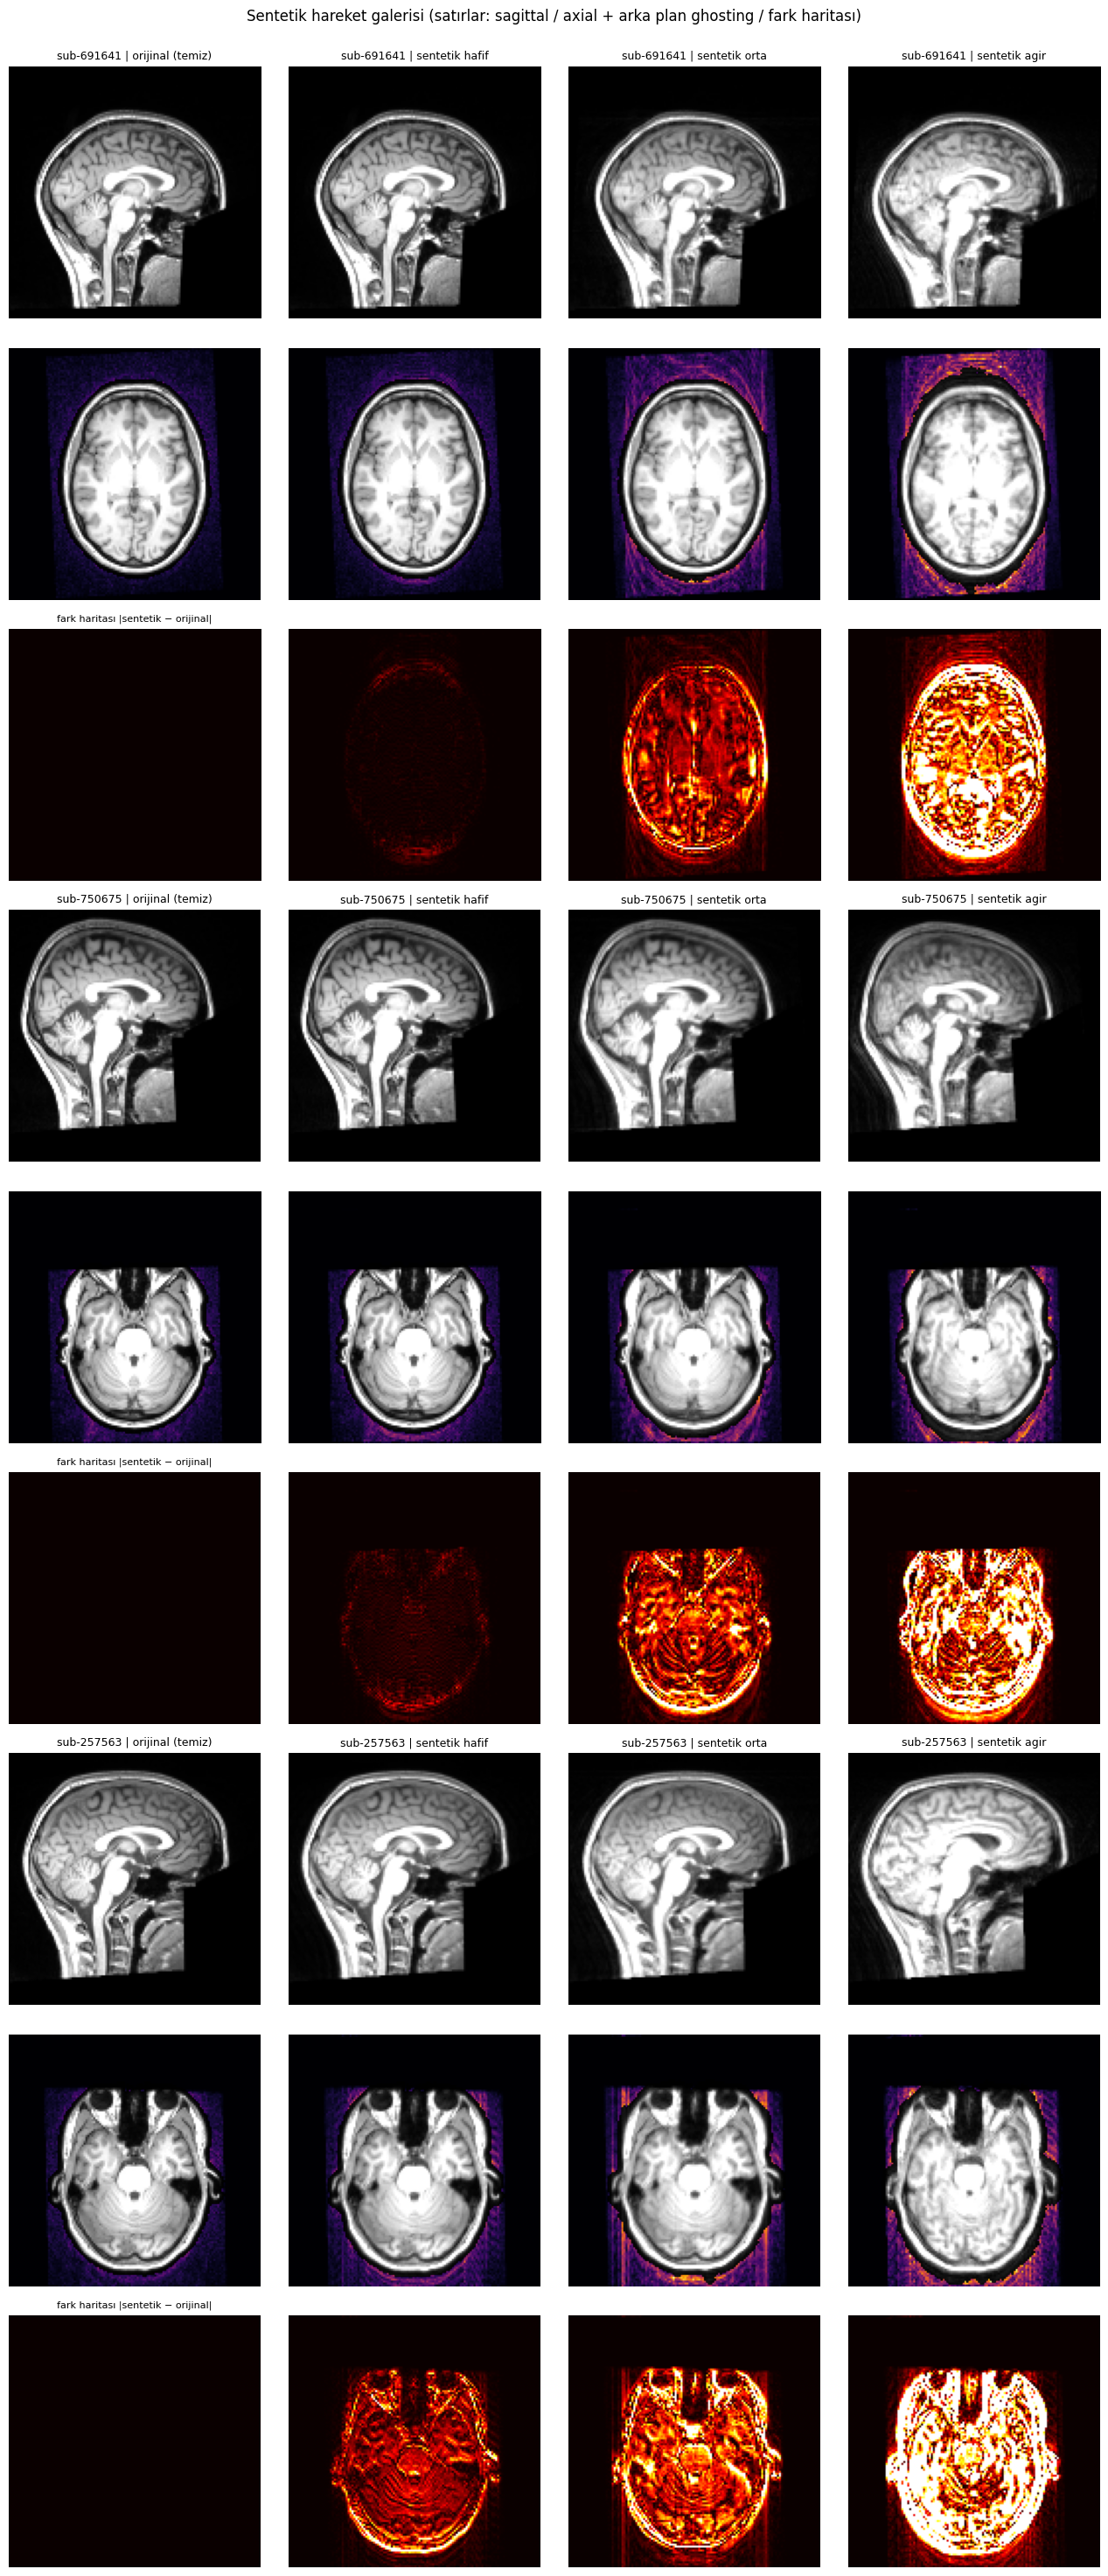

0/525
100/525
200/525
300/525
400/525
500/525

=== Sınıflandırıcı sentetik görüntüleri hangi sınıfa koyuyor? (satır yüzdesi) ===
 tahmin           iyi  orta  kötü
grup                            
temiz (kaynak)  1.00  0.00  0.00
sentetik hafif  0.56  0.44  0.00
sentetik orta   0.00  0.41  0.59
sentetik agir   0.00  0.00  1.00

=== Ortalama olasılıklar ===
                 p_iyi  p_orta  p_kotu
grup                                 
temiz (kaynak)  0.764   0.213   0.024
sentetik hafif  0.483   0.446   0.071
sentetik orta   0.043   0.452   0.505
sentetik agir   0.013   0.090   0.897


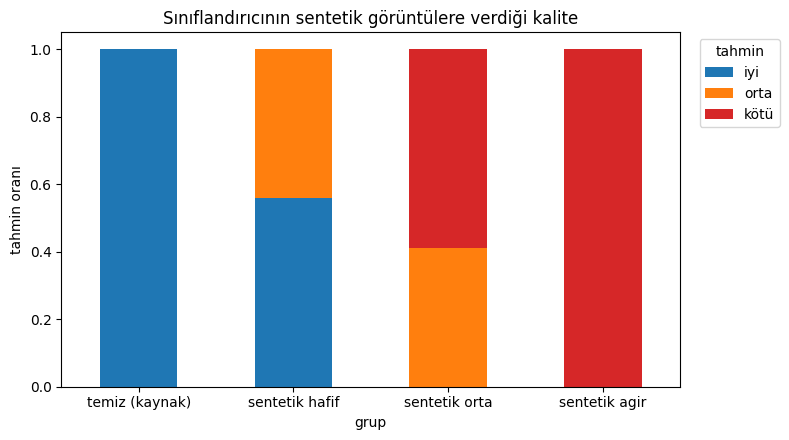

In [6]:
from google.colab import drive; drive.mount('/content/drive')
import numpy as np, pandas as pd, torch, torch.nn as nn, matplotlib.pyplot as plt
from torchvision.models.video import r3d_18
from scipy import ndimage

ROOT = '/content/drive/MyDrive/PIMI_MRART'; CACHE = f'{ROOT}/cache128'; SYN = f'{ROOT}/cache128_synth_v2'
dev = 'cuda'; LEV = ['hafif', 'orta', 'agir']; NAMES = ['iyi', 'orta', 'kötü']
meta = pd.read_csv(f'{ROOT}/results/synth_index_v2.csv')

def head_mask(v):
    m = ndimage.binary_fill_holes(ndimage.binary_closing(v > 0.06, iterations=3))
    lab, n = ndimage.label(m)
    if n > 1: m = lab == (np.argmax(np.bincount(lab.ravel())[1:]) + 1)
    return ndimage.binary_dilation(m, iterations=2)

# ================= 1) GALERİ =================
srcs = meta.source.drop_duplicates().sample(3, random_state=0).tolist()
fig, ax = plt.subplots(3 * len(srcs), 4, figsize=(13, 9.8 * len(srcs)))
for i, s in enumerate(srcs):
    orig = np.load(f'{CACHE}/{s}.npy').astype(np.float32)
    panels = [(orig, 'orijinal (temiz)')] + [(np.load(f'{SYN}/{s}_syn-{l}0.npy').astype(np.float32), f'sentetik {l}') for l in LEV]
    for j, (v, t) in enumerate(panels):
        r = 3 * i
        ax[r, j].imshow(np.rot90(v[64]), cmap='gray', vmax=0.7)
        ax[r, j].set_title(f'{s.split("_")[0]} | {t}', fontsize=9)
        sl, hm = v[:, :, 64], head_mask(v)[:, :, 64]
        ax[r + 1, j].imshow(np.rot90(sl), cmap='gray', vmax=0.7)
        ax[r + 1, j].imshow(np.ma.masked_where(np.rot90(hm), np.rot90(sl)), cmap='inferno', vmin=0, vmax=0.06)
        diff = np.abs(v[:, :, 64] - orig[:, :, 64])
        ax[r + 2, j].imshow(np.rot90(diff), cmap='hot', vmin=0, vmax=0.15)
        if j == 0: ax[r + 2, j].set_title('fark haritası |sentetik − orijinal|', fontsize=8)
        for a in ax[r:r + 3, j]: a.axis('off')
plt.suptitle('Sentetik hareket galerisi (satırlar: sagittal / axial + arka plan ghosting / fark haritası)', y=1.0)
plt.tight_layout(); plt.savefig(f'{ROOT}/figures/synth_gallery.png', dpi=120, bbox_inches='tight'); plt.show()

# ================= 2) SINIFLANDIRICI SENTETİKLERİ NASIL PUANLIYOR? =================
class Net(nn.Module):
    def __init__(s):
        super().__init__(); s.m = r3d_18(weights=None)
        s.m.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(512, 3))
    def forward(s, x): return s.m(x.repeat(1, 3, 1, 1, 1))

models = []
for c in ['r3d18_flip_rot90', 'r3d18_flip_rot90_s1', 'r3d18_flip_rot90_s2']:
    m = Net().to(dev); m.load_state_dict(torch.load(f'{ROOT}/models/{c}_best.pt', map_location=dev)); m.eval(); models.append(m)

items = [(s, f'{CACHE}/{s}.npy', 'temiz (kaynak)') for s in meta.source.unique()]
items += [(r.synth_name, f'{SYN}/{r.synth_name}.npy', f'sentetik {r.level}') for r in meta.itertuples()]
rows = []
with torch.no_grad():
    for k, (name, path, grp) in enumerate(items):
        x = torch.from_numpy(np.load(path).astype(np.float32))[None, None].to(dev)
        with torch.autocast('cuda', dtype=torch.float16):
            p = torch.stack([torch.softmax(m(x).float(), 1) for m in models]).mean(0)[0].cpu().numpy()
        rows.append({'name': name, 'grup': grp, 'p_iyi': p[0], 'p_orta': p[1], 'p_kotu': p[2], 'tahmin': NAMES[p.argmax()]})
        if k % 100 == 0: print(f'{k}/{len(items)}')
sc = pd.DataFrame(rows); sc.to_csv(f'{ROOT}/results/synth_scored_by_classifier.csv', index=False)

order = ['temiz (kaynak)', 'sentetik hafif', 'sentetik orta', 'sentetik agir']
tab = pd.crosstab(sc.grup, sc.tahmin, normalize='index').reindex(index=order, columns=NAMES).fillna(0).round(2)
print('\n=== Sınıflandırıcı sentetik görüntüleri hangi sınıfa koyuyor? (satır yüzdesi) ===\n', tab)
print('\n=== Ortalama olasılıklar ===\n', sc.groupby('grup')[['p_iyi', 'p_orta', 'p_kotu']].mean().reindex(order).round(3))

tab.plot.bar(stacked=True, color=['tab:blue', 'tab:orange', 'tab:red'], figsize=(8, 4.5), rot=0)
plt.ylabel('tahmin oranı'); plt.title('Sınıflandırıcının sentetik görüntülere verdiği kalite')
plt.legend(title='tahmin', bbox_to_anchor=(1.02, 1)); plt.tight_layout()
plt.savefig(f'{ROOT}/figures/synth_scored_by_classifier.png', dpi=150); plt.show()

In [7]:
from google.colab import drive; drive.mount('/content/drive')
import os, re, glob, shutil, json, subprocess, importlib.metadata as md
subprocess.run('pip -q install monai huggingface_hub xgboost nibabel', shell=True)

ROOT = '/content/drive/MyDrive/PIMI_MRART'
REPO_URL = 'https://github.com/zeynepceyhun152-code/mri-quality-assessment.git'
REPO = '/content/repo'; V2 = f'{REPO}/v2'

if os.path.exists(REPO): shutil.rmtree(REPO)
subprocess.run(f'git clone -q {REPO_URL} {REPO}', shell=True, check=True)
for d in ['notebooks', 'splits', 'results', 'figures']: os.makedirs(f'{V2}/{d}', exist_ok=True)

# 1) Split CSV + sonuç tabloları (küçük dosyalar) + figürler
shutil.copy(f'{ROOT}/splits/split_seed42.csv', f'{V2}/splits/')
for f in glob.glob(f'{ROOT}/results/*.csv') + glob.glob(f'{ROOT}/results/*.json'):
    shutil.copy(f, f'{V2}/results/')
for f in glob.glob(f'{ROOT}/figures/*.png'):
    shutil.copy(f, f'{V2}/figures/')

# 2) Notebook (ntfy konu adı temizlenerek)
nbs = glob.glob('/content/drive/MyDrive/Colab Notebooks/staj*.ipynb')
print('Bulunan notebook:', nbs)
if nbs:
    txt = open(nbs[0], encoding='utf-8').read()
    txt = re.sub(r"NTFY_TOPIC = 'YOUR-NTFY-TOPIC']*'", "NTFY_TOPIC = 'YOUR-NTFY-TOPIC'", txt)
    open(f'{V2}/notebooks/mrart_quality_v2.ipynb', 'w', encoding='utf-8').write(txt)

# 3) requirements.txt (bu ortamdaki gerçek sürümler)
reqs = []
for p in ['torch', 'torchvision', 'monai', 'numpy', 'pandas', 'scikit-learn', 'xgboost', 'nibabel',
          'scipy', 'matplotlib', 'huggingface_hub', 'awscli', 'requests']:
    try: reqs.append(f'{p}=={md.version(p)}')
    except md.PackageNotFoundError: pass
open(f'{V2}/requirements.txt', 'w').write('\n'.join(reqs) + '\n')

# 4) .gitignore
open(f'{V2}/.gitignore', 'w').write('*.npy\n*.pt\n*.pth\ncache*/\n__pycache__/\n')

# 5) README
README = r'''# MR-ART Image Quality Assessment — v2

Follow-up work after feedback from **Dr. İlkay Öksüz (PIMI Lab, ITU)** on my first submission (see the repository root for v1).
Task: predict the **3-level expert quality score** (1 = good, 2 = medium, 3 = bad) of T1-weighted brain MRI scans from the
[MR-ART dataset](https://openneuro.org/datasets/ds004173) (148 subjects, 436 scans).

Feedback addressed in this version:
1. **Data augmentation** (~4×) with transformations that do not change image quality (flips, 90°/180°/270° rotations)
2. **Understand the MRIQC features** the classical model relies on
3. **3D models** instead of 2.5D slices
4. **Literature review** of related challenges and papers
5. **Synthetic images generated by quality level**, following the k-space approach of Oksuz et al. (2019)

## Experimental design

| | |
|---|---|
| Split | Subject-level, `StratifiedGroupKFold`, seed 42 → 95 / 23 / 30 subjects (280 / 69 / 87 scans). No subject appears in two splits (asserted). See `splits/split_seed42.csv`. |
| Preprocessing | Reorient to RAS → divide by 99.5th percentile, clip to [0, 1] → zero-pad to a cube → resize to 128³ (2 mm isotropic). **No skull stripping** (the background carries the strongest artefact signal, see below). |
| Training | Class-weighted cross-entropy, AdamW (lr 1e-4), **early stopping** on validation balanced accuracy (patience 8), best-epoch checkpoint, left–right flip TTA at test time. |
| Augmentation | On-the-fly, train set only, 4 random views per scan per epoch. |
| Robustness | 3 seeds per configuration; subject-level paired bootstrap (2000×) for model comparison. |
| Metrics | Balanced accuracy, macro-F1, one-vs-rest AUROC, quadratic weighted kappa, per-class recall. |

## Results (test set: 87 scans / 30 subjects)

**Classical ML on 68 MRIQC features**

| Model | Bal. acc | Macro-F1 | AUROC | QW kappa |
|---|---|---|---|---|
| Logistic Regression | 0.708 | 0.699 | 0.866 | 0.808 |
| Random Forest | 0.756 | 0.748 | 0.897 | 0.841 |
| XGBoost | 0.717 | 0.707 | 0.897 | 0.818 |

RF 5-fold grouped CV on train+val: 0.769 ± 0.043. The most important features are **background statistics**
(`summary_bg_stdv`, `summary_bg_p95`): motion causes ghosting along the phase-encoding direction, which lands in the air around the head.

**3D CNN (r3d_18, Kinetics-400 pretrained) — augmentation ablation, mean ± std over 3 seeds**

| Augmentation | Bal. acc | QW kappa | AUROC |
|---|---|---|---|
| none | 0.792 ± 0.042 | 0.856 ± 0.043 | 0.911 ± 0.019 |
| flip | 0.791 ± 0.023 | 0.856 ± 0.026 | 0.903 ± 0.008 |
| **flip + rot90** | **0.813 ± 0.013** | **0.881 ± 0.009** | **0.929 ± 0.003** |

Augmentation mainly reduced seed-to-seed variance (~3×) and consistently raised AUROC; without it the model memorised the
training set (train accuracy > 95%).

**3D architecture comparison (flip + rot90)**

| Model | Pretraining | Bal. acc | QW kappa | AUROC |
|---|---|---|---|---|
| **r3d_18** | Kinetics-400 (video) | **0.813 ± 0.013** | **0.881 ± 0.009** | **0.929 ± 0.003** |
| MedicalNet ResNet-18 | 23 medical 3D datasets | 0.780 ± 0.052 | 0.844 ± 0.036 | 0.900 ± 0.018 |
| MedicalNet ResNet-18 + z-score input | 23 medical 3D datasets | 0.719 ± 0.039 | 0.806 ± 0.031 | 0.878 ± 0.016 |
| DenseNet121 (1 seed) | none | 0.761 | 0.828 | 0.889 |

**Ensembles and statistical comparison**

- Seed ensemble of r3d_18 (flip + rot90): bal. acc 0.818, kappa 0.883, AUROC 0.930.
- RF + CNN probability average: bal. acc 0.831, kappa 0.890 (exploratory — chosen after looking at the test set).
- CNN vs RF, paired bootstrap: Δ bal. acc = +0.055, 95% CI [−0.019, 0.128]; CNN better in 93% of resamples, **not significant at 95%**.
- Binary views for comparison with the literature: good vs medium+bad acc 0.897 / AUROC 0.948; good vs bad (medium removed) acc 0.984 / AUROC 0.999.

## Where does the model look? (occlusion test, 3-seed ensemble)

| Input | Bal. acc | QW kappa |
|---|---|---|
| Original | 0.827 | 0.891 |
| **Background removed (head only)** | **0.509** | 0.414 |
| Head removed (background only) | 0.704 | 0.612 |
| Lower face / defacing region removed | 0.818 | 0.883 |

Both the MRIQC model and the CNN rely mostly on **ghosting in the air around the head**. This is a physical signature of motion,
but it is also a generalisation risk (e.g., scanners that mask the background or skull-stripped data).

## Error analysis — the "medium" class

- 6 of the 7 test scans acquired **without instructed motion** (`standard`) but rated **medium** by the expert were predicted "good".
- Their MRIQC features also lie at the clean end of the medium class.
- In the CNN embedding space (t-SNE + class templates, inspired by AutoMAC-MRI), **24 of 26** such scans (train + test) sit in the
  "good" cluster — even though 19 of them were seen with the "medium" label during training.
- Interpretation (hypothesis): the expert score may reflect factors other than motion, or label ambiguity at the class boundary.

## Synthetic images generated by quality level (k-space, after Oksuz et al. 2019)

Clean training scans are corrupted in k-space: the head follows a random-walk rigid trajectory (pitch rotation + 3D translation)
and k-space lines along the A–P phase-encoding axis acquired after motion onset are taken from the moved image. Severity is
controlled by the number of segments and step size (*mild / moderate / severe*). Defacing is re-applied after simulation.
Only **training** subjects are used as sources (75 clean scans → 450 synthetic volumes).

Validation — the trained classifier grades the generated images monotonically with the requested severity:

| Generated | pred. good | pred. medium | pred. bad |
|---|---|---|---|
| clean source | 100% | 0% | 0% |
| synthetic mild | 56% | 44% | 0% |
| synthetic moderate | 0% | 41% | 59% |
| synthetic severe | 0% | 0% | 100% |

Background statistics of the synthetic levels also fall between/on the real classes (e.g., severe: bg_p95 0.0183 vs real "bad" 0.0182).

Using the synthetic data for **pretraining** (4-class severity task, then fine-tuning on real data):

| | Bal. acc | QW kappa | AUROC | Medium recall |
|---|---|---|---|---|
| Baseline (3 seeds) | 0.813 ± 0.013 | 0.881 ± 0.009 | 0.929 | 0.564 |
| Synthetic + curriculum (2 seeds) | 0.793 ± 0.033 | 0.861 ± 0.014 | 0.926 | 0.577 |
| Synthetic + random order (2 seeds) | 0.822 ± 0.006 | 0.887 ± 0.006 | 0.910 | 0.577 |

Pretraining sped up fine-tuning but did not meaningfully change final performance or medium-class recall; curriculum did not beat random order on this dataset.

## Limitations
- Small test set (30 subjects); several differences are within seed variance or bootstrap CIs.
- Single subject-level split for deep models (no nested CV).
- 2 mm resolution may hide subtle in-brain blurring.
- Grad-CAM on r3d_18 is coarse (≈16×8×8 grid); the occlusion test is the stronger evidence.
- Synthetic motion: magnitude-only simulation, linear k-space ordering, pitch rotation + translation only.

## Repository contents
- `notebooks/mrart_quality_v2.ipynb` — all code (Google Colab, A100)
- `splits/split_seed42.csv` — subject-level split
- `results/` — metrics (`*_metrics.json`), per-scan predictions, comparison tables
- `figures/` — all figures
- Large files (cached volumes, model weights) are not included.

## How to run
1. Open the notebook in Google Colab (GPU runtime; A100 recommended — T4 is ~6× slower for 3D training).
2. `pip install -r requirements.txt`
3. Run the cells in order; the first cell downloads MR-ART from OpenNeuro to Google Drive.

## Use of AI tools
I used **Claude (Anthropic)** extensively as a coding and research assistant: writing and debugging code, suggesting experiment
designs and analyses, and literature search. I ran all experiments in Colab, checked the outputs, and made the decisions on what to
run next and how to report the results. _[Edit this section so it accurately describes your own contribution.]_

## References
- Nárai et al., *Movement-related artefacts (MR-ART) dataset*, Scientific Data 2022.
- Esteban et al., *MRIQC*, PLoS ONE 2017.
- Oksuz et al., *Automatic CNN-based detection of cardiac MR motion artefacts using k-space data augmentation and curriculum learning*, Medical Image Analysis 2019.
- Wang et al., *CMRxMotion challenge results*, arXiv:2507.19165.
- Vakli et al., *Automatic brain MRI motion artifact detection based on end-to-end deep learning is similarly effective as traditional machine learning trained on image quality metrics*, Medical Image Analysis 2023.
- Jerald et al., *AutoMAC-MRI*, arXiv:2512.15315.
- Tran et al., *A closer look at spatiotemporal convolutions* (r3d_18), CVPR 2018; Chen et al., *MedicalNet*, 2019.
'''
open(f'{V2}/README.md', 'w', encoding='utf-8').write(README)

# 6) Kök README'ye v2 bağlantısı ekle
root_readme = f'{REPO}/README.md'
note = '\n\n## v2 (after PIMI Lab feedback)\nSee [`v2/`](v2/) for augmentation, 3D models, error analysis and quality-controlled synthetic images.\n'
if os.path.exists(root_readme) and 'v2/' not in open(root_readme, encoding='utf-8').read():
    open(root_readme, 'a', encoding='utf-8').write(note)

# 7) Kontrol: dosyalar ve boyutlar
print('\n=== v2/ içeriği ===')
total = 0
for dp, _, fs in os.walk(V2):
    for f in sorted(fs):
        p = os.path.join(dp, f); sz = os.path.getsize(p); total += sz
        flag = '  ⚠ 50MB üstü!' if sz > 50e6 else ''
        print(f'{p.replace(REPO + "/", ""):70s} {sz/1e6:7.2f} MB{flag}')
print(f'Toplam: {total/1e6:.1f} MB')
print('\nrequirements.txt:\n' + open(f'{V2}/requirements.txt').read())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Bulunan notebook: []

=== v2/ içeriği ===
v2/.gitignore                                                             0.00 MB
v2/README.md                                                              0.01 MB
v2/requirements.txt                                                       0.00 MB
v2/figures/affinity_violins.png                                           0.08 MB
v2/figures/augmentation_examples.png                                      0.10 MB
v2/figures/cache_check_sub-000103.png                                     0.24 MB
v2/figures/feature_importance.png                                         0.09 MB
v2/figures/gradcam_cases.png                                              1.05 MB
v2/figures/gradcam_mean.png                                               0.11 MB
v2/figures/hard_cases.png                                                 1.10 MB
v2/figure